# ADIMA — Whisper Attention-Pooled Hard-Negative SupCon | New Notebook

This notebook keeps the existing ADIMA few-shot protocol, acoustic branch, cross-language positive weighting, and top-k hard-negative SupCon objective. The representation change is **Whisper frame-wise L2 normalization → learned temporal attention pooling** instead of simple mean pooling.

The attention pooling module is trained on support samples only and is reused unchanged for query/test inference. Raw Whisper frame representations are cached per audio file so the attention layer can be learned during each few-shot episode.

Main comparison: `Whisper mean pooling + Hard-SupCon` vs `Whisper attention pooling + Hard-SupCon`.


# ADIMA — Whisper Attention-Pooled Hard-Negative SupCon + ECAPA Leakage Control

This is a **new controlled experiment notebook** based on the existing ADIMA Whisper + Hard-Negative SupCon pipeline.

### Only the temporal pooling is changed

**Previous:** Whisper frame representations → frame L2 normalization → mean pooling → SupCon projection → hard-negative SupCon → classifier.

**This notebook:** Whisper frame representations → frame L2 normalization → **learned temporal attention pooling** → SupCon projection → hard-negative SupCon → classifier.

Whisper remains frozen. The attention pooling module is trained using **support data only**. Acoustic features, cross-language positive weighting, hard-negative mining, classifier adaptation, shot sizes, and evaluation are kept otherwise unchanged.

The attention mechanism is a lightweight additive scorer: \(s_t = W_2	anh(W_1h_t)\), \(lpha_t=softmax(s_t)\), and \(z=\sum_tlpha_th_t\). Temporal sequences are reduced to at most 32 bins before attention for memory efficiency.

This makes the experiment directly comparable with the mean-pooling Hard-SupCon baseline.

### Leakage-control protocol

Before Whisper extraction and before `EpisodeSampler` is constructed, the retained training pool is kept unchanged while the test set is screened with speech-only ECAPA. Test recordings with maximum train similarity ≥ 0.85 are excluded from the primary evaluation set. Unscreened test recordings are reported separately.


In [1]:
# ═══════════════════════════════════════════════════════════════════════════

import os
import copy
import json
import random
import time
import warnings
from pathlib import Path
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple
from abc import ABC, abstractmethod

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.optim.lr_scheduler import LinearLR
from torch.utils.data import TensorDataset, DataLoader

import torchaudio
import librosa
import librosa.display
import soundfile as sf

from transformers import (
    WhisperModel,
    WhisperFeatureExtractor,
)

from IPython.display import Audio, display

# MAML differentiable optimization
import higher

warnings.filterwarnings("ignore")

print("=" * 70)
print("ENVIRONMENT")
print("=" * 70)
print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
    print(
        f"GPU memory      : "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )
else:
    print("GPU             : CPU")

print("=" * 70)
# ═══════════════════════════════════════════════════════════════════════════
# CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════


MODE = "MODE_2"



MODE_2_HEAD = "SupContrastHardNegative"
POOLING_TYPE = "temporal_attention"

PROJECT_DIR = Path(r"D:\SEM_7\SpeechProc\PRoject")

ADIMA_ROOT = PROJECT_DIR/"data"

AUDIO_DIR = ADIMA_ROOT / "audios"
ANNOTATION_DIR = ADIMA_ROOT / "annotations"

EMBEDDING_CACHE = PROJECT_DIR / "embeddings_cache"
RESULTS_DIR = PROJECT_DIR / "results"
PLOTS_DIR = PROJECT_DIR / "plots"

EMBEDDING_CACHE.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


HUGGINGFACE_CACHE = PROJECT_DIR / "models" / "huggingface"
HUGGINGFACE_CACHE.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(HUGGINGFACE_CACHE)
os.environ["HUGGINGFACE_HUB_CACHE"] = str(HUGGINGFACE_CACHE / "hub")
os.environ["TRANSFORMERS_CACHE"] = str(HUGGINGFACE_CACHE / "transformers")
os.environ["HF_DATASETS_CACHE"] = str(HUGGINGFACE_CACHE / "datasets")

print(f"HuggingFace cache : {HUGGINGFACE_CACHE}")



LANGUAGES = [
    "Bengali",
    "Bhojpuri",
    "Gujarati",
    "Haryanvi",
    "Hindi",
    "Kannada",
    "Malayalam",
    "Odia",
    "Punjabi",
    "Tamil",
]

NUM_LANGUAGES = len(LANGUAGES)



LANG_TO_AUDIO_DIR = {
    "Bengali":   "SC_audio_Bengali",
    "Bhojpuri":  "SC_audio_Bhojpuri",
    "Gujarati":  "SC_audio_Gujarati",
    "Haryanvi":  "SC_audio_Haryanvi",
    "Hindi":     "SC_audio_Hindi",
    "Kannada":   "SC_audio_Kannada",
    "Malayalam": "SC_audio_Malayalam",
    "Odia":      "SC_audio_Odia",
    "Punjabi":   "SC_audio_Punjabi",
    "Tamil":     "SC_audio_Tamil",
}



LABEL_MAP = {

    "Yes": 1,


    "No": 0,
}

ENCODER_TYPE = "whisper"
ENCODER_MODEL_ID = "openai/whisper-medium"

WHISPER_DIM = 1024

SAMPLE_RATE = 16000

# ═══════════════════════════════════════════════════════════════════════════
# ACOUSTIC FEATURE CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════
ACOUSTIC_FEATURE_VERSION = "acoustic_controlled_v2"

ACOUSTIC_CACHE_DIR = (
    PROJECT_DIR / "acoustic_features_cache"
)
ACOUSTIC_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------------------------
# FULL ACOUSTIC REPRESENTATION
# ---------------------------------------------------------------------------

FULL_ACOUSTIC_DIM = 52


ACOUSTIC_FEATURE_FRACTION =1
# ---------------------------------------------------------------------------
# ACOUSTIC FEATURE GROUPS
# ---------------------------------------------------------------------------

ACOUSTIC_GROUPS = {
    "waveform_spectral": list(range(0, 16)),   # 16
    "mfcc":              list(range(16, 42)),  # 26
    "f0":                list(range(42, 48)),  # 6
    "energy":            list(range(48, 52)),  # 4
}

# These are calculated AFTER feature selection.
ACOUSTIC_DIM = None
COMBINED_DIM = None




NORM_STRATEGY = "l2_norm"


ANN_HIDDEN_1 = 256
ANN_HIDDEN_2 = 128
ANN_OUTPUT = 2

NUM_CLASSES = 2




BATCH_SIZE = 128

EPOCHS = 150

LEARNING_RATE = 0.001

META_LR = 0.001

INNER_STEPS = 5
INNER_LR = 1e-3
META_STEP = 0.05
EPOCHS = 100
BATCH_SIZE = 64

SHOT_SIZES = [50, 100, 150, 200]


SHOT_K = 50



RUN_ALL_SHOTS = True




RUN_TSNE = True


TSNE_MAX_SAMPLES = None

TSNE_PERPLEXITY = 30
TSNE_ITERATIONS = 1000


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


SUPCON_TEMPERATURE = 0.07
SUPCON_PROJECTION_DIM = 128

SUPCON_EPOCHS = 60

SUPCON_CLASSIFIER_EPOCHS = 50

SUPCON_BATCH_SIZE = 128

# ═══════════════════════════════════════════════════════════════════════════
# HARD-NEGATIVE SUPERVISED CONTRASTIVE LEARNING
# ═══════════════════════════════════════════════════════════════════════════
#
# Hard negatives MUST have the opposite class label but high similarity to
# the anchor. Same-class cross-language examples remain POSITIVES.
#
# This implementation is a deterministic top-k hard-negative approximation
# to hard-SCL / hard-negative SupCon. All valid negatives remain in the
# denominator; the selected top-k negatives receive extra weight. This is
# intentionally more stable than discarding every easy negative.

HARD_NEGATIVE_ENABLED = True
HARD_NEGATIVE_TOP_K = 4
HARD_NEGATIVE_WEIGHT = 0.5
HARD_NEGATIVE_TEMPERATURE = 0.06
HARD_NEGATIVE_WARMUP_EPOCHS = 10

# ---------------------------------------------------------------------------
# ATTENTION-POOLING EXPERIMENT
# ---------------------------------------------------------------------------
ATTENTION_POOLING_ENABLED = True
ATTENTION_HIDDEN_DIM = 128
ATTENTION_BINS = 64
ATTENTION_DROPOUT = 0.10

# ---------------------------------------------------------------------------
# GATED MULTIMODAL FUSION
# ---------------------------------------------------------------------------
# Whisper and acoustic branches are projected separately, then a learned
# gate decides how much of each modality to retain for every sample.
GATED_FUSION_ENABLED = True
WHISPER_PROJ_DIM = 256
ACOUSTIC_PROJ_DIM = 64
GATED_FUSION_DIM = 256
GATED_FUSION_HIDDEN_DIM = 128
GATED_FUSION_DROPOUT = 0.10





print("=" * 70)
print("CONFIGURATION")
print("=" * 70)

print(f"Mode                : {MODE}")

if MODE == "MODE_2":
    print(f"Extension head      : {MODE_2_HEAD}")

print(f"Encoder             : {ENCODER_MODEL_ID}")
print(f"Feature dimension   : {WHISPER_DIM}")
print(f"Normalization       : {NORM_STRATEGY}")
print(f"Languages            : {NUM_LANGUAGES}")
print(f"Shot sizes           : {SHOT_SIZES}")
print(f"Batch size            : {BATCH_SIZE}")
print(f"Epochs                : {EPOCHS}")
print(f"Inner LR              : {INNER_LR}")
print(f"Meta LR               : {META_LR}")
print(f"Inner steps           : {INNER_STEPS}")
print(f"Device                : {DEVICE}")
print(f"Run all shots        : {RUN_ALL_SHOTS}")
print("=" * 70)
# ═══════════════════════════════════════════════════════════════════════════
class ADIMADataset:

    def __init__(
        self,
        audio_dir: Path,
        annotation_dir: Path,
        languages: List[str],
        lang_to_audio_dir: Dict[str, str],
        label_map: Dict[str, int],
    ):

        self.audio_dir = audio_dir
        self.annotation_dir = annotation_dir
        self.languages = languages
        self.lang_to_audio_dir = lang_to_audio_dir
        self.label_map = label_map

        self.samples = []

        self._load_all()


    def _resolve_label(self, value):

        if pd.isna(value):
            return -1

        raw = str(value).strip()
        normalized = raw.lower()

   
        for key, value_int in self.label_map.items():

            if normalized == key.lower():
                return value_int

     
        try:
            numeric = int(float(raw))

            if numeric in [0, 1]:
                return numeric

        except Exception:
            pass

        return -1


    def _infer_label_from_filename(self, filename):

        stem = Path(filename).stem.lower()

        if stem.startswith("abuse"):
            return 1, "Abuse"

        if stem.startswith("abusive"):
            return 1, "Abusive"

        if stem.startswith("normal"):
            return 0, "Normal"

        if stem.startswith("non-abuse"):
            return 0, "Non-Abuse"

        if stem.startswith("non_abuse"):
            return 0, "Non-Abuse"

        if stem.startswith("non-abusive"):
            return 0, "Non-Abusive"

        return -1, "Unknown"



    def _find_filename_column(self, df):

        normalized = {
            str(c).strip().lower(): c
            for c in df.columns
        }

        candidates = [
            "filename",
            "file",
            "audio",
            "audio_file",
            "audio_filename",
            "name",
            "path",
        ]

        for candidate in candidates:

            if candidate in normalized:
                return normalized[candidate]

       
        return df.columns[0]


    def _find_label_column(self, df):

        normalized = {
            str(c).strip().lower(): c
            for c in df.columns
        }

        candidates = [
            "label",
            "class",
            "category",
            "annotation",
            "target",
        ]

        for candidate in candidates:

            if candidate in normalized:
                return normalized[candidate]

        return None




    def _load_csv(self, language, split):

        csv_path = (
            self.annotation_dir /
            f"{language}_{split}.csv"
        )

        if not csv_path.exists():

            raise FileNotFoundError(
                f"Missing annotation file: {csv_path}"
            )

        df = pd.read_csv(csv_path)

        df.columns = [
            str(c).strip()
            for c in df.columns
        ]

        return df


    
    def _load_all(self):

        missing_audio = []

        for language in self.languages:

            language_audio_dir = (
                self.audio_dir /
                self.lang_to_audio_dir[language]
            )

            if not language_audio_dir.exists():

                raise FileNotFoundError(
                    f"Audio directory missing: "
                    f"{language_audio_dir}"
                )

            for split in ["train", "test"]:

                df = self._load_csv(
                    language,
                    split
                )

                filename_col = (
                    self._find_filename_column(df)
                )

                label_col = (
                    self._find_label_column(df)
                )

                for _, row in df.iterrows():

                    filename = str(
                        row[filename_col]
                    ).strip()

             
                    filename = Path(filename).name

                    if not filename.lower().endswith(".wav"):
                        filename += ".wav"

                    filepath = (
                        language_audio_dir /
                        filename
                    )

                    if not filepath.exists():

                        missing_audio.append(
                            str(filepath)
                        )
                        continue

                    
                    if label_col is not None:

                        label = self._resolve_label(
                            row[label_col]
                        )

                        label_str = str(
                            row[label_col]
                        )

                    else:

                        label, label_str = (
                            self._infer_label_from_filename(
                                filename
                            )
                        )

                    if label not in [0, 1]:

                        print(
                            f"[WARNING] Unable to resolve "
                            f"label: {filepath}"
                        )

                        continue

                    self.samples.append({

                        "language": language,

                        "split": split,

                        "filename": filename,

                        "filepath": filepath,

                        "label": int(label),

                        "label_str": label_str,

                    })

        if missing_audio:

            print(
                f"\n[WARNING] "
                f"{len(missing_audio)} audio files were missing."
            )

            for path in missing_audio[:10]:

                print(
                    f"  {path}"
                )


    def to_dataframe(self):

        return pd.DataFrame(
            self.samples
        )


    def get_split(self, split):

        return [
            sample
            for sample in self.samples
            if sample["split"] == split
        ]


    def get_language(
        self,
        language,
        split=None
    ):

        result = [
            sample
            for sample in self.samples
            if sample["language"] == language
        ]

        if split is not None:

            result = [
                sample
                for sample in result
                if sample["split"] == split
            ]

        return result


    def summary(self):

        df = self.to_dataframe()

        rows = []

        for language in self.languages:

            for split in ["train", "test"]:

                sub = df[
                    (df["language"] == language) &
                    (df["split"] == split)
                ]

                rows.append({

                    "Language": language,

                    "Split": split,

                    "Abusive":
                        int((sub["label"] == 1).sum()),

                    "Non-Abusive":
                        int((sub["label"] == 0).sum()),

                    "Total":
                        len(sub),
                })

        return pd.DataFrame(rows)




print("=" * 70)
print("LOADING ADIMA DATASET")
print("=" * 70)

dataset = ADIMADataset(
    audio_dir=AUDIO_DIR,
    annotation_dir=ANNOTATION_DIR,
    languages=LANGUAGES,
    lang_to_audio_dir=LANG_TO_AUDIO_DIR,
    label_map=LABEL_MAP,
)

df_all = dataset.to_dataframe()

print(
    f"\nTotal samples loaded : {len(df_all)}"
)

print(
    f"Train samples        : "
    f"{len(dataset.get_split('train'))}"
)

print(
    f"Test samples         : "
    f"{len(dataset.get_split('test'))}"
)

print(
    f"Languages             : "
    f"{sorted(df_all['language'].unique())}"
)

print("\nDataset distribution:")
display(
    dataset.summary()
)

# ═══════════════════════════════════════════════════════════════════════════
# ═══════════════════════════════════════════════════════════════════════════
#
# ═══════════════════════════════════════════════════════════════════════════

from pathlib import Path
from collections import defaultdict
import hashlib

import numpy as np
import pandas as pd
import librosa
from tqdm.auto import tqdm


# ═══════════════════════════════════════════════════════════════════════════
# 1. CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════

AUDIO_QUALITY_DIR = (
    PROJECT_DIR / "audio_quality_audit"
)

AUDIO_QUALITY_DIR.mkdir(
    parents=True,
    exist_ok=True
)



SILENCE_THRESHOLD = 1e-5
RMS_THRESHOLD = 1e-5
STD_THRESHOLD = 1e-5

ZERO_FRACTION_THRESHOLD = 0.995



# ═══════════════════════════════════════════════════════════════════════════
# 2. MD5 HASH FUNCTION
# ═══════════════════════════════════════════════════════════════════════════

def md5_file(
    filepath,
    chunk_size=1024 * 1024
):

    md5 = hashlib.md5()

    with open(
        filepath,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            md5.update(
                chunk
            )

    return md5.hexdigest()



# ═══════════════════════════════════════════════════════════════════════════
# 3. AUDIO QUALITY CHECK
# ═══════════════════════════════════════════════════════════════════════════

def check_audio_quality(filepath):

    result = {

        "filepath":
            str(filepath),

        "status":
            "OK",

        "reason":
            "",

        "sample_rate":
            None,

        "duration_sec":
            None,

        "max_amplitude":
            None,

        "rms":
            None,

        "std":
            None,

        "zero_fraction":
            None,

        "md5":
            None,
    }


    # -----------------------------------------------------------------------
    # FILE EXISTENCE
    # -----------------------------------------------------------------------

    if not filepath.exists():

        result["status"] = "INVALID"
        result["reason"] = "FILE_NOT_FOUND"

        return result


    # -----------------------------------------------------------------------
    # FILE SIZE
    # -----------------------------------------------------------------------

    try:

        file_size = (
            filepath.stat().st_size
        )

    except Exception:

        result["status"] = "INVALID"
        result["reason"] = "FILE_ACCESS_ERROR"

        return result


    if file_size == 0:

        result["status"] = "INVALID"
        result["reason"] = "EMPTY_FILE"

        return result


    # -----------------------------------------------------------------------
    # MD5
    #
    # Used only to detect exact duplicate audio content.
    # -----------------------------------------------------------------------

    try:

        result["md5"] = md5_file(
            filepath
        )

    except Exception:

        result["status"] = "INVALID"
        result["reason"] = "MD5_ERROR"

        return result


    # -----------------------------------------------------------------------
    # LOAD AUDIO
    # -----------------------------------------------------------------------

    try:

        waveform, sr = librosa.load(
            str(filepath),
            sr=None,
            mono=True
        )

    except Exception:

        result["status"] = "INVALID"
        result["reason"] = "UNREADABLE_AUDIO"

        return result


    # -----------------------------------------------------------------------
    # EMPTY WAVEFORM
    # -----------------------------------------------------------------------

    if (
        waveform is None
        or len(waveform) == 0
    ):

        result["status"] = "INVALID"
        result["reason"] = "EMPTY_WAVEFORM"

        return result


    # -----------------------------------------------------------------------
    # NaN / INF
    # -----------------------------------------------------------------------

    if not np.isfinite(
        waveform
    ).all():

        result["status"] = "INVALID"
        result["reason"] = "NAN_OR_INF"

        return result


    # -----------------------------------------------------------------------
    # Convert to float64 for stable statistics
    # -----------------------------------------------------------------------

    waveform = waveform.astype(
        np.float64
    )


    # -----------------------------------------------------------------------
    # BASIC SIGNAL STATISTICS
    # -----------------------------------------------------------------------

    max_amplitude = float(
        np.max(
            np.abs(waveform)
        )
    )

    rms = float(
        np.sqrt(
            np.mean(
                np.square(
                    waveform
                )
            )
        )
    )

    std = float(
        np.std(
            waveform
        )
    )

    zero_fraction = float(
        np.mean(
            np.abs(waveform)
            <= SILENCE_THRESHOLD
        )
    )

    duration_sec = float(
        len(waveform) / sr
    )


    result["sample_rate"] = sr
    result["duration_sec"] = duration_sec
    result["max_amplitude"] = max_amplitude
    result["rms"] = rms
    result["std"] = std
    result["zero_fraction"] = zero_fraction


    # ═══════════════════════════════════════════════════════════════════════
    # SILENT / FLAT TESTS
    # ═══════════════════════════════════════════════════════════════════════

    is_silent = (
        max_amplitude
        <= SILENCE_THRESHOLD
    )

    is_low_rms = (
        rms
        <= RMS_THRESHOLD
    )

    is_flat = (
        std
        <= STD_THRESHOLD
    )

    mostly_zero = (
        zero_fraction
        >= ZERO_FRACTION_THRESHOLD
    )


    # ═══════════════════════════════════════════════════════════════════════
    # FINAL QUALITY DECISION
    # ═══════════════════════════════════════════════════════════════════════

    if is_silent:

        result["status"] = "REMOVE"
        result["reason"] = "SILENT"

    elif is_flat:

        result["status"] = "REMOVE"
        result["reason"] = "FLAT"

    elif is_low_rms:

        result["status"] = "REMOVE"
        result["reason"] = "VERY_LOW_RMS"

    elif mostly_zero:

        result["status"] = "REMOVE"
        result["reason"] = "MOSTLY_ZERO"

    else:

        result["status"] = "OK"
        result["reason"] = "VALID_AUDIO"


    return result



# ═══════════════════════════════════════════════════════════════════════════
# 4. CHECK ONLY DATASET SAMPLES
# ═══════════════════════════════════════════════════════════════════════════
#
# IMPORTANT:
# Do NOT use rglob("*.wav") here.
#
# We use dataset.samples because those are the files actually present in
# the ADIMA annotations and therefore actually belong to the experiment.
#
# ═══════════════════════════════════════════════════════════════════════════

print("\n")
print("=" * 80)
print("ADIMA AUDIO QUALITY AUDIT")
print("=" * 80)

print(
    f"Dataset samples to check : "
    f"{len(dataset.samples)}"
)


quality_records = []


for sample in tqdm(
    dataset.samples,
    desc="Checking audio quality"
):

    result = check_audio_quality(
        sample["filepath"]
    )

    # -----------------------------------------------------------------------
    # Attach ADIMA metadata
    # -----------------------------------------------------------------------

    result["language"] = (
        sample["language"]
    )

    result["split"] = (
        sample["split"]
    )

    result["filename"] = (
        sample["filename"]
    )

    result["label"] = (
        sample["label"]
    )

    result["label_str"] = (
        sample["label_str"]
    )

    quality_records.append(
        result
    )


quality_df = pd.DataFrame(
    quality_records
)



# ═══════════════════════════════════════════════════════════════════════════
# 5. QUALITY SUMMARY
# ═══════════════════════════════════════════════════════════════════════════

valid_count = int(
    (
        quality_df["status"]
        == "OK"
    ).sum()
)

removed_count = int(
    (
        quality_df["status"]
        == "REMOVE"
    ).sum()
)

invalid_count = int(
    (
        quality_df["status"]
        == "INVALID"
    ).sum()
)


print("\n")
print("=" * 80)
print("AUDIO QUALITY SUMMARY")
print("=" * 80)

print(
    f"Total checked : {len(quality_df)}"
)

print(
    f"Valid audio   : {valid_count}"
)

print(
    f"Silent/flat   : {removed_count}"
)

print(
    f"Invalid       : {invalid_count}"
)


print("\nRemoval / invalid reasons:")

reason_counts = (
    quality_df[
        quality_df["status"]
        != "OK"
    ]["reason"]
    .value_counts()
)

display(
    reason_counts.to_frame(
        "Count"
    )
)



# ═══════════════════════════════════════════════════════════════════════════
# 6. SAVE QUALITY AUDIT
# ════════════════════════════════════════



import librosa
import numpy as np
import pandas as pd
from tqdm.auto import tqdm


print("=" * 70)
print("ADIMA DATASET AUDIO STATISTICS")
print("=" * 70)



# 1. COMPUTE AUDIO STATISTICS FOR EVERY FILE

audio_stats = []

print("\nScanning all audio files...")

for sample in tqdm(
    dataset.samples,
    desc="Analyzing audio"
):

    filepath = sample["filepath"]

    try:

      
        y, sr = librosa.load(
            filepath,
            sr=None,
            mono=True
        )

        duration = len(y) / sr

        audio_stats.append({

            "Language": sample["language"],

            "Split": sample["split"],

            "Label": (
                "Abusive"
                if sample["label"] == 1
                else "Non-Abusive"
            ),

            "Filename": sample["filename"],

            "Duration": duration,

            "SampleRate": sr,

        })

    except Exception as e:

        print(
            f"[WARNING] Could not read: "
            f"{filepath}\n"
            f"Reason: {e}"
        )


audio_stats_df = pd.DataFrame(audio_stats)


print(
    f"\nSuccessfully analyzed "
    f"{len(audio_stats_df)} / "
    f"{len(dataset.samples)} audio files."
)

# 2. OVERALL DATASET STATISTICS


print("\n" + "=" * 70)
print("OVERALL DATASET AUDIO STATISTICS")
print("=" * 70)


overall_duration = pd.DataFrame({

    "Statistic": [
        "Number of Samples",
        "Mean Duration (s)",
        "Std Duration (s)",
        "Minimum Duration (s)",
        "Median Duration (s)",
        "Maximum Duration (s)",
        "Mean Sample Rate (Hz)",
        "Minimum Sample Rate (Hz)",
        "Maximum Sample Rate (Hz)",
        "Unique Sample Rates",
    ],

    "Value": [

        len(audio_stats_df),

        audio_stats_df["Duration"].mean(),

        audio_stats_df["Duration"].std(),

        audio_stats_df["Duration"].min(),

        audio_stats_df["Duration"].median(),

        audio_stats_df["Duration"].max(),

        audio_stats_df["SampleRate"].mean(),

        audio_stats_df["SampleRate"].min(),

        audio_stats_df["SampleRate"].max(),

        sorted(
            audio_stats_df["SampleRate"]
            .unique()
            .tolist()
        ),
    ]
})


# Round numerical values

overall_duration["Value"] = (
    overall_duration["Value"]
    .apply(
        lambda x:
        round(x, 3)
        if isinstance(x, (float, np.floating))
        else x
    )
)


display(overall_duration)



# 3. PER-LANGUAGE AUDIO STATISTICS


print("\n" + "=" * 70)
print("AUDIO STATISTICS BY LANGUAGE")
print("=" * 70)


language_audio_stats = (
    audio_stats_df
    .groupby("Language")
    .agg(

        Samples=("Duration", "count"),

        Mean_Duration_s=("Duration", "mean"),

        Std_Duration_s=("Duration", "std"),

        Min_Duration_s=("Duration", "min"),

        Median_Duration_s=("Duration", "median"),

        Max_Duration_s=("Duration", "max"),

        Mean_SampleRate_Hz=("SampleRate", "mean"),

    )
    .reset_index()
)


language_audio_stats = (
    language_audio_stats
    .round(3)
)


display(language_audio_stats)



# 4. LANGUAGE + SPLIT STATISTICS


print("\n" + "=" * 70)
print("AUDIO STATISTICS BY LANGUAGE AND SPLIT")
print("=" * 70)


language_split_stats = (
    audio_stats_df
    .groupby(
        ["Language", "Split"]
    )
    .agg(

        Samples=("Duration", "count"),

        Mean_Duration_s=("Duration", "mean"),

        Std_Duration_s=("Duration", "std"),

        Min_Duration_s=("Duration", "min"),

        Median_Duration_s=("Duration", "median"),

        Max_Duration_s=("Duration", "max"),

        Mean_SampleRate_Hz=("SampleRate", "mean"),

    )
    .reset_index()
    .round(3)
)


display(language_split_stats)


# 5. LABEL-WISE DURATION STATISTICS


print("\n" + "=" * 70)
print("AUDIO STATISTICS BY LABEL")
print("=" * 70)


label_audio_stats = (
    audio_stats_df
    .groupby("Label")
    .agg(

        Samples=("Duration", "count"),

        Mean_Duration_s=("Duration", "mean"),

        Std_Duration_s=("Duration", "std"),

        Min_Duration_s=("Duration", "min"),

        Median_Duration_s=("Duration", "median"),

        Max_Duration_s=("Duration", "max"),

    )
    .reset_index()
    .round(3)
)


display(label_audio_stats)



# 6. DATASET-WIDE SAMPLE RATE CHECK


print("\n" + "=" * 70)
print("SAMPLE RATE CHECK")
print("=" * 70)


sample_rate_counts = (
    audio_stats_df["SampleRate"]
    .value_counts()
    .sort_index()
    .reset_index()
)

sample_rate_counts.columns = [
    "Sample Rate (Hz)",
    "Number of Files"
]


display(sample_rate_counts)


# 7. DURATION OUTLIER CHECK

print("\n" + "=" * 70)
print("DURATION RANGE CHECK")
print("=" * 70)


q1 = audio_stats_df["Duration"].quantile(0.25)
q3 = audio_stats_df["Duration"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr


duration_outliers = audio_stats_df[
    (audio_stats_df["Duration"] < lower_bound) |
    (audio_stats_df["Duration"] > upper_bound)
].copy()


print(f"Q1                 : {q1:.3f} s")
print(f"Q3                 : {q3:.3f} s")
print(f"IQR                : {iqr:.3f} s")
print(f"Lower bound        : {lower_bound:.3f} s")
print(f"Upper bound        : {upper_bound:.3f} s")
print(
    f"Potential outliers : "
    f"{len(duration_outliers)}"
)


if len(duration_outliers) > 0:

    display(
        duration_outliers[
            [
                "Language",
                "Split",
                "Label",
                "Filename",
                "Duration",
                "SampleRate",
            ]
        ]
        .sort_values(
            "Duration"
        )
        .head(20)
    )



#8. AUDIO DATASET SANITY CHECK


print("\n" + "=" * 70)
print("AUDIO DATASET SANITY CHECK")
print("=" * 70)



unique_rates = (
    audio_stats_df["SampleRate"]
    .unique()
)


if len(unique_rates) == 1:

    print(
        f"All audio files use "
        f"{unique_rates[0]} Hz."
    )

else:

    print(
        f" Multiple sample rates detected: "
        f"{sorted(unique_rates)}"
    )


# Duration

if audio_stats_df["Duration"].min() > 0:

    print(
        "All successfully loaded files "
        "have positive duration."
    )

else:

    print(
        " Zero-duration audio files detected."
    )



failed_files = (
    len(dataset.samples)
    - len(audio_stats_df)
)


if failed_files == 0:

    print(
        "All dataset audio files were "
        "successfully analyzed."
    )

else:

    print(
        f"{failed_files} audio files "
        f"could not be analyzed."
    )


print("\n" + "=" * 70)
print("AUDIO STATISTICS COMPLETE")
print("=" * 70)
# ═══════════════════════════════════════════════════════════════════════════
# FINAL CLEAN TRAIN / TEST MANIFESTS
# ═══════════════════════════════════════════════════════════════════════════
# No audio files are deleted from disk.
# 1) Keep only status == OK (non-silent, non-flat, readable audio).
# 2) For exact TRAIN <-> TEST MD5 duplicates, remove only TEST copies.
# 3) Keep TRAIN copies.
# 4) Duplicates within the same split are retained.
# ═══════════════════════════════════════════════════════════════════════════

CLEANING_VERSION = "clean_v2_non_silent_non_flat_train_kept_test_duplicates_removed"

quality_lookup = {
    str(row["filepath"]): row
    for _, row in quality_df.iterrows()
}

all_train_samples = dataset.get_split("train")
all_test_samples = dataset.get_split("test")

final_train_samples = [
    s for s in all_train_samples
    if quality_lookup[str(s["filepath"])] ["status"] == "OK"
]

final_test_candidates = [
    s for s in all_test_samples
    if quality_lookup[str(s["filepath"])] ["status"] == "OK"
]

train_md5_to_samples = defaultdict(list)
test_md5_to_samples = defaultdict(list)

for s in final_train_samples:
    md5 = quality_lookup[str(s["filepath"])] ["md5"]
    if md5:
        train_md5_to_samples[md5].append(s)

for s in final_test_candidates:
    md5 = quality_lookup[str(s["filepath"])] ["md5"]
    if md5:
        test_md5_to_samples[md5].append(s)

common_md5 = sorted(
    set(train_md5_to_samples) & set(test_md5_to_samples)
)

removed_test_paths = set()
duplicate_records = []

for md5 in common_md5:
    for train_sample in train_md5_to_samples[md5]:
        for test_sample in test_md5_to_samples[md5]:
            test_path = str(test_sample["filepath"])
            removed_test_paths.add(test_path)
            duplicate_records.append({
                "md5": md5,
                "train_language": train_sample["language"],
                "train_filename": train_sample["filename"],
                "train_filepath": str(train_sample["filepath"]),
                "train_label": train_sample["label"],
                "test_language": test_sample["language"],
                "test_filename": test_sample["filename"],
                "test_filepath": test_path,
                "test_label": test_sample["label"],
                "action": "REMOVE_TEST_COPY_KEEP_TRAIN_COPY",
            })

final_test_samples = [
    s for s in final_test_candidates
    if str(s["filepath"]) not in removed_test_paths
]

# Save audit/manifests.
quality_audit_path = AUDIO_QUALITY_DIR / "audio_quality_audit.csv"
quality_df.to_csv(quality_audit_path, index=False)

duplicate_columns = [
    "md5", "train_language", "train_filename", "train_filepath",
    "train_label", "test_language", "test_filename", "test_filepath",
    "test_label", "action",
]
duplicate_df = pd.DataFrame(duplicate_records, columns=duplicate_columns)
duplicate_path = AUDIO_QUALITY_DIR / "train_test_exact_duplicates_removed.csv"
duplicate_df.to_csv(duplicate_path, index=False)

def samples_to_dataframe(samples):
    return pd.DataFrame([
        {
            "language": s["language"],
            "split": s["split"],
            "filename": s["filename"],
            "filepath": str(s["filepath"]),
            "label": s["label"],
            "label_str": s["label_str"],
        }
        for s in samples
    ])

final_train_df = samples_to_dataframe(final_train_samples)
final_test_df = samples_to_dataframe(final_test_samples)
final_train_path = AUDIO_QUALITY_DIR / "final_clean_train.csv"
final_test_path = AUDIO_QUALITY_DIR / "final_clean_test.csv"
final_train_df.to_csv(final_train_path, index=False)
final_test_df.to_csv(final_test_path, index=False)

# Integrity checks.
train_paths = {str(s["filepath"]) for s in final_train_samples}
test_paths = {str(s["filepath"]) for s in final_test_samples}
assert train_paths.isdisjoint(test_paths), "Path overlap remains between train/test."

final_train_md5 = {
    quality_lookup[str(s["filepath"])] ["md5"]
    for s in final_train_samples
    if quality_lookup[str(s["filepath"])] ["md5"]
}
final_test_md5 = {
    quality_lookup[str(s["filepath"])] ["md5"]
    for s in final_test_samples
    if quality_lookup[str(s["filepath"])] ["md5"]
}
assert final_train_md5.isdisjoint(final_test_md5), (
    "Exact train/test duplicate remains after cleaning."
)

print("\n" + "=" * 80)
print("FINAL CLEAN DATASET")
print("=" * 80)
print(f"Original train samples                 : {len(all_train_samples)}")
print(f"Original test samples                  : {len(all_test_samples)}")
print(f"Clean train samples                    : {len(final_train_samples)}")
print(f"Clean test candidates                  : {len(final_test_candidates)}")
print(f"Exact train/test duplicate MD5 groups : {len(common_md5)}")
print(f"Test files removed as duplicates       : {len(removed_test_paths)}")
print(f"Final test samples                     : {len(final_test_samples)}")
print(f"Quality audit                          : {quality_audit_path}")
print(f"Duplicate audit                        : {duplicate_path}")
print(f"Final train manifest                   : {final_train_path}")
print(f"Final test manifest                    : {final_test_path}")

display(final_train_df.groupby(["language", "label"]).size().unstack(fill_value=0))
display(final_test_df.groupby(["language", "label"]).size().unstack(fill_value=0))


# ═══════════════════════════════════════════════════════════════════════════
# ================================================================
# EXACT FILES EXCLUDED BY AUDIO QUALITY / DUPLICATE CRITERIA
# ================================================================

import pandas as pd
from pathlib import Path

print("\n" + "=" * 100)
print("EXACT EXCLUDED FILES — AUDIO QUALITY + DUPLICATES")
print("=" * 100)

# ---------------------------------------------------------------
# 1. AUDIO QUALITY EXCLUSIONS
# ---------------------------------------------------------------

# These are files that were NOT status == OK.
quality_excluded = quality_df[
    quality_df["status"] != "OK"
].copy()

print("\n" + "-" * 100)
print("1. AUDIO QUALITY EXCLUSIONS")
print("-" * 100)

print(f"Total quality-excluded files : {len(quality_excluded)}")

if len(quality_excluded) > 0:

    # Show count by reason
    print("\nExclusion counts by reason:")
    display(
        quality_excluded["reason"]
        .value_counts()
        .rename_axis("Reason")
        .to_frame("Count")
    )

    # Exact files
    print("\nExact files excluded:")
    
    quality_excluded_display = quality_excluded[
        [
            "filename",
            "filepath",
            "language",
            "split",
            "label_str",
            "status",
            "reason",
            "duration_sec",
            "max_amplitude",
            "rms",
            "std",
            "zero_fraction",
            "md5",
        ]
    ].sort_values(
        ["reason", "split", "language", "filename"]
    )

    display(quality_excluded_display)

else:
    print("No audio files were excluded by the quality criteria.")


# ---------------------------------------------------------------
# 2. EXACT TRAIN <-> TEST DUPLICATES
# ---------------------------------------------------------------

print("\n" + "-" * 100)
print("2. EXACT TRAIN <-> TEST DUPLICATES")
print("-" * 100)

print(
    f"Exact train/test duplicate records : {len(duplicate_df)}"
)

if len(duplicate_df) > 0:

    print(
        "\nThese are exact MD5 matches between a TRAIN file "
        "and a TEST file."
    )

    print(
        "Action taken: REMOVE TEST COPY / KEEP TRAIN COPY"
    )

    duplicate_display = duplicate_df[
        [
            "md5",
            "train_language",
            "train_filename",
            "train_filepath",
            "train_label",
            "test_language",
            "test_filename",
            "test_filepath",
            "test_label",
            "action",
        ]
    ].sort_values(
        ["md5", "train_filename", "test_filename"]
    )

    display(duplicate_display)

else:
    print("No exact train/test MD5 duplicates found.")


# ---------------------------------------------------------------
# 3. FINAL SUMMARY
# ---------------------------------------------------------------

print("\n" + "=" * 100)
print("EXCLUSION SUMMARY")
print("=" * 100)

print(
    f"Original train samples             : {len(all_train_samples)}"
)
print(
    f"Original test samples              : {len(all_test_samples)}"
)

print(
    f"\nQuality exclusions from train      : "
    f"{sum(quality_excluded['split'].str.lower() == 'train')}"
)

print(
    f"Quality exclusions from test       : "
    f"{sum(quality_excluded['split'].str.lower() == 'test')}"
)

print(
    f"Exact train/test duplicate groups  : {len(common_md5)}"
)

print(
    f"Test files removed due to duplicate: "
    f"{len(removed_test_paths)}"
)

print(
    f"\nFinal clean train samples          : "
    f"{len(final_train_samples)}"
)

print(
    f"Final clean test samples           : "
    f"{len(final_test_samples)}"
)


# ---------------------------------------------------------------
# 4. SEPARATE TABLES FOR EACH QUALITY REASON
# ---------------------------------------------------------------

print("\n" + "=" * 100)
print("FILES BY INDIVIDUAL QUALITY CRITERION")
print("=" * 100)

quality_reasons = [
    "SILENT",
    "FLAT",
    "VERY_LOW_RMS",
    "MOSTLY_ZERO",
    "FILE_NOT_FOUND",
    "FILE_ACCESS_ERROR",
    "EMPTY_FILE",
    "MD5_ERROR",
    "UNREADABLE_AUDIO",
    "EMPTY_WAVEFORM",
    "NAN_OR_INF",
]

for reason in quality_reasons:

    subset = quality_df[
        quality_df["reason"] == reason
    ].copy()

    print(f"\n### {reason}: {len(subset)} file(s)")

    if len(subset) > 0:

        display(
            subset[
                [
                    "filename",
                    "filepath",
                    "language",
                    "split",
                    "label_str",
                    "duration_sec",
                    "max_amplitude",
                    "rms",
                    "std",
                    "zero_fraction",
                    "md5",
                ]
            ].sort_values(
                ["split", "language", "filename"]
            )
        )


# ---------------------------------------------------------------
# 5. SAVE A SINGLE COMPLETE EXCLUSION REPORT
# ---------------------------------------------------------------

excluded_quality_export = quality_excluded.copy()

excluded_quality_export["exclusion_type"] = "AUDIO_QUALITY"

duplicate_export = duplicate_df.copy()

if len(duplicate_export) > 0:
    duplicate_export["exclusion_type"] = "TRAIN_TEST_EXACT_DUPLICATE"

# Save separately because their columns are different
quality_exclusion_report_path = (
    AUDIO_QUALITY_DIR / "EXACT_AUDIO_QUALITY_EXCLUSIONS.csv"
)

duplicate_exclusion_report_path = (
    AUDIO_QUALITY_DIR / "EXACT_TRAIN_TEST_DUPLICATES.csv"
)

excluded_quality_export.to_csv(
    quality_exclusion_report_path,
    index=False
)

duplicate_export.to_csv(
    duplicate_exclusion_report_path,
    index=False
)

print("\nReports saved:")
print(
    f"Quality exclusions : {quality_exclusion_report_path}"
)
print(
    f"Train/test duplicates: {duplicate_exclusion_report_path}"
)
# ═══════════════════════════════════════════════════════════════════
# TEMPORARY MANUAL EXCLUSION
# Exclude ONLY:
# D:\SEM_7\SpeechProc\PRoject\data\audios\
#     SC_audio_Bhojpuri\Abuse_216.wav
#
# The original WAV is NOT deleted.
# ═══════════════════════════════════════════════════════════════════

EXCLUDED_FILENAME = "Abuse_216.wav"
EXCLUDED_FOLDER = "SC_audio_Bhojpuri"


def is_excluded_file(sample):

    filepath = Path(sample["filepath"])

    return (
        filepath.name.lower() == EXCLUDED_FILENAME.lower()
        and
        filepath.parent.name.lower() == EXCLUDED_FOLDER.lower()
    )


print("\n" + "=" * 80)
print("MANUAL FILE EXCLUSION")
print("=" * 80)


# ---------------------------------------------------------------
# Find exact file in current manifests
# ---------------------------------------------------------------

found_exclusions = []

for sample in final_train_samples + final_test_samples:

    if is_excluded_file(sample):

        found_exclusions.append({
            "language": sample["language"],
            "split": sample["split"],
            "filename": sample["filename"],
            "filepath": str(sample["filepath"]),
            "label": sample["label"],
            "label_str": sample["label_str"],
        })


print("\nFiles found for exclusion:")

if found_exclusions:

    exclusion_df = pd.DataFrame(found_exclusions)
    display(exclusion_df)

else:

    print("WARNING: Abuse_216.wav was NOT found.")
    print("\nChecking filename/path directly...")

    # Diagnostic search
    for sample in final_train_samples + final_test_samples:

        filepath = Path(sample["filepath"])

        if filepath.name.lower() == "abuse_216.wav":

            print(
                "FOUND BY FILENAME:"
            )

            print(
                "Language:",
                sample["language"]
            )

            print(
                "Split:",
                sample["split"]
            )

            print(
                "Path:",
                filepath
            )


# ---------------------------------------------------------------
# Apply exclusion
# ---------------------------------------------------------------

before_train = len(final_train_samples)
before_test = len(final_test_samples)


final_train_samples = [
    s for s in final_train_samples
    if not is_excluded_file(s)
]


final_test_samples = [
    s for s in final_test_samples
    if not is_excluded_file(s)
]


# ---------------------------------------------------------------
# Rebuild manifests
# ---------------------------------------------------------------

final_train_df = samples_to_dataframe(
    final_train_samples
)

final_test_df = samples_to_dataframe(
    final_test_samples
)


final_train_path = (
    AUDIO_QUALITY_DIR / "final_clean_train.csv"
)

final_test_path = (
    AUDIO_QUALITY_DIR / "final_clean_test.csv"
)


final_train_df.to_csv(
    final_train_path,
    index=False
)

final_test_df.to_csv(
    final_test_path,
    index=False
)


# ---------------------------------------------------------------
# Invalidate old embedding cache
# ---------------------------------------------------------------

CLEANING_VERSION = (
    "clean_v3_exclude_SC_audio_Bhojpuri_Abuse_216"
)


# ---------------------------------------------------------------
# VERIFY
# ---------------------------------------------------------------

remaining_excluded = [
    s
    for s in (
        final_train_samples +
        final_test_samples
    )
    if is_excluded_file(s)
]


assert len(remaining_excluded) == 0, (
    "ERROR: Abuse_216.wav is still present!"
)


# ---------------------------------------------------------------
# FINAL REPORT
# ---------------------------------------------------------------

print("\n" + "=" * 80)
print("EXCLUSION APPLIED")
print("=" * 80)

print(
    f"Train before : {before_train}"
)

print(
    f"Train after  : {len(final_train_samples)}"
)

print(
    f"Test before  : {before_test}"
)

print(
    f"Test after   : {len(final_test_samples)}"
)

print(
    "\nExcluded:"
    " SC_audio_Bhojpuri/Abuse_216.wav"
)

print(
    "Original file deleted:"
    " NO"
)

print(
    "File excluded from experiment:"
    " YES"
)

print(
    "\nCLEANING_VERSION:"
)

print(CLEANING_VERSION)


# ---------------------------------------------------------------
# CHECK THAT IT IS REALLY GONE
# ---------------------------------------------------------------

print("\nVerification:")

print(
    "Abuse_216.wav remaining in train:",
    sum(
        Path(s["filepath"]).name.lower()
        == "abuse_216.wav"
        for s in final_train_samples
    )
)

print(
    "Abuse_216.wav remaining in test:",
    sum(
        Path(s["filepath"]).name.lower()
        == "abuse_216.wav"
        for s in final_test_samples
    )
)
# ═══════════════════════════════════════════════════════════════════════════

class WhisperFeatureExtractorClass:

    def __init__(
        self,
        model_id=ENCODER_MODEL_ID,
        device=DEVICE,
    ):

        self.model_id = model_id
        self.device = device

        print("=" * 70)
        print(f"Loading Whisper model: {model_id}")
        print("=" * 70)

        self.processor = (
            WhisperFeatureExtractor.from_pretrained(
                model_id,
                cache_dir=str(HUGGINGFACE_CACHE),
            )
        )

        self.model = (
            WhisperModel.from_pretrained(
                model_id,
                cache_dir=str(HUGGINGFACE_CACHE),
            )
            .to(device)
        )

        self.model.eval()

        print(
    f"Whisper encoder dimension: "
    f"{self.model.config.d_model}"
)

        print(
            f"Configured dimension     : "
            f"{WHISPER_DIM}"
        )

        if self.model.config.d_model != WHISPER_DIM:

            raise RuntimeError(
                "Whisper dimension mismatch!\n"
                f"Model config: {self.model.config.d_model}\n"
                f"WHISPER_DIM : {WHISPER_DIM}"
            )


    # -----------------------------------------------------------------------
    # RAW AUDIO → WHISPER ENCODER
    # -----------------------------------------------------------------------

    @torch.no_grad()
    def extract_raw(
        self,
        filepath: Path,
    ):

        waveform, sr = librosa.load(
            str(filepath),
            sr=SAMPLE_RATE,
            mono=True,
        )

        inputs = self.processor(
            waveform,
            sampling_rate=SAMPLE_RATE,
            return_tensors="pt",
        )

        input_features = (
            inputs["input_features"]
            .to(self.device)
        )

        encoder_output = (
            self.model.encoder(
                input_features
            )
        )

        return encoder_output.last_hidden_state


 

    def normalize_temporal_mean(
        self,
        hidden,
    ):

        frames = hidden.squeeze(0)

        return frames.mean(
            dim=0
        )



    def normalize_l2_norm(
        self,
        hidden,
    ):

        frames = hidden.squeeze(0)

        norms = (
            frames.norm(
                dim=-1,
                keepdim=True
            )
            .clamp(min=1e-8)
        )

        normalized = (
            frames / norms
        )

        return normalized.mean(
            dim=0
        )



    def normalize(
        self,
        hidden,
        strategy,
    ):

        if strategy == "l2_norm":

            embedding = (
                self.normalize_l2_norm(
                    hidden
                )
            )

        elif strategy == "temporal_mean":

            embedding = (
                self.normalize_temporal_mean(
                    hidden
                )
            )

        else:

            raise ValueError(
                f"Unknown normalization: {strategy}"
            )

        return (
            embedding
            .cpu()
            .float()
            .numpy()
        )




    def extract(
        self,
        filepath,
        strategy=NORM_STRATEGY,
    ):

        hidden = self.extract_raw(
            filepath
        )

        return self.normalize(
            hidden,
            strategy
        )



def extract_embeddings_for_samples(
    extractor,
    samples,
    split_name,
    strategy=NORM_STRATEGY,
):



    model_tag = (
        ENCODER_MODEL_ID
        .replace("/", "_")
        .replace("-", "_")
    )

    cache_file = (
        EMBEDDING_CACHE /
        f"{model_tag}_{split_name}_{strategy}.npz"
    )

    metadata_file = (
        EMBEDDING_CACHE /
        f"{model_tag}_{split_name}_{strategy}.json"
    )



    if (
        cache_file.exists()
        and metadata_file.exists()
    ):

        print(
            f"\n[CACHE] Found cached embeddings for "
            f"{ENCODER_MODEL_ID}"
        )

        with open(
            metadata_file,
            "r"
        ) as f:

            metadata = json.load(f)

        cached_dim = metadata.get(
            "embedding_dim"
        )

        cached_model = metadata.get(
            "model_id"
        )

        cached_strategy = metadata.get(
            "normalization"
        )

        cached_cleaning_version = metadata.get("cleaning_version")
        cached_sample_paths = metadata.get("sample_paths")
        current_sample_paths = [str(sample["filepath"]) for sample in samples]

        cache_valid = True

        if cached_model != ENCODER_MODEL_ID:

            print(
                f"[CACHE INVALID] Model mismatch:"
            )

            print(
                f"  Cache : {cached_model}"
            )

            print(
                f"  Current: {ENCODER_MODEL_ID}"
            )

            cache_valid = False


        if cached_dim != WHISPER_DIM:

            print(
                f"[CACHE INVALID] Dimension mismatch:"
            )

            print(
                f"  Cache : {cached_dim}"
            )

            print(
                f"  Current: {WHISPER_DIM}"
            )

            cache_valid = False


        if cached_strategy != strategy:

            print(
                f"[CACHE INVALID] "
                f"Normalization mismatch:"
            )

            print(
                f"  Cache : {cached_strategy}"
            )

            print(
                f"  Current: {strategy}"
            )

            cache_valid = False




        if cached_cleaning_version != CLEANING_VERSION:
            print("[CACHE INVALID] Cleaning-version mismatch.")
            print(f"  Cache : {cached_cleaning_version}")
            print(f"  Current: {CLEANING_VERSION}")
            cache_valid = False

        if cached_sample_paths != current_sample_paths:
            print("[CACHE INVALID] Sample manifest mismatch.")
            print(f"  Cached samples : {0 if cached_sample_paths is None else len(cached_sample_paths)}")
            print(f"  Current samples: {len(current_sample_paths)}")
            cache_valid = False

        if cache_valid:

            cached = np.load(
                cache_file
            )

            embeddings = cached[
                "embeddings"
            ]

            labels = cached[
                "labels"
            ]

            language_ids = cached[
                "lang_ids"
            ]

            if embeddings.shape[1] != WHISPER_DIM:

                raise RuntimeError(
                    f"Cache dimension is "
                    f"{embeddings.shape[1]}, "
                    f"but current model expects "
                    f"{WHISPER_DIM}."
                )

            print(
                f"[CACHE] Valid cache loaded."
            )

            print(
                f"[CACHE] Shape: "
                f"{embeddings.shape}"
            )

            return (
                embeddings,
                labels,
                language_ids,
                metadata["filenames"],
                metadata["languages"],
            )

        else:

            print(
                "[CACHE] Existing cache is invalid."
            )

            print(
                "[CACHE] Re-extracting embeddings..."
            )
   
    print()
    print("=" * 70)
    print(
        f"EXTRACTING ALL {split_name.upper()} EMBEDDINGS"
    )
    print("=" * 70)

    print(
        f"Samples : {len(samples)}"
    )

    embeddings = []
    labels = []
    language_ids = []
    filenames = []
    languages = []

    language_to_id = {
        lang: idx
        for idx, lang in enumerate(
            LANGUAGES
        )
    }

    start_time = time.time()

    for i, sample in enumerate(samples):

        try:

            embedding = extractor.extract(
                sample["filepath"],
                strategy,
            )

            embeddings.append(
                embedding
            )

            labels.append(
                sample["label"]
            )

            language_ids.append(
                language_to_id[
                    sample["language"]
                ]
            )

            filenames.append(
                sample["filename"]
            )

            languages.append(
                sample["language"]
            )

        except Exception as e:

            print(
                f"\n[ERROR] "
                f"{sample['filepath']}"
            )

            print(
                f"        {e}"
            )

            continue
        if (
            (i + 1) % 25 == 0
            or i == len(samples) - 1
        ):

            elapsed = (
                time.time()
                - start_time
            )

            rate = (
                (i + 1) / elapsed
                if elapsed > 0
                else 0
            )

            remaining = (
                len(samples) - (i + 1)
            )

            eta = (
                remaining / rate
                if rate > 0
                else 0
            )

            print(
                f"\r[{i+1:5d}/{len(samples)}] "
                f"{100*(i+1)/len(samples):6.2f}% | "
                f"{rate:.2f} files/s | "
                f"ETA {eta/60:.1f} min",
                end="",
            )

    print()

    if len(embeddings) == 0:

        raise RuntimeError(
            f"No embeddings extracted "
            f"for {split_name}."
        )

    embeddings = np.stack(
        embeddings
    ).astype(
        np.float32
    )

    labels = np.asarray(
        labels,
        dtype=np.int64
    )

    language_ids = np.asarray(
        language_ids,
        dtype=np.int64
    )



    np.savez_compressed(
        cache_file,
        embeddings=embeddings,
        labels=labels,
        lang_ids=language_ids,
    )

    with open(
        metadata_file,
        "w"
    ) as f:

        json.dump(
            {
                "filenames": filenames,
                "languages": languages,
                "sample_paths": [str(sample["filepath"]) for sample in samples],
                "cleaning_version": CLEANING_VERSION,
            },
            f,
            indent=2,
        )

    print(
        f"\n[CACHE] Saved: "
        f"{cache_file}"
    )

    return (
        embeddings,
        labels,
        language_ids,
        filenames,
        languages,
    )







C:\Users\ALIENWARE\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ENVIRONMENT
PyTorch version : 2.6.0+cu124
CUDA available  : True
GPU             : NVIDIA GeForce RTX 4060 Laptop GPU
GPU memory      : 8.00 GB
HuggingFace cache : D:\SEM_7\SpeechProc\PRoject\models\huggingface
CONFIGURATION
Mode                : MODE_2
Extension head      : SupContrastHardNegative
Encoder             : openai/whisper-medium
Feature dimension   : 1024
Normalization       : l2_norm
Languages            : 10
Shot sizes           : [50, 100, 150, 200]
Batch size            : 64
Epochs                : 100
Inner LR              : 0.001
Meta LR               : 0.001
Inner steps           : 5
Device                : cuda
Run all shots        : True
LOADING ADIMA DATASET

Total samples loaded : 11775
Train samples        : 8128
Test samples         : 3647
Languages             : ['Bengali', 'Bhojpuri', 'Gujarati', 'Haryanvi', 'Hindi', 'Kannada', 'Malayalam', 'Odia', 'Punjabi', 'Tamil']

Dataset distribution:


,Language,Split,Abusive,Non-Abusive,Total
0,Bengali,train,428,394,822
1,Bengali,test,222,148,370
2,Bhojpuri,train,506,253,759
3,Bhojpuri,test,214,122,336
4,Gujarati,train,301,516,817
5,Gujarati,test,107,255,362
6,Haryanvi,train,399,419,818
7,Haryanvi,test,173,193,366
8,Hindi,train,373,449,822
9,Hindi,test,183,186,369




ADIMA AUDIO QUALITY AUDIT
Dataset samples to check : 11775


Checking audio quality: 100%|██████████| 11775/11775 [00:58<00:00, 200.37it/s]

...


### FLAT: 4 file(s)


,filename,filepath,language,split,label_str,duration_sec,max_amplitude,rms,std,zero_fraction,md5
7011,Abuse_1156.wav,D:\SEM_7\SpeechProc\PRoject\data\audios\SC_aud...,Kannada,test,No,16.704000,0.000031,4.610465e-07,4.609939e-07,0.999772,a389162acebbe425a7a1d6a907a7f068
1337,Abuse_215.wav,D:\SEM_7\SpeechProc\PRoject\data\audios\SC_aud...,Bhojpuri,train,No,18.538688,0.000031,4.230464e-07,4.230113e-07,0.999808,750daf7f96cdd89d9caf7bbefdbcd95e
8348,Abuse_172.wav,D:\SEM_7\SpeechProc\PRoject\data\audios\SC_aud...,Odia,train,No,16.469313,0.000061,4.032100e-07,4.032076e-07,0.999860,1c5bf70a46b06343f724a0634b27ad9d
11073,Abuse_705.wav,D:\SEM_7\SpeechProc\PRoject\data\audios\SC_aud...,Tamil,train,No,15.104000,0.000153,6.142049e-06,6.123225e-06,0.992676,d076746168b58346e31cdd26613c7756



### VERY_LOW_RMS: 0 file(s)

### MOSTLY_ZERO: 2 file(s)


,filename,filepath,language,split,label_str,duration_sec,max_amplitude,rms,std,zero_fraction,md5
10428,Abuse_709.wav,D:\SEM_7\SpeechProc\PRoject\data\audios\SC_aud...,Punjabi,test,No,15.018688,0.104126,0.001846,0.001846,0.996142,f12c31c2b8dfe92065e7f238391cd426
4054,Abuse_859.wav,D:\SEM_7\SpeechProc\PRoject\data\audios\SC_aud...,Haryanvi,train,No,14.997312,0.000671,0.000014,0.000014,0.997212,f87738e7f635b90c3d341a13e3dd6a25



### FILE_NOT_FOUND: 0 file(s)

### FILE_ACCESS_ERROR: 0 file(s)

### EMPTY_FILE: 0 file(s)

### MD5_ERROR: 0 file(s)

### UNREADABLE_AUDIO: 0 file(s)

### EMPTY_WAVEFORM: 0 file(s)

### NAN_OR_INF: 0 file(s)

Reports saved:
Quality exclusions : D:\SEM_7\SpeechProc\PRoject\audio_quality_audit\EXACT_AUDIO_QUALITY_EXCLUSIONS.csv
Train/test duplicates: D:\SEM_7\SpeechProc\PRoject\audio_quality_audit\EXACT_TRAIN_TEST_DUPLICATES.csv

MANUAL FILE EXCLUSION

Files found for exclusion:

Checking filename/path directly...
FOUND BY FILENAME:
Language: Bengali
Split: train
Path: D:\SEM_7\SpeechProc\PRoject\data\audios\SC_audio_Bengali\Abuse_216.wav
FOUND BY FILENAME:
Language: Haryanvi
Split: train
Path: D:\SEM_7\SpeechProc\PRoject\data\audios\SC_audio_Haryanvi\Abuse_216.wav
FOUND BY FILENAME:
Language: Hindi
Split: train
Path: D:\SEM_7\SpeechProc\PRoject\data\audios\SC_audio_Hindi\Abuse_216.wav
FOUND BY FILENAME:
Language: Kannada
Split: train
Path: D:\SEM_7\SpeechProc\PRoject\data\audios\SC_aud

# ADIMA — Speaker-Leakage Control Before Few-Shot Sampling

This stage is inserted **after the existing exact-MD5 cleaning and before Whisper embedding extraction / few-shot sampling**.

**Training data are NOT removed.** The complete cleaned training pool is retained so that 50/100/150/200-shot support sampling does not suffer data starvation.

Instead, the test set is screened against the retained training pool using the already-computed **speech-only ECAPA** embeddings. Test recordings with strong train/test similarity are excluded from the primary evaluation set and retained in a separate audit table.

Thresholds are used as conservative **candidate-overlap screening**, not as proof of speaker identity:

- `>= 0.95`: high-confidence overlap candidate
- `0.90–0.95`: strong overlap candidate
- `0.85–0.90`: review candidate

The primary experiment uses the **ECAPA-screened clean test set**. The full cleaned training pool is passed unchanged to `EpisodeSampler` later in the notebook.

In [2]:
# ============================================================
# SPEAKER-LEAKAGE CONTROL — BEFORE FEW-SHOT SAMPLING
# ============================================================
# IMPORTANT:
#   * DO NOT remove training recordings.
#   * Keep the complete cleaned train pool for few-shot support sampling.
#   * Screen TEST recordings against TRAIN using speech-only ECAPA.
#   * Exclude flagged TEST recordings from the primary evaluation set.
# ============================================================

import pickle
from collections import defaultdict

SPEAKER_AUDIT_DIR = ADIMA_ROOT / "speaker_leakage_audit"
SPEAKER_EMBEDDING_FILE = (
    SPEAKER_AUDIT_DIR / "speaker_embeddings_ecapa_vad_speech_only.pkl"
)

LEAKAGE_CONTROL_VERSION = "ECAPA_TEST_SCREEN_ONLY_v1"
LEAKAGE_SCREEN_THRESHOLD = 0.85
LEAKAGE_STRONG_THRESHOLD = 0.90
LEAKAGE_HIGH_CONF_THRESHOLD = 0.95
LEAKAGE_BLOCK_SIZE = 128

print("=" * 80)
print("SPEAKER-LEAKAGE CONTROL — TEST SCREENING ONLY")
print("=" * 80)
print("Train action: KEEP ALL TRAIN RECORDINGS")
print("Test review threshold:", LEAKAGE_SCREEN_THRESHOLD)
print("Strong threshold      :", LEAKAGE_STRONG_THRESHOLD)
print("High-confidence       :", LEAKAGE_HIGH_CONF_THRESHOLD)
print("ECAPA checkpoint      :", SPEAKER_EMBEDDING_FILE)

if not SPEAKER_EMBEDDING_FILE.exists():
    raise FileNotFoundError(
        "Speech-only ECAPA checkpoint not found.\n"
        f"Expected:\n{SPEAKER_EMBEDDING_FILE}\n\n"
        "Run the VAD + speech-only ECAPA audit first."
    )

# ------------------------------------------------------------
# Load the completed speech-only ECAPA audit.
# ------------------------------------------------------------
with open(SPEAKER_EMBEDDING_FILE, "rb") as f:
    ecapa_records = pickle.load(f)

if not isinstance(ecapa_records, list) or len(ecapa_records) == 0:
    raise RuntimeError("Speech-only ECAPA checkpoint is empty.")

# ------------------------------------------------------------
# Canonical path key.
# Windows paths are case-insensitive; canonicalization prevents
# accidental mismatches between manifests and the ECAPA audit.
# ------------------------------------------------------------
def canonical_path_key(value):
    return str(Path(value).resolve()).casefold()

# Build filepath -> ECAPA embedding record.
ecapa_lookup = {}
for record in ecapa_records:
    if not isinstance(record, dict):
        continue
    if "filepath" not in record or "embedding" not in record:
        continue

    try:
        key = canonical_path_key(record["filepath"])
    except Exception:
        continue

    emb = np.asarray(record["embedding"], dtype=np.float32).reshape(-1)

    if emb.size == 0 or not np.isfinite(emb).all():
        continue

    norm = np.linalg.norm(emb)
    if norm <= 0:
        continue

    emb = emb / norm

    rr = dict(record)
    rr["filepath"] = str(Path(record["filepath"]).resolve())
    rr["embedding"] = emb
    ecapa_lookup[key] = rr

print("ECAPA records loaded:", len(ecapa_lookup))

# ------------------------------------------------------------
# TRAIN: never remove anything.
# ------------------------------------------------------------
leakage_train_samples = list(final_train_samples)

train_path_keys = {
    canonical_path_key(s["filepath"])
    for s in leakage_train_samples
}

assert len(leakage_train_samples) == len(final_train_samples)
assert train_path_keys == {
    canonical_path_key(s["filepath"])
    for s in final_train_samples
}

# Only train recordings with a valid speech-only ECAPA embedding
# can participate in the speaker-overlap screen.
train_ecapa_samples = [
    s for s in leakage_train_samples
    if canonical_path_key(s["filepath"]) in ecapa_lookup
]

# Test starts from the already-clean MD5 test set.
leakage_test_candidates = list(final_test_samples)

test_ecapa_samples = [
    s for s in leakage_test_candidates
    if canonical_path_key(s["filepath"]) in ecapa_lookup
]

test_unscreened_samples = [
    s for s in leakage_test_candidates
    if canonical_path_key(s["filepath"]) not in ecapa_lookup
]

print("\nTRAIN POOL")
print("Clean train samples             :", len(leakage_train_samples))
print("Train with ECAPA embedding      :", len(train_ecapa_samples))
print("Train retained                  :", len(leakage_train_samples))

print("\nTEST POOL BEFORE ECAPA SCREEN")
print("Clean test candidates           :", len(leakage_test_candidates))
print("Test with ECAPA embedding       :", len(test_ecapa_samples))
print("Test without ECAPA screening    :", len(test_unscreened_samples))

if not train_ecapa_samples:
    raise RuntimeError(
        "No cleaned TRAIN recordings have valid speech-only ECAPA embeddings."
    )

if not test_ecapa_samples:
    raise RuntimeError(
        "No cleaned TEST recordings have valid speech-only ECAPA embeddings."
    )

# ------------------------------------------------------------
# Build matrices for blockwise full TRAIN-vs-TEST screening.
# This computes the maximum similarity for EVERY screened test
# recording rather than only the saved top-k candidate rows.
# ------------------------------------------------------------
X_train_ecapa = np.stack([
    ecapa_lookup[canonical_path_key(s["filepath"])] ["embedding"]
    for s in train_ecapa_samples
]).astype(np.float32)

X_test_ecapa = np.stack([
    ecapa_lookup[canonical_path_key(s["filepath"])] ["embedding"]
    for s in test_ecapa_samples
]).astype(np.float32)

# Defensive L2 normalization.
X_train_ecapa /= np.maximum(
    np.linalg.norm(X_train_ecapa, axis=1, keepdims=True),
    1e-12,
)
X_test_ecapa /= np.maximum(
    np.linalg.norm(X_test_ecapa, axis=1, keepdims=True),
    1e-12,
)

# ------------------------------------------------------------
# For each TEST recording, retain only its strongest TRAIN match.
# ------------------------------------------------------------
max_similarity = np.full(
    len(test_ecapa_samples),
    -1.0,
    dtype=np.float32,
)
max_train_index = np.full(
    len(test_ecapa_samples),
    -1,
    dtype=np.int64,
)

for start in range(0, len(test_ecapa_samples), LEAKAGE_BLOCK_SIZE):
    end = min(start + LEAKAGE_BLOCK_SIZE, len(test_ecapa_samples))

    sim = X_test_ecapa[start:end] @ X_train_ecapa.T
    local_argmax = np.argmax(sim, axis=1)
    local_max = sim[
        np.arange(sim.shape[0]),
        local_argmax,
    ]

    max_similarity[start:end] = local_max
    max_train_index[start:end] = local_argmax

    if end % 256 == 0 or end == len(test_ecapa_samples):
        print(
            f"ECAPA screen: {end:,}/{len(test_ecapa_samples):,} test recordings"
        )

# ------------------------------------------------------------
# Construct per-test audit table.
# ------------------------------------------------------------
leakage_rows = []

for test_i, test_sample in enumerate(test_ecapa_samples):
    train_i = int(max_train_index[test_i])
    train_sample = train_ecapa_samples[train_i]
    similarity = float(max_similarity[test_i])

    if similarity >= LEAKAGE_HIGH_CONF_THRESHOLD:
        band = "HIGH_CONFIDENCE"
    elif similarity >= LEAKAGE_STRONG_THRESHOLD:
        band = "STRONG_CANDIDATE"
    elif similarity >= LEAKAGE_SCREEN_THRESHOLD:
        band = "REVIEW_CANDIDATE"
    else:
        band = "NOT_FLAGGED"

    leakage_rows.append({
        "test_filename": test_sample["filename"],
        "test_filepath": str(test_sample["filepath"]),
        "test_language": test_sample["language"],
        "test_label": test_sample["label"],
        "nearest_train_filename": train_sample["filename"],
        "nearest_train_filepath": str(train_sample["filepath"]),
        "nearest_train_language": train_sample["language"],
        "nearest_train_label": train_sample["label"],
        "max_ecapa_similarity": similarity,
        "same_language": (
            test_sample["language"] == train_sample["language"]
        ),
        "threshold_band": band,
        "exclude_from_primary_test": (
            similarity >= LEAKAGE_SCREEN_THRESHOLD
        ),
    })

leakage_screen_df = pd.DataFrame(leakage_rows)

# Unscreened test recordings are kept separately because ECAPA cannot
# establish that they are clean. They are not silently presented as clean.
unscreened_rows = []
for s in test_unscreened_samples:
    unscreened_rows.append({
        "test_filename": s["filename"],
        "test_filepath": str(s["filepath"]),
        "test_language": s["language"],
        "test_label": s["label"],
        "max_ecapa_similarity": np.nan,
        "threshold_band": "UNSCREENED",
        "exclude_from_primary_test": True,
    })

unscreened_df = pd.DataFrame(unscreened_rows)

# ------------------------------------------------------------
# Primary evaluation test set:
#   - retain only ECAPA-screened test recordings
#   - exclude candidates >= 0.85
#
# TRAIN IS COMPLETELY UNCHANGED.
# ------------------------------------------------------------
flagged_test_paths = {
    canonical_path_key(p)
    for p in leakage_screen_df.loc[
        leakage_screen_df["exclude_from_primary_test"],
        "test_filepath",
    ].tolist()
}

leakage_clean_test_samples = [
    s for s in test_ecapa_samples
    if canonical_path_key(s["filepath"]) not in flagged_test_paths
]

# ------------------------------------------------------------
# Save manifests/audit tables.
# ------------------------------------------------------------
SPEAKER_AUDIT_OUTPUT_DIR = RESULTS_DIR / "speaker_leakage_control"
SPEAKER_AUDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

leakage_screen_df.to_csv(
    SPEAKER_AUDIT_OUTPUT_DIR / "test_ecapa_screening.csv",
    index=False,
)

unscreened_df.to_csv(
    SPEAKER_AUDIT_OUTPUT_DIR / "test_ecapa_unscreened.csv",
    index=False,
)

pd.DataFrame([
    {
        "filepath": str(s["filepath"]),
        "filename": s["filename"],
        "language": s["language"],
        "split": s["split"],
        "label": s["label"],
        "action": "KEEP_TRAIN_POOL",
    }
    for s in leakage_train_samples
]).to_csv(
    SPEAKER_AUDIT_OUTPUT_DIR / "train_manifest_unchanged.csv",
    index=False,
)

pd.DataFrame([
    {
        "filepath": str(s["filepath"]),
        "filename": s["filename"],
        "language": s["language"],
        "split": s["split"],
        "label": s["label"],
    }
    for s in leakage_clean_test_samples
]).to_csv(
    SPEAKER_AUDIT_OUTPUT_DIR / "ecapa_clean_test.csv",
    index=False,
)

flagged_test_df = leakage_screen_df[
    leakage_screen_df["exclude_from_primary_test"]
].sort_values(
    "max_ecapa_similarity",
    ascending=False,
).reset_index(drop=True)

flagged_test_df.to_csv(
    SPEAKER_AUDIT_OUTPUT_DIR / "flagged_test_overlap_candidates.csv",
    index=False,
)

# ------------------------------------------------------------
# Mandatory invariants.
# ------------------------------------------------------------
assert len(leakage_train_samples) == len(final_train_samples), (
    "Speaker-leakage stage must never remove train samples."
)

assert {
    canonical_path_key(s["filepath"])
    for s in leakage_train_samples
} == {
    canonical_path_key(s["filepath"])
    for s in final_train_samples
}

assert not flagged_test_paths.intersection(train_path_keys), (
    "A test flag was incorrectly converted into a train removal."
)

clean_test_keys = {
    canonical_path_key(s["filepath"])
    for s in leakage_clean_test_samples
}

assert flagged_test_paths.isdisjoint(clean_test_keys)

# Every ECAPA-screened clean test file has max similarity below threshold.
if leakage_screen_df.shape[0] > 0:
    clean_screened = leakage_screen_df[
        ~leakage_screen_df["exclude_from_primary_test"]
    ]
    if not clean_screened.empty:
        assert (
            clean_screened["max_ecapa_similarity"]
            < LEAKAGE_SCREEN_THRESHOLD
        ).all()

print("\n" + "=" * 80)
print("SPEAKER-LEAKAGE CONTROL SUMMARY")
print("=" * 80)
print("Train before leakage control       :", len(final_train_samples))
print("Train after leakage control        :", len(leakage_train_samples))
print("TRAIN REMOVALS                     : 0")
print("Test before ECAPA screen           :", len(leakage_test_candidates))
print("ECAPA-screened test                :", len(test_ecapa_samples))
print("Flagged test >= 0.85               :", len(flagged_test_df))
print("Unscreened test                    :", len(test_unscreened_samples))
print("Primary clean test                 :", len(leakage_clean_test_samples))
print("High-confidence >= 0.95            :", int((leakage_screen_df["max_ecapa_similarity"] >= LEAKAGE_HIGH_CONF_THRESHOLD).sum()))
print("Strong >= 0.90                     :", int((leakage_screen_df["max_ecapa_similarity"] >= LEAKAGE_STRONG_THRESHOLD).sum()))
print("Review >= 0.85                     :", int((leakage_screen_df["max_ecapa_similarity"] >= LEAKAGE_SCREEN_THRESHOLD).sum()))

if not flagged_test_df.empty:
    print("\nTop flagged test recordings:")
    display(
        flagged_test_df[
            [
                "test_filename",
                "test_language",
                "nearest_train_filename",
                "nearest_train_language",
                "max_ecapa_similarity",
                "threshold_band",
                "same_language",
            ]
        ].head(100)
    )

print("\nSaved leakage audit to:")
print(SPEAKER_AUDIT_OUTPUT_DIR)


SPEAKER-LEAKAGE CONTROL — TEST SCREENING ONLY
Train action: KEEP ALL TRAIN RECORDINGS
Test review threshold: 0.85
Strong threshold      : 0.9
High-confidence       : 0.95
ECAPA checkpoint      : D:\SEM_7\SpeechProc\PRoject\data\speaker_leakage_audit\speaker_embeddings_ecapa_vad_speech_only.pkl
ECAPA records loaded: 9789

TRAIN POOL
Clean train samples             : 8093
Train with ECAPA embedding      : 6777
Train retained                  : 8093

TEST POOL BEFORE ECAPA SCREEN
Clean test candidates           : 3630
Test with ECAPA embedding       : 3012
Test without ECAPA screening    : 618
ECAPA screen: 256/3,012 test recordings
ECAPA screen: 512/3,012 test recordings
ECAPA screen: 768/3,012 test recordings
ECAPA screen: 1,024/3,012 test recordings
ECAPA screen: 1,280/3,012 test recordings
ECAPA screen: 1,536/3,012 test recordings
ECAPA screen: 1,792/3,012 test recordings
ECAPA screen: 2,048/3,012 test recordings
ECAPA screen: 2,304/3,012 test recordings
ECAPA screen: 2,560/3,012 test

,test_filename,test_language,nearest_train_filename,nearest_train_language,max_ecapa_similarity,threshold_band,same_language
0,Abuse_587.wav,Haryanvi,Abuse_1003.wav,Haryanvi,0.982519,HIGH_CONFIDENCE,True
1,Abuse_372.wav,Haryanvi,Abuse_818.wav,Haryanvi,0.975007,HIGH_CONFIDENCE,True
2,Abuse_136.wav,Haryanvi,Abuse_821.wav,Haryanvi,0.974197,HIGH_CONFIDENCE,True
3,Abuse_804.wav,Haryanvi,Abuse_1003.wav,Haryanvi,0.971309,HIGH_CONFIDENCE,True
4,Abuse_1018.wav,Malayalam,Abuse_163.wav,Malayalam,0.969199,HIGH_CONFIDENCE,True
5,Abuse_813.wav,Gujarati,Abuse_584.wav,Gujarati,0.966024,HIGH_CONFIDENCE,True
6,Abuse_285.wav,Haryanvi,Abuse_1130.wav,Haryanvi,0.965027,HIGH_CONFIDENCE,True
7,Abuse_1144.wav,Malayalam,Abuse_1038.wav,Malayalam,0.956427,HIGH_CONFIDENCE,True
8,Abuse_485.wav,Punjabi,Abuse_1169.wav,Punjabi,0.954497,HIGH_CONFIDENCE,True
9,Abuse_844.wav,Haryanvi,Abuse_633.wav,Haryanvi,0.951661,HIGH_CONFIDENCE,True



Saved leakage audit to:
D:\SEM_7\SpeechProc\PRoject\results\speaker_leakage_control


In [ ]:
feature_extractor = (
    WhisperFeatureExtractorClass(
        ENCODER_MODEL_ID,
        DEVICE,

    )
)



# Use only the cleaned manifests. Original WAV files are never deleted.
train_samples = final_train_samples

# IMPORTANT: keep the complete train pool unchanged.
# Use only the ECAPA-screened clean test set for primary evaluation.
test_samples = leakage_clean_test_samples

print(
    f"\nTRAIN samples : {len(train_samples)}"
)

print(
    f"TEST samples  : {len(test_samples)} (ECAPA-screened clean test)"
)


(
    train_embs,
    train_labels,
    train_lang_ids,
    train_fnames,
    train_languages,
) = extract_embeddings_for_samples(
    feature_extractor,
    train_samples,
    "train",
    NORM_STRATEGY,
)


(
    test_embs,
    test_labels,
    test_lang_ids,
    test_fnames,
    test_languages,
) = extract_embeddings_for_samples(
    feature_extractor,
    test_samples,
    "test",
    NORM_STRATEGY,
)



print(
    f"Train embeddings : {train_embs.shape}"
)

print(
    f"Test embeddings  : {test_embs.shape}"
)

print(
    f"Expected dimension: {WHISPER_DIM}"
)




# ═══════════════════════════════════════════════════════════════════════════
# EMBEDDING VISUALIZATION
# ═══════════════════════════════════════════════════════════════════════════

LANG_COLORS = {
    "Bengali":   "#e41a1c",
    "Bhojpuri":  "#377eb8",
    "Gujarati":  "#4daf4a",
    "Haryanvi":  "#984ea3",
    "Hindi":     "#ff7f00",
    "Kannada":   "#a65628",
    "Malayalam": "#f781bf",
    "Odia":      "#999999",
    "Punjabi":   "#dede00",
    "Tamil":     "#17becf",
}



all_embs = np.concatenate(
    [
        train_embs,
        test_embs,
    ],
    axis=0,
)

all_labels = np.concatenate(
    [
        train_labels,
        test_labels,
    ],
    axis=0,
)

all_lang_ids = np.concatenate(
    [
        train_lang_ids,
        test_lang_ids,
    ],
    axis=0,
)




if TSNE_MAX_SAMPLES is not None:

    if len(all_embs) > TSNE_MAX_SAMPLES:

        rng = np.random.RandomState(
            SEED
        )

        selected = rng.choice(
            len(all_embs),
            size=TSNE_MAX_SAMPLES,
            replace=False,
        )

        tsne_embs = all_embs[selected]
        tsne_labels = all_labels[selected]
        tsne_lang_ids = all_lang_ids[selected]

    else:

        tsne_embs = all_embs
        tsne_labels = all_labels
        tsne_lang_ids = all_lang_ids

else:

    tsne_embs = all_embs
    tsne_labels = all_labels
    tsne_lang_ids = all_lang_ids


print("=" * 70)
print("t-SNE")
print("=" * 70)

print(
    f"Samples used : {len(tsne_embs)}"
)

print(
    f"Dimensions    : {tsne_embs.shape[1]}"
)


actual_perplexity = min(
    TSNE_PERPLEXITY,
    max(2, len(tsne_embs) - 1)
)




tsne = TSNE(
    n_components=2,
    perplexity=actual_perplexity,
    max_iter=TSNE_ITERATIONS,
    random_state=SEED,
    init="pca",
    verbose=1,
)

embeddings_2d = tsne.fit_transform(
    tsne_embs
)




fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 7)
)




for lang_idx, language in enumerate(
    LANGUAGES
):

    mask = (
        tsne_lang_ids
        == lang_idx
    )

    if not np.any(mask):
        continue

    axes[0].scatter(
        embeddings_2d[mask, 0],
        embeddings_2d[mask, 1],
        c=LANG_COLORS[language],
        label=language,
        alpha=0.5,
        s=8,
        linewidths=0,
    )

axes[0].set_title(
    "Colored by Language"
)

axes[0].set_xlabel(
    "t-SNE dimension 1"
)

axes[0].set_ylabel(
    "t-SNE dimension 2"
)

axes[0].legend(
    fontsize=8,
    markerscale=3,
)



label_colors = {
    0: "#377eb8",
    1: "#e41a1c",
}

label_names = {
    0: "Non-Abusive",
    1: "Abusive",
}

for label in [0, 1]:

    mask = (
        tsne_labels
        == label
    )

    if not np.any(mask):
        continue

    axes[1].scatter(
        embeddings_2d[mask, 0],
        embeddings_2d[mask, 1],
        c=label_colors[label],
        label=label_names[label],
        alpha=0.4,
        s=8,
        linewidths=0,
    )

axes[1].set_title(
    "Colored by Abuse Label"
)

axes[1].set_xlabel(
    "t-SNE dimension 1"
)

axes[1].set_ylabel(
    "t-SNE dimension 2"
)

axes[1].legend(
    fontsize=10,
    markerscale=3,
)


plt.suptitle(
    "Whisper L2-Norm Features — Cleaned ADIMA (acoustic fusion evaluated in SupCon)",
    fontsize=14,
)

plt.tight_layout()

tsne_path = (
    PLOTS_DIR /
    "tsne_whisper_large_l2norm.png"
)

plt.savefig(
    tsne_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {tsne_path}"
)

# ═══════════════════════════════════════════════════════════════════════════
# ═══════════════════════════════════════════════════════════════════════════
#
# Whisper captures high-level pretrained speech representations.
# This cell extracts complementary low-level/prosodic acoustic descriptors.
# These features are NOT used directly to classify the test set here.
# They are concatenated with Whisper embeddings and adapted through SupCon.
#
# Feature groups:
#   - Duration / energy / waveform statistics
#   - Zero-crossing rate
#   - Spectral centroid / bandwidth / rolloff / flatness
#   - 13 MFCC means + 13 MFCC standard deviations
#   - F0 mean / std / min / max / range / voiced ratio
#   - Energy mean / std / min / max
# ═══════════════════════════════════════════════════════════════════════════

import hashlib
import librosa
import numpy as np
import pandas as pd
from tqdm.auto import tqdm


def _safe_stat(values, fn, default=0.0):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return float(default)
    return float(fn(values))


def extract_acoustic_features(filepath):
    """Extract a fixed 50-D acoustic descriptor vector."""

    y, sr = librosa.load(
        str(filepath),
        sr=SAMPLE_RATE,
        mono=True,
    )

    if y is None or len(y) == 0:
        raise ValueError("Empty waveform")

    y = np.asarray(y, dtype=np.float32)
    y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)

    # ---------------------------------------------------------------
    # Waveform / energy statistics: 6
    # ---------------------------------------------------------------
    duration = len(y) / SAMPLE_RATE
    rms_scalar = float(np.sqrt(np.mean(np.square(y))))
    peak = float(np.max(np.abs(y)))
    std = float(np.std(y))
    zero_fraction = float(np.mean(np.abs(y) <= 1e-5))
    dynamic_range = float(20.0 * np.log10((peak + 1e-8) / (rms_scalar + 1e-8)))

    # ---------------------------------------------------------------
    # Frame-level features
    # ---------------------------------------------------------------
    frame_length = 1024
    hop_length = 256

    rms = librosa.feature.rms(
        y=y,
        frame_length=frame_length,
        hop_length=hop_length,
        center=True,
    )[0]

    zcr = librosa.feature.zero_crossing_rate(
        y,
        frame_length=frame_length,
        hop_length=hop_length,
    )[0]

    centroid = librosa.feature.spectral_centroid(
        y=y,
        sr=SAMPLE_RATE,
        n_fft=frame_length,
        hop_length=hop_length,
    )[0]

    bandwidth = librosa.feature.spectral_bandwidth(
        y=y,
        sr=SAMPLE_RATE,
        n_fft=frame_length,
        hop_length=hop_length,
    )[0]

    rolloff = librosa.feature.spectral_rolloff(
        y=y,
        sr=SAMPLE_RATE,
        n_fft=frame_length,
        hop_length=hop_length,
        roll_percent=0.85,
    )[0]

    flatness = librosa.feature.spectral_flatness(
        y=y,
        n_fft=frame_length,
        hop_length=hop_length,
    )[0]

    # ---------------------------------------------------------------
    # MFCC: 26 = 13 means + 13 stds
    # ---------------------------------------------------------------
    mfcc = librosa.feature.mfcc(
        y=y,
        sr=SAMPLE_RATE,
        n_mfcc=13,
        n_fft=frame_length,
        hop_length=hop_length,
    )

    mfcc_mean = np.nan_to_num(
        np.mean(mfcc, axis=1), nan=0.0, posinf=0.0, neginf=0.0
    )
    mfcc_std = np.nan_to_num(
        np.std(mfcc, axis=1), nan=0.0, posinf=0.0, neginf=0.0
    )

    # ---------------------------------------------------------------
    # F0 / pitch: 6
    # ---------------------------------------------------------------
    # YIN is used for a stable fixed-dimensional pitch descriptor.
    try:
        f0 = librosa.yin(
            y,
            fmin=50.0,
            fmax=500.0,
            sr=SAMPLE_RATE,
            frame_length=2048,
            hop_length=256,
        )
        f0 = np.asarray(f0, dtype=np.float64)
        valid_f0 = f0[np.isfinite(f0) & (f0 >= 50.0) & (f0 <= 500.0)]
    except Exception:
        valid_f0 = np.array([], dtype=np.float64)

    if valid_f0.size > 0:
        f0_mean = float(np.mean(valid_f0))
        f0_std = float(np.std(valid_f0))
        f0_min = float(np.min(valid_f0))
        f0_max = float(np.max(valid_f0))
        f0_range = f0_max - f0_min
        voiced_ratio = float(len(valid_f0) / max(len(f0), 1))
    else:
        f0_mean = f0_std = f0_min = f0_max = f0_range = 0.0
        voiced_ratio = 0.0

    # ---------------------------------------------------------------
    # Energy statistics: 4
    # ---------------------------------------------------------------
    energy_mean = float(np.mean(rms)) if len(rms) else rms_scalar
    energy_std = float(np.std(rms)) if len(rms) else 0.0
    energy_min = float(np.min(rms)) if len(rms) else rms_scalar
    energy_max = float(np.max(rms)) if len(rms) else rms_scalar

    features = np.concatenate([
        np.array([
            duration,
            rms_scalar,
            peak,
            std,
            zero_fraction,
            dynamic_range,
            np.mean(zcr),
            np.std(zcr),
            np.mean(centroid),
            np.std(centroid),
            np.mean(bandwidth),
            np.std(bandwidth),
            np.mean(rolloff),
            np.std(rolloff),
            np.mean(flatness),
            np.std(flatness),
        ], dtype=np.float32),
        mfcc_mean.astype(np.float32),
        mfcc_std.astype(np.float32),
        np.array([
            f0_mean,
            f0_std,
            f0_min,
            f0_max,
            f0_range,
            voiced_ratio,
            energy_mean,
            energy_std,
            energy_min,
            energy_max,
        ], dtype=np.float32),
    ])

    if features.shape[0] != FULL_ACOUSTIC_DIM:
        raise RuntimeError(
            f"Expected {FULL_ACOUSTIC_DIM} acoustic features, "
            f"got {features.shape[0]}"
        )

    return np.nan_to_num(
        features,
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    ).astype(np.float32)


# Explicit feature names for interpretation and reporting.
ACOUSTIC_FEATURE_NAMES = [
    "duration_sec", "rms", "peak", "waveform_std", "zero_fraction", "dynamic_range_db",
    "zcr_mean", "zcr_std", "spectral_centroid_mean", "spectral_centroid_std",
    "spectral_bandwidth_mean", "spectral_bandwidth_std", "spectral_rolloff_mean", "spectral_rolloff_std",
    "spectral_flatness_mean", "spectral_flatness_std",
]
ACOUSTIC_FEATURE_NAMES += [f"mfcc_{i}_mean" for i in range(1, 14)]
ACOUSTIC_FEATURE_NAMES += [f"mfcc_{i}_std" for i in range(1, 14)]
ACOUSTIC_FEATURE_NAMES += [
    "f0_mean", "f0_std", "f0_min", "f0_max", "f0_range", "voiced_ratio",
    "energy_mean", "energy_std", "energy_min", "energy_max",
]

assert len(ACOUSTIC_FEATURE_NAMES) == FULL_ACOUSTIC_DIM
# ═══════════════════════════════════════════════════════════════════════════
# CONTROLLED ACOUSTIC FEATURE SELECTION
# ═══════════════════════════════════════════════════════════════════════════

def get_acoustic_feature_indices(fraction):
    """
    Select a controlled fraction of the 52 acoustic features.

    Selection is distributed proportionally across:
        - waveform/spectral features
        - MFCC
        - F0
        - energy
    """

    if not 0.0 <= fraction <= 1.0:
        raise ValueError(
            f"ACOUSTIC_FEATURE_FRACTION must be between 0 and 1, "
            f"got {fraction}"
        )

    # No acoustic features
    if fraction == 0.0:
        return []

    # All acoustic features
    if fraction == 1.0:
        return list(range(FULL_ACOUSTIC_DIM))

    # Target number of selected features
    target_dim = round(
        FULL_ACOUSTIC_DIM * fraction
    )

    group_names = list(
        ACOUSTIC_GROUPS.keys()
    )

    group_sizes = [
        len(ACOUSTIC_GROUPS[g])
        for g in group_names
    ]

    # Proportional allocation
    raw_counts = [
        target_dim * size / FULL_ACOUSTIC_DIM
        for size in group_sizes
    ]

    counts = [
        int(np.floor(x))
        for x in raw_counts
    ]

    # Remaining features
    remaining = (
        target_dim - sum(counts)
    )

    # Largest remainder method
    remainders = [
        raw_counts[i] - counts[i]
        for i in range(len(counts))
    ]

    order = np.argsort(
        remainders
    )[::-1]

    for i in order[:remaining]:
        counts[i] += 1

    selected_indices = []

    # Select evenly within every group
    for group_idx, group_name in enumerate(
        group_names
    ):

        group_indices = ACOUSTIC_GROUPS[
            group_name
        ]

        n_select = counts[group_idx]

        if n_select == 0:
            continue

        if n_select >= len(group_indices):
            selected_indices.extend(
                group_indices
            )
            continue

        positions = np.linspace(
            0,
            len(group_indices) - 1,
            n_select
        ).round().astype(int)

        selected_indices.extend(
            [
                group_indices[p]
                for p in positions
            ]
        )

    return sorted(
        selected_indices
    )


# ---------------------------------------------------------------------------
# CALCULATE SELECTED DIMENSION
# ---------------------------------------------------------------------------

ACOUSTIC_FEATURE_INDICES = (
    get_acoustic_feature_indices(
        ACOUSTIC_FEATURE_FRACTION
    )
)

ACOUSTIC_DIM = len(
    ACOUSTIC_FEATURE_INDICES
)

COMBINED_DIM = (
    WHISPER_DIM + ACOUSTIC_DIM
)


# ---------------------------------------------------------------------------
# PRINT CONFIGURATION
# ---------------------------------------------------------------------------

print("=" * 60)
print("ACOUSTIC FEATURE CONFIGURATION")
print("=" * 60)

print(
    f"Full acoustic dimension : "
    f"{FULL_ACOUSTIC_DIM}"
)

print(
    f"Fraction used           : "
    f"{ACOUSTIC_FEATURE_FRACTION:.2f}"
)

print(
    f"Selected acoustic dim   : "
    f"{ACOUSTIC_DIM}"
)

print(
    f"Whisper dimension       : "
    f"{WHISPER_DIM}"
)

print(
    f"Combined dimension      : "
    f"{COMBINED_DIM}"
)

print("\nSelected acoustic features:")

for idx in ACOUSTIC_FEATURE_INDICES:
    print(
        f"{idx + 1:2d}. "
        f"{ACOUSTIC_FEATURE_NAMES[idx]}"
    )

print("=" * 60)

def extract_acoustic_matrix(samples, split_name):
    """
    Extract full 52-D acoustic features and then select the
    configured subset in exactly the supplied sample order.
    """

    model_tag = (
        ENCODER_MODEL_ID
        .replace("/", "_")
        .replace("-", "_")
    )

    cache_file = (
        ACOUSTIC_CACHE_DIR /
        f"{model_tag}_{split_name}_"
        f"{ACOUSTIC_FEATURE_VERSION}_"
        f"{ACOUSTIC_DIM}dim.npz"
    )

    metadata_file = (
        ACOUSTIC_CACHE_DIR /
        f"{model_tag}_{split_name}_"
        f"{ACOUSTIC_FEATURE_VERSION}_"
        f"{ACOUSTIC_DIM}dim.json"
    )

    current_paths = [
        str(s["filepath"])
        for s in samples
    ]

    # ---------------------------------------------------------
    # LOAD CACHE
    # ---------------------------------------------------------

    if cache_file.exists() and metadata_file.exists():

        try:

            metadata = json.loads(
                metadata_file.read_text(
                    encoding="utf-8"
                )
            )

            if (
                metadata.get("sample_paths") == current_paths
                and metadata.get("feature_dim") == FULL_ACOUSTIC_DIM
                and metadata.get("feature_version")
                    == ACOUSTIC_FEATURE_VERSION
                and metadata.get("selected_indices")
                    == ACOUSTIC_FEATURE_INDICES
            ):

                cached = np.load(cache_file)

                X = cached["features"].astype(
                    np.float32
                )

                print(
                    f"[ACOUSTIC CACHE] "
                    f"Loaded {split_name}: {X.shape}"
                )

                return X

        except Exception as e:

            print(
                f"[ACOUSTIC CACHE] "
                f"Invalid cache: {e}"
            )

    # ---------------------------------------------------------
    # EXTRACT FULL 52-D FEATURES
    # ---------------------------------------------------------

    print("\n" + "=" * 80)
    print(
        f"EXTRACTING ACOUSTIC FEATURES — "
        f"{split_name.upper()}"
    )
    print("=" * 80)

    features = []
    failed = []

    for sample in tqdm(
        samples,
        desc=f"Acoustic {split_name}"
    ):

        try:

            # Always extract FULL 52-D representation
            feat = extract_acoustic_features(
                sample["filepath"]
            )

            if feat.shape[0] != FULL_ACOUSTIC_DIM:
                raise RuntimeError(
                    f"Expected {FULL_ACOUSTIC_DIM} features, "
                    f"got {feat.shape[0]}"
                )

            features.append(feat)

        except Exception as e:

            failed.append(
                (
                    str(sample["filepath"]),
                    str(e)
                )
            )

    if len(features) != len(samples):

        raise RuntimeError(
            f"Acoustic extraction failed for "
            f"{len(samples) - len(features)} files.\n"
            + "\n".join(
                f"{p}: {e}"
                for p, e in failed[:10]
            )
        )

    # ---------------------------------------------------------
    # FULL MATRIX
    # ---------------------------------------------------------

    X_full = np.stack(features).astype(
        np.float32
    )

    assert X_full.shape[1] == FULL_ACOUSTIC_DIM

    # ---------------------------------------------------------
    # SELECT CONTROLLED ACOUSTIC SUBSET
    # ---------------------------------------------------------

    if ACOUSTIC_DIM == 0:

        X = np.empty(
            (X_full.shape[0], 0),
            dtype=np.float32
        )

    else:

        X = X_full[
            :,
            ACOUSTIC_FEATURE_INDICES
        ].astype(np.float32)

    # ---------------------------------------------------------
    # FINAL VALIDATION
    # ---------------------------------------------------------

    assert X.shape[0] == len(samples)

    assert X.shape[1] == ACOUSTIC_DIM

    # ---------------------------------------------------------
    # SAVE CACHE
    # ---------------------------------------------------------

    np.savez_compressed(
        cache_file,
        features=X
    )

    metadata_file.write_text(
        json.dumps(
            {
                "feature_version":
                    ACOUSTIC_FEATURE_VERSION,

                "full_feature_dim":
                    FULL_ACOUSTIC_DIM,

                "feature_dim":
                    ACOUSTIC_DIM,

                "feature_fraction":
                    ACOUSTIC_FEATURE_FRACTION,

                "selected_indices":
                    ACOUSTIC_FEATURE_INDICES,

                "feature_names":
                    [
                        ACOUSTIC_FEATURE_NAMES[i]
                        for i in ACOUSTIC_FEATURE_INDICES
                    ],

                "sample_paths":
                    current_paths,
            },
            indent=2
        ),
        encoding="utf-8"
    )

    selected_names = [
        ACOUSTIC_FEATURE_NAMES[i]
        for i in ACOUSTIC_FEATURE_INDICES
    ]

    pd.DataFrame(
        X,
        columns=selected_names
    ).to_csv(
        ACOUSTIC_CACHE_DIR /
        f"{split_name}_acoustic_features_"
        f"{ACOUSTIC_DIM}dim.csv",
        index=False
    )

    print(
        f"Full acoustic matrix: "
        f"{X_full.shape}"
    )

    print(
        f"Selected acoustic matrix: "
        f"{X.shape}"
    )

    print(
        f"Using {ACOUSTIC_DIM}/"
        f"{FULL_ACOUSTIC_DIM} acoustic features"
    )

    print(
        f"Saved cache: {cache_file}"
    )

    return X

# The sample order MUST match the Whisper embedding order.
train_acoustic = extract_acoustic_matrix(train_samples, "train")
test_acoustic = extract_acoustic_matrix(test_samples, "test")

assert len(train_acoustic) == len(train_embs)
assert len(test_acoustic) == len(test_embs)
assert train_acoustic.shape[1] == ACOUSTIC_DIM
assert test_acoustic.shape[1] == ACOUSTIC_DIM
# Combined representation used by the SupCon few-shot head.
fewshot_train_embs = np.concatenate(
    [train_embs, train_acoustic], axis=1
).astype(np.float32)

fewshot_test_embs = np.concatenate(
    [test_embs, test_acoustic], axis=1
).astype(np.float32)

print("\n" + "=" * 80)
print("WHISPER + ACOUSTIC REPRESENTATION")
print("=" * 80)
print(f"Whisper dimension     : {train_embs.shape[1]}")
print(f"Acoustic dimension    : {train_acoustic.shape[1]}")
print(f"Combined dimension    : {fewshot_train_embs.shape[1]}")
print(f"Train combined shape  : {fewshot_train_embs.shape}")
print(f"Test combined shape   : {fewshot_test_embs.shape}")
print("\nAcoustic features:")
for i, name in enumerate(ACOUSTIC_FEATURE_NAMES, 1):
    print(f"{i:2d}. {name}")

# ═══════════════════════════════════════════════════════════════════════════
# ═══════════════════════════════════════════════════════════════════════════

class EpisodeSampler:

    def __init__(
        self,
        embeddings,
        labels,
        lang_ids,
        languages,
        seed=SEED,
    ):

        self.embeddings = embeddings
        self.labels = labels
        self.lang_ids = lang_ids
        self.languages = languages

        self.rng = np.random.RandomState(
            seed
        )

        # ---------------------------------------------------------------
        # language → class → indices
        # ---------------------------------------------------------------

        self.index_map = {}

        for lang_idx, language in enumerate(
            languages
        ):

            self.index_map[lang_idx] = {}

            for cls in [0, 1]:

                mask = (
                    (lang_ids == lang_idx)
                    &
                    (labels == cls)
                )

                self.index_map[
                    lang_idx
                ][cls] = np.where(
                    mask
                )[0]


    # -------------------------------------------------------------------
    # VERIFY SHOT SIZE
    # -------------------------------------------------------------------

    def verify_shot_size(
        self,
        shot_k,
    ):

        if shot_k % 2 != 0:

            raise ValueError(
                f"Shot size must be even "
                f"because support is balanced. "
                f"Received {shot_k}."
            )

        k_per_class = (
            shot_k // 2
        )

        for lang_idx, language in enumerate(
            self.languages
        ):

            for cls in [0, 1]:

                count = len(
                    self.index_map[
                        lang_idx
                    ][cls]
                )

                if count < k_per_class:

                    raise ValueError(
                        f"{language}: "
                        f"class={cls} has "
                        f"{count} samples, "
                        f"but {k_per_class} "
                        f"are required for "
                        f"{shot_k}-shot."
                    )


    # -------------------------------------------------------------------
    # SAMPLE SUPPORT
    # -------------------------------------------------------------------

    def sample_support(
        self,
        shot_k,
    ):

        self.verify_shot_size(
            shot_k
        )

        k_per_class = (
            shot_k // 2
        )

        support_indices = []

        for lang_idx, language in enumerate(
            self.languages
        ):

            for cls in [0, 1]:

                available = (
                    self.index_map[
                        lang_idx
                    ][cls]
                )

                selected = (
                    self.rng.choice(
                        available,
                        size=k_per_class,
                        replace=False,
                    )
                )

                support_indices.extend(
                    selected.tolist()
                )

        support_indices = np.asarray(
            support_indices
        )

        return support_indices


    # -------------------------------------------------------------------
    # BUILD COMPLETE EPISODE
    # -------------------------------------------------------------------

    def sample_episode(
        self,
        shot_k,
    ):

        support_indices = (
            self.sample_support(
                shot_k
            )
        )

        support_mask = np.zeros(
            len(self.embeddings),
            dtype=bool
        )

        support_mask[
            support_indices
        ] = True

        query_indices = np.where(
            ~support_mask
        )[0]


        # ---------------------------------------------------------------
        # SUPPORT
        # ---------------------------------------------------------------

        support_x = torch.tensor(
            self.embeddings[
                support_indices
            ],
            dtype=torch.float32,
        )

        support_y = torch.tensor(
            self.labels[
                support_indices
            ],
            dtype=torch.long,
        )

        support_langs = torch.tensor(
            self.lang_ids[
                support_indices
            ],
            dtype=torch.long,
        )


        # ---------------------------------------------------------------
        # QUERY
        #
        # Remaining TRAIN samples.
        # ---------------------------------------------------------------

        query_x = torch.tensor(
            self.embeddings[
                query_indices
            ],
            dtype=torch.float32,
        )

        query_y = torch.tensor(
            self.labels[
                query_indices
            ],
            dtype=torch.long,
        )

        query_langs = torch.tensor(
            self.lang_ids[
                query_indices
            ],
            dtype=torch.long,
        )


        return {

            "support_x": support_x,

            "support_y": support_y,

            "support_langs":
                support_langs,

            "query_x": query_x,

            "query_y": query_y,

            "query_langs":
                query_langs,

            "support_indices":
                support_indices,

            "query_indices":
                query_indices,
        }

    def sample_nested_support_episodes(
    self,
    shot_sizes=(50, 100, 150, 200),
):
        """
        Generate nested support sets.

        For each language:
            200-shot pool is sampled once.

        Smaller shot sizes are prefixes of the same pool.

        This makes 50/100/150/200-shot comparisons
        much more interpretable.
        """

        max_shot = max(shot_sizes)

        if max_shot % 2 != 0:
            raise ValueError(
                "Shot sizes must be even."
            )

        nested_indices = {}

        for lang_idx, language in enumerate(
            self.languages
        ):

            class_pools = {}

            # -----------------------------------------------------------
            # Sample one maximum-size pool per class
            # -----------------------------------------------------------

            for cls in [0, 1]:

                available = (
                    self._index_map[
                        lang_idx
                    ][cls].copy()
                )

                required = max_shot // 2

                if len(available) < required:
                    raise ValueError(
                        f"{language}, class={cls}: "
                        f"{len(available)} available, "
                        f"{required} required"
                    )

                self.rng.shuffle(
                    available
                )

                class_pools[cls] = available[
                    :required
                ]

            # -----------------------------------------------------------
            # Build nested support sets
            # -----------------------------------------------------------

            for shot in shot_sizes:

                k = shot // 2

                indices = np.concatenate(
                    [
                        class_pools[0][:k],
                        class_pools[1][:k],
                    ]
                )

                self.rng.shuffle(
                    indices
                )

                nested_indices.setdefault(
                    shot, []
                ).extend(
                    indices.tolist()
                )

        return nested_indices


# ---------------------------------------------------------------------------
# CREATE TRAIN SAMPLER
# ---------------------------------------------------------------------------

sampler = EpisodeSampler(
    embeddings=fewshot_train_embs,
    labels=train_labels,
    lang_ids=train_lang_ids,
    languages=LANGUAGES,
    seed=SEED,
)


# ---------------------------------------------------------------------------
# VERIFY ALL SHOTS
# ---------------------------------------------------------------------------

print("=" * 70)
print("EPISODE SIZE VERIFICATION")
print("=" * 70)

for shot in SHOT_SIZES:

    try:

        sampler.verify_shot_size(
            shot
        )

        expected = (
            shot *
            NUM_LANGUAGES
        )

        print(
            f"{shot:3d}-shot → "
            f"{shot//2} abusive + "
            f"{shot//2} non-abusive "
            f"per language → "
            f"{expected} support samples"
        )

    except ValueError as e:

        print(
            f"{shot}-shot: NOT POSSIBLE"
        )

        print(
            f"  {e}"
        )


# ---------------------------------------------------------------------------
# DEMO EPISODE
# ---------------------------------------------------------------------------

demo_episode = sampler.sample_episode(
    SHOT_K
)

print("\nDemo episode:")
print(
    f"Support X : "
    f"{demo_episode['support_x'].shape}"
)

print(
    f"Support Y : "
    f"{demo_episode['support_y'].shape}"
)

print(
    f"Query X   : "
    f"{demo_episode['query_x'].shape}"
)

print(
    f"Query Y   : "
    f"{demo_episode['query_y'].shape}"
)

print(
    "\nSupport class counts:"
)

print(
    f"Non-Abusive : "
    f"{(demo_episode['support_y'] == 0).sum().item()}"
)

print(
    f"Abusive     : "
    f"{(demo_episode['support_y'] == 1).sum().item()}"
)


# ═══════════════════════════════════════════════════════════════════════════
# ═══════════════════════════════════════════════════════════════════════════


# ═══════════════════════════════════════════════════════════════════════════
# COMMON INTERFACE
# ═══════════════════════════════════════════════════════════════════════════

class PredictionHeadBase(ABC):

    @abstractmethod
    def fit_episode(
        self,
        support_x,
        support_y,
        query_x=None,
        query_y=None,
    ):
        pass


    @abstractmethod
    def adapt(
        self,
        support_x,
        support_y,
    ):
        pass


    @abstractmethod
    def predict(
        self,
        query_x,
    ):
        pass


    def evaluate(
        self,
        query_x,
        query_y,
    ):

        predictions = self.predict(
            query_x
        )

        truth = (
            query_y.cpu().numpy()
            if torch.is_tensor(query_y)
            else np.asarray(query_y)
        )

        return {

            "accuracy":
                accuracy_score(
                    truth,
                    predictions
                ) * 100,

            "macro_f1":
                f1_score(
                    truth,
                    predictions,
                    average="macro",
                    zero_division=0,
                ) * 100,
        }




class LearnedANN(nn.Module):

    def __init__(
        self,
        input_dim=WHISPER_DIM,
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                input_dim,
                ANN_HIDDEN_1
            ),

            nn.LeakyReLU(),

            nn.Linear(
                ANN_HIDDEN_1,
                ANN_HIDDEN_2
            ),

            nn.LeakyReLU(),

            nn.Linear(
                ANN_HIDDEN_2,
                ANN_OUTPUT
            ),
        )


    def forward(self, x):

        return self.net(x)


    def predict_proba(self, x):

        return F.softmax(
            self.forward(x),
            dim=-1
        )





# ═══════════════════════════════════════════════════════════════════════════
# SUPERVISED CONTRASTIVE HEAD 
# ═══════════════════════════════════════════════════════════════════════════
class SupContrastHead(PredictionHeadBase):

    def __init__(
        self,
        input_dim=COMBINED_DIM,
        projection_dim=SUPCON_PROJECTION_DIM,
        temperature=SUPCON_TEMPERATURE,
        lr=LEARNING_RATE,
        epochs=SUPCON_EPOCHS,
        classifier_epochs=SUPCON_CLASSIFIER_EPOCHS,
        batch_size=SUPCON_BATCH_SIZE,
        device=DEVICE,
    ):

        self.device = device

        # =========================================================
        # COMBINED INPUT
        # 1024 Whisper + 52 acoustic = 1076
        # =========================================================

        self.input_dim = COMBINED_DIM
        self.whisper_dim = WHISPER_DIM
        self.acoustic_dim = ACOUSTIC_DIM

        self.acoustic_mean = None
        self.acoustic_std = None

        self.temperature = temperature
        self.epochs = epochs
        self.classifier_epochs = classifier_epochs
        self.batch_size = batch_size

        # =========================================================
        # WHISPER BRANCH
        # 1024 -> 256
        # =========================================================

        self.whisper_projector = nn.Sequential(
            nn.Linear(WHISPER_DIM, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.10),
        ).to(device)

        # =========================================================
        # ACOUSTIC BRANCH
        # 52 -> 64
        # =========================================================

        self.acoustic_projector = nn.Sequential(
            nn.Linear(ACOUSTIC_DIM, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.10),
        ).to(device)

        # =========================================================
        # FUSION
        # 256 + 64 = 320
        # =========================================================

        self.fusion_projector = nn.Sequential(
            nn.Linear(320, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.10),
            nn.Linear(256, projection_dim),
        ).to(device)

        # =========================================================
        # OPTIMIZER
        # =========================================================

        self.projector_optimizer = Adam(
            list(self.whisper_projector.parameters())
            + list(self.acoustic_projector.parameters())
            + list(self.fusion_projector.parameters()),
            lr=lr,
            weight_decay=1e-4,
        )

        self.ce_loss = nn.CrossEntropyLoss()

        self.loss_history = []

        self._adapted_classifier = None

    # ═══════════════════════════════════════════════════════════════════
    # SUPPORT-ONLY ACOUSTIC STANDARDIZATION
    # ═══════════════════════════════════════════════════════════════════

    def _fit_acoustic_scaler(self, support_x):

        """Fit acoustic normalization using support data ONLY."""

        acoustic = support_x[:, self.whisper_dim:].float()

        self.acoustic_mean = (
            acoustic.mean(
                dim=0,
                keepdim=True
            ).to(self.device)
        )

        self.acoustic_std = (
            acoustic.std(
                dim=0,
                keepdim=True,
                unbiased=False
            ).to(self.device)
        )

        self.acoustic_std = (
            self.acoustic_std.clamp(min=1e-6)
        )
    def _prepare_features(self, x):

        x = x.float().to(self.device)

        if x.shape[1] != self.input_dim:
            raise ValueError(
                f"Expected combined feature dimension "
                f"{self.input_dim}, "
                f"got {x.shape[1]}"
            )

        if (
            self.acoustic_mean is None
            or self.acoustic_std is None
        ):
            raise RuntimeError(
                "Acoustic scaler has not been fitted "
                "on support data."
            )

        # ---------------------------------------------------------
        # Split
        # ---------------------------------------------------------

        whisper = x[:, :self.whisper_dim]

        acoustic = x[:, self.whisper_dim:]

        # ---------------------------------------------------------
        # Whisper normalization
        # ---------------------------------------------------------

        whisper = F.normalize(
            whisper,
            dim=1
        )

        # ---------------------------------------------------------
        # Acoustic standardization
        # Support statistics ONLY
        # ---------------------------------------------------------

        acoustic = (
            acoustic - self.acoustic_mean
        ) / self.acoustic_std

        # ---------------------------------------------------------
        # Acoustic normalization
        # ---------------------------------------------------------

        acoustic = F.normalize(
            acoustic,
            dim=1
        )

        return torch.cat(
            [
                whisper,
                acoustic
            ],
            dim=1
        )
        # Equal-width branch concatenation; both branches have unit norm. 

    # ═══════════════════════════════════════════════════════════════════
    # SUPCON LOSS
    # ═══════════════════════════════════════════════════════════════════
    def _cross_language_supcon_loss(
    self,
    features,
    labels,
    languages,
    cross_lang_weight=2.0,
):
        """
        Cross-Language Supervised Contrastive Loss.

        Positive pairs:
            1. Same class + same language
            2. Same class + different language

        Cross-language same-class pairs receive higher weight.

        Negative pairs:
            Different class

        Self-pairs are excluded.
        """

        features = F.normalize(features, dim=1)

        labels = labels.view(-1)
        languages = languages.view(-1)

        N = features.size(0)

        # ------------------------------------------------------------
        # Pairwise cosine similarity
        # ------------------------------------------------------------

        logits = torch.matmul(
            features,
            features.T
        ) / self.temperature

        # Numerical stability
        logits = (
            logits
            - logits.max(
                dim=1,
                keepdim=True
            ).values.detach()
        )

        # ------------------------------------------------------------
        # Remove self-comparisons
        # ------------------------------------------------------------

        self_mask = torch.eye(
            N,
            device=features.device,
            dtype=torch.bool
        )

        # ------------------------------------------------------------
        # Same-label mask
        # ------------------------------------------------------------

        same_label = (
            labels.unsqueeze(0)
            ==
            labels.unsqueeze(1)
        )

        # ------------------------------------------------------------
        # Cross-language mask
        # ------------------------------------------------------------

        cross_language = (
            languages.unsqueeze(0)
            !=
            languages.unsqueeze(1)
        )

        # ------------------------------------------------------------
        # Positive mask
        # ------------------------------------------------------------

        positive_mask = (
            same_label
            &
            (~self_mask)
        )

        # ------------------------------------------------------------
        # Weight cross-language positives more strongly
        # ------------------------------------------------------------

        positive_weights = torch.ones(
            (N, N),
            device=features.device
        )

        positive_weights[
            positive_mask & cross_language
        ] = cross_lang_weight

        # Remove self
        positive_weights[
            self_mask
        ] = 0.0

        # ------------------------------------------------------------
        # Log-probabilities
        # ------------------------------------------------------------

        logits_mask = (
            ~self_mask
        ).float()

        exp_logits = (
            torch.exp(logits)
            *
            logits_mask
        )

        log_prob = (
            logits
            -
            torch.log(
                exp_logits.sum(
                    dim=1,
                    keepdim=True
                ).clamp(min=1e-8)
            )
        )

        # ------------------------------------------------------------
        # Weighted positive average
        # ------------------------------------------------------------

        weighted_positive_mask = (
            positive_mask.float()
            *
            positive_weights
        )

        positive_weight_sum = (
            weighted_positive_mask.sum(
                dim=1
            )
        )

        mean_log_prob_pos = (
            (
                weighted_positive_mask
                *
                log_prob
            ).sum(dim=1)
            /
            positive_weight_sum.clamp(min=1e-8)
        )

        # ------------------------------------------------------------
        # Only anchors with at least one positive
        # ------------------------------------------------------------

        valid = (
            positive_weight_sum > 0
        )

        if not valid.any():
            return torch.tensor(
                0.0,
                device=features.device,
                requires_grad=True
            )

        loss = -mean_log_prob_pos[valid].mean()

        return loss

    # ═══════════════════════════════════════════════════════════════════
    # CREATE FULL-COVERAGE BALANCED EPOCH
    # ═══════════════════════════════════════════════════════════════════
    def make_cross_language_batch(
    self,
    labels,
    languages,
    batch_size=None,
    min_languages=5,
):

        if batch_size is None:
            batch_size = self.batch_size

        if torch.is_tensor(labels):
            labels_np = labels.detach().cpu().numpy()
        else:
            labels_np = np.asarray(labels)

        if torch.is_tensor(languages):
            languages_np = languages.detach().cpu().numpy()
        else:
            languages_np = np.asarray(languages)

        labels_np = labels_np.reshape(-1)
        languages_np = languages_np.reshape(-1)

        n_samples = len(labels_np)

        unique_languages = np.unique(
            languages_np
        )

        if len(unique_languages) < min_languages:
            raise ValueError(
                f"Need at least {min_languages} languages, "
                f"found {len(unique_languages)}."
            )

        # ---------------------------------------------------------
        # Build pools by language and class
        # ---------------------------------------------------------

        pools = {}

        for lang in unique_languages:

            pools[lang] = {}

            for cls in [0, 1]:

                idx = np.where(
                    (languages_np == lang) &
                    (labels_np == cls)
                )[0]

                idx = idx.copy()

                np.random.shuffle(idx)

                pools[lang][cls] = list(
                    idx
                )

        batches = []

        # ---------------------------------------------------------
        # Repeatedly create multilingual balanced batches
        # ---------------------------------------------------------

        while True:

            available_languages = [
                lang
                for lang in unique_languages
                if (
                    len(pools[lang][0]) > 0
                    and
                    len(pools[lang][1]) > 0
                )
            ]

            if len(available_languages) < 2:
                break

            n_langs = min(
                min_languages,
                len(available_languages)
            )

            selected_languages = np.random.choice(
                available_languages,
                size=n_langs,
                replace=False,
            )

            candidates = []

            # -----------------------------------------------------
            # Give each selected language equal representation
            # -----------------------------------------------------

            per_language = max(
                2,
                batch_size // n_langs
            )

            per_class = per_language // 2

            for lang in selected_languages:

                for cls in [0, 1]:

                    take = min(
                        per_class,
                        len(pools[lang][cls])
                    )

                    selected = pools[lang][cls][
                        :take
                    ]

                    pools[lang][cls] = (
                        pools[lang][cls][take:]
                    )

                    candidates.extend(
                        selected
                    )

            # -----------------------------------------------------
            # Fill remaining slots while maintaining class balance
            # -----------------------------------------------------

            if len(candidates) < batch_size:

                remaining = [
                    i
                    for i in range(n_samples)
                    if i not in candidates
                ]

                np.random.shuffle(
                    remaining
                )

                # Prefer class balance
                for cls in [0, 1]:

                    for idx in remaining:

                        if len(candidates) >= batch_size:
                            break

                        if labels_np[idx] != cls:
                            continue

                        candidates.append(
                            idx
                        )

            if len(candidates) < 2:
                break

            np.random.shuffle(
                candidates
            )

            batches.append(
                torch.tensor(
                    candidates[:batch_size],
                    dtype=torch.long,
                )
            )

        # ---------------------------------------------------------
        # Safety fallback
        # ---------------------------------------------------------

        if not batches:

            raise RuntimeError(
                "Could not construct multilingual batches."
            )

        return batches
    # ═══════════════════════════════════════════════════════════════════
    # PHASE 1 — CONTRASTIVE REPRESENTATION TRAINING
    # ═══════════════════════════════════════════════════════════════════

    def _train_contrastive(
    self,
    support_x,
    support_y,
    support_langs
):

        support_x = self._prepare_features(
            support_x
        )

        support_y = support_y.to(
            self.device
        )

        support_langs = support_langs.to(
            self.device
        )

        history = []

        self.whisper_projector.train()

        for epoch in range(self.epochs):

            epoch_loss = 0.0
            n_batches = 0

            batches = self.make_cross_language_batch(
                support_y,
                support_langs,
                batch_size=self.batch_size,
                min_languages=5,
            )

            for batch_idx in batches:

                batch_idx = batch_idx.to(
                    self.device
                )

                batch_x = support_x[
                    batch_idx
                ]

                batch_y = support_y[
                    batch_idx
                ]

                batch_langs = support_langs[
                    batch_idx
                ]

                z = self._project(
                    batch_x
                )

                loss = self._cross_language_supcon_loss(
                    z,
                    batch_y,
                    batch_langs,
                    cross_lang_weight=1.5,
                )

                self.projector_optimizer.zero_grad()

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
    list(self.whisper_projector.parameters())
    + list(self.acoustic_projector.parameters())
    + list(self.fusion_projector.parameters()),
    max_norm=5.0,
)
                self.projector_optimizer.step()

                epoch_loss += loss.item()
                n_batches += 1

            mean_epoch_loss = (
                epoch_loss /
                max(n_batches, 1)
            )

            history.append(
                mean_epoch_loss
            )

            if (
                epoch == 0
                or (epoch + 1) % 25 == 0
            ):

                print(
                    f"SupCon Epoch "
                    f"{epoch + 1:3d}/{self.epochs} "
                    f"| Loss={mean_epoch_loss:.5f} "
                    f"| Batches={n_batches}"
                )

        return history
    def _project(self, x):

    # =========================================================
    # Split combined representation
    # =========================================================

        whisper = x[:, :self.whisper_dim]

        acoustic = x[:, self.whisper_dim:]

        # =========================================================
        # Whisper branch
        # =========================================================

        whisper_z = self.whisper_projector(
            whisper
        )

        # =========================================================
        # Acoustic branch
        # =========================================================

        acoustic_z = self.acoustic_projector(
            acoustic
        )

        # =========================================================
        # Branch normalization
        # =========================================================

        whisper_z = F.normalize(
            whisper_z,
            dim=1
        )

        acoustic_z = F.normalize(
            acoustic_z,
            dim=1
        )

        # =========================================================
        # Fusion
        # =========================================================

        fused = torch.cat(
            [
                whisper_z,
                acoustic_z
            ],
            dim=1
        )

        # =========================================================
        # Final projection
        # =========================================================

        z = self.fusion_projector(
            fused
        )

        return F.normalize(
            z,
            dim=1
        )
    # ═══════════════════════════════════════════════════════════════════
    # FIT
    # ═══════════════════════════════════════════════════════════════════

    def fit_episode(
    self,
    support_x,
    support_y,
    support_langs,
    query_x=None,
    query_y=None,
):

        support_x = support_x.float()
        support_y = support_y.long()
        support_langs = support_langs.long()

        print(
            f"SupCon training samples: "
            f"{len(support_x)}"
        )

        print(
            f"Class 0: "
            f"{(support_y == 0).sum().item()}"
        )

        print(
            f"Class 1: "
            f"{(support_y == 1).sum().item()}"
        )

        # =========================================================
        # SUPPORT-ONLY ACOUSTIC SCALER
        # =========================================================

        self._fit_acoustic_scaler(
            support_x
        )

        self.loss_history = (
            self._train_contrastive(
                support_x,
                support_y,
                support_langs
            )
        )

        return self.loss_history
    # ═══════════════════════════════════════════════════════════════════
    # PHASE 2 — FEW-SHOT CLASSIFIER ADAPTATION
    # ═══════════════════════════════════════════════════════════════════
    def make_class_balanced_batches(
    self,
    labels,
    batch_size=None,
):

        if batch_size is None:
            batch_size = self.batch_size

        if torch.is_tensor(labels):
            labels_np = labels.detach().cpu().numpy()
        else:
            labels_np = np.asarray(labels)

        class_indices = {
            cls: np.where(
                labels_np == cls
            )[0].tolist()
            for cls in [0, 1]
        }

        for cls in [0, 1]:
            np.random.shuffle(
                class_indices[cls]
            )

        batches = []

        pointers = {
            0: 0,
            1: 0,
        }

        while (
            pointers[0] < len(class_indices[0])
            and
            pointers[1] < len(class_indices[1])
        ):

            half = batch_size // 2

            idx0 = class_indices[0][
                pointers[0]:
                pointers[0] + half
            ]

            idx1 = class_indices[1][
                pointers[1]:
                pointers[1] + half
            ]

            pointers[0] += len(idx0)
            pointers[1] += len(idx1)

            batch = idx0 + idx1

            np.random.shuffle(
                batch
            )

            if len(batch) >= 2:

                batches.append(
                    torch.tensor(
                        batch,
                        dtype=torch.long
                    )
                )

        return batches
    def adapt(
        self,
        support_x,
        support_y,
        support_langs
    ):

        support_x = self._prepare_features(support_x)

        support_y = support_y.to(
            self.device
        )

        self.whisper_projector.eval()
        self.acoustic_projector.eval()
        self.fusion_projector.eval()
        # ---------------------------------------------------------------
        # Fresh classifier
        # ---------------------------------------------------------------

        adapted_classifier = nn.Sequential(
    nn.Linear(
        SUPCON_PROJECTION_DIM,
        64
    ),
    nn.GELU(),
    nn.Dropout(0.05),
    nn.Linear(
        64,
        NUM_CLASSES
    )
).to(self.device)

        optimizer = Adam(
            adapted_classifier.parameters(),
            lr=INNER_LR,
        )

        # Fixed projected support representations
        with torch.no_grad():

            features = (
                self._project(support_x)
            )

        adapted_classifier.train()

        # ---------------------------------------------------------------
        # Full-support balanced epochs
        # ---------------------------------------------------------------

        for epoch in range(
            self.classifier_epochs
        ):

            batches = (
                self.make_class_balanced_batches(
                    support_y,
               
                )
            )

            for batch_idx in batches:

                batch_idx = batch_idx.to(
                    self.device
                )

                logits = adapted_classifier(
                    features[batch_idx]
                )

                loss = self.ce_loss(
                    logits,
                    support_y[batch_idx]
                )

                optimizer.zero_grad()

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    adapted_classifier.parameters(),
                    max_norm=5.0
                )

                optimizer.step()

        adapted_classifier.eval()

        self._adapted_classifier = (
            adapted_classifier
        )


    # ═══════════════════════════════════════════════════════════════════
    # PREDICT
    # ═══════════════════════════════════════════════════════════════════

    @torch.no_grad()
    def predict(
        self,
        query_x,
    ):

        if self._adapted_classifier is None:
            raise RuntimeError(
                "SupContrastHead has not been adapted."
            )

        # ---------------------------------------------------------------
        # Put all learned projection branches in evaluation mode
        # ---------------------------------------------------------------
        self.whisper_projector.eval()
        self.acoustic_projector.eval()
        self.fusion_projector.eval()
        self._adapted_classifier.eval()

        # ---------------------------------------------------------------
        # Prepare query/test features
        #
        # IMPORTANT:
        # This uses the acoustic mean/std learned from SUPPORT ONLY.
        # ---------------------------------------------------------------
        query_x = self._prepare_features(
            query_x
        )

        # ---------------------------------------------------------------
        # Pass query through the SAME learned projection pipeline
        # ---------------------------------------------------------------
        features = self._project(
            query_x
        )

        # ---------------------------------------------------------------
        # Classification
        # ---------------------------------------------------------------
        logits = self._adapted_classifier(
            features
        )

        return (
            logits.argmax(
                dim=1
            )
            .cpu()
            .numpy()
        )

# ═══════════════════════════════════════════════════════════════════════════
# HARD-NEGATIVE SUPERVISED CONTRASTIVE HEAD
# ═══════════════════════════════════════════════════════════════════════════

class SupContrastHardNegativeHead(SupContrastHead):
    """
    Hard-negative supervised contrastive learning for the existing ADIMA
    few-shot pipeline.

    This is a support-only, batch-level hard-negative variant of the existing
    cross-language SupCon head.

    A hard negative is explicitly constrained to:
        1. have a DIFFERENT class label from the anchor, and
        2. have HIGH cosine similarity to the anchor.

    Same-class cross-language examples remain positives.

    Design relation to literature:
        - Khosla et al. (2020): supervised contrastive baseline.
        - Jiang et al. (2022): H-SCL; negatives are conditioned on
          different labels and tilted toward high-similarity examples.
        - Long et al. (2023): SCHaNe; hard-negative sampling in SupCon.

    This implementation uses deterministic top-k mining plus extra weighting
    while retaining all valid negatives in the denominator. It is therefore
    a stable hard-negative SupCon variant, not an exact reproduction of any
    one published implementation.
    """

    def __init__(
        self,
        input_dim=COMBINED_DIM,
        projection_dim=SUPCON_PROJECTION_DIM,
        temperature=SUPCON_TEMPERATURE,
        lr=LEARNING_RATE,
        epochs=SUPCON_EPOCHS,
        classifier_epochs=SUPCON_CLASSIFIER_EPOCHS,
        batch_size=SUPCON_BATCH_SIZE,
        device=DEVICE,
        hard_negative_enabled=HARD_NEGATIVE_ENABLED,
        hard_negative_top_k=HARD_NEGATIVE_TOP_K,
        hard_negative_weight=HARD_NEGATIVE_WEIGHT,
        hard_negative_temperature=HARD_NEGATIVE_TEMPERATURE,
        hard_negative_warmup_epochs=HARD_NEGATIVE_WARMUP_EPOCHS,
    ):

        super().__init__(
            input_dim=input_dim,
            projection_dim=projection_dim,
            temperature=temperature,
            lr=lr,
            epochs=epochs,
            classifier_epochs=classifier_epochs,
            batch_size=batch_size,
            device=device,
        )

        self.hard_negative_enabled = bool(
            hard_negative_enabled
        )

        self.hard_negative_top_k = int(
            hard_negative_top_k
        )

        self.hard_negative_weight = float(
            hard_negative_weight
        )

        self.hard_negative_temperature = float(
            hard_negative_temperature
        )

        self.hard_negative_warmup_epochs = int(
            hard_negative_warmup_epochs
        )

        self.hard_negative_history = []
        self.hard_negative_count_history = []

        if self.hard_negative_top_k < 1:
            raise ValueError(
                "hard_negative_top_k must be >= 1."
            )

        if self.hard_negative_weight < 0:
            raise ValueError(
                "hard_negative_weight must be >= 0."
            )

        if self.hard_negative_temperature <= 0:
            raise ValueError(
                "hard_negative_temperature must be > 0."
            )

    # ------------------------------------------------------------------
    # HARD-NEGATIVE MINING
    # ------------------------------------------------------------------

    @staticmethod
    def _mine_hard_negative_mask(
        similarity,
        labels,
        top_k,
    ):
        """
        Mine top-k most similar opposite-class examples per anchor.

        Mining is performed on detached similarities so that the selection
        operation itself is not part of the gradient graph.
        """

        labels = labels.view(-1)
        n = similarity.size(0)

        self_mask = torch.eye(
            n,
            device=similarity.device,
            dtype=torch.bool,
        )

        different_label = (
            labels.unsqueeze(0)
            !=
            labels.unsqueeze(1)
        )

        negative_mask = (
            different_label
            &
            (~self_mask)
        )

        hard_mask = torch.zeros_like(
            negative_mask
        )

        negative_counts = (
            negative_mask.sum(dim=1)
        )

        if negative_counts.max().item() == 0:
            return hard_mask

        # A common k must be valid for every anchor. Batches in this notebook
        # are class-balanced, so this is normally >= top_k after a few shots.
        k = min(
            int(top_k),
            int(negative_counts.min().item()),
        )

        if k <= 0:
            return hard_mask

        scores = similarity.detach().clone()
        scores[~negative_mask] = -torch.inf

        top_indices = torch.topk(
            scores,
            k=k,
            dim=1,
            largest=True,
            sorted=False,
        ).indices

        hard_mask.scatter_(
            1,
            top_indices,
            True,
        )

        return hard_mask

    # ------------------------------------------------------------------
    # HARD-NEGATIVE SUPCON LOSS
    # ------------------------------------------------------------------

    def _cross_language_supcon_loss(
        self,
        features,
        labels,
        languages,
        cross_lang_weight=2.0,
        use_hard_negatives=True,
    ):
        """
        Cross-language SupCon with deterministic top-k hard-negative weighting.

        Positive pairs:
            same class, including cross-language same-class pairs.

        Negative pairs:
            different class only.

        Hard negatives:
            top-k highest-similarity negative pairs for each anchor.

        All valid negatives remain in the denominator. Selected hard negatives
        receive an additional multiplicative weight based on their similarity.
        This avoids throwing away easy negatives while increasing the gradient
        contribution of confusing opposite-class examples.
        """

        features = F.normalize(
            features,
            dim=1,
        )

        labels = labels.view(-1)
        languages = languages.view(-1)

        n = features.size(0)

        similarity = torch.matmul(
            features,
            features.T,
        )

        logits = similarity / self.temperature

        self_mask = torch.eye(
            n,
            device=features.device,
            dtype=torch.bool,
        )

        # --------------------------------------------------------------
        # Positive pairs
        # --------------------------------------------------------------

        same_label = (
            labels.unsqueeze(0)
            ==
            labels.unsqueeze(1)
        )

        positive_mask = (
            same_label
            &
            (~self_mask)
        )

        cross_language = (
            languages.unsqueeze(0)
            !=
            languages.unsqueeze(1)
        )

        positive_weights = torch.ones(
            (n, n),
            device=features.device,
        )

        positive_weights[
            positive_mask & cross_language
        ] = cross_lang_weight

        positive_weights[
            self_mask
        ] = 0.0

        # --------------------------------------------------------------
        # True negatives: opposite abuse label only
        # --------------------------------------------------------------

        negative_mask = (
            (~same_label)
            &
            (~self_mask)
        )

        # --------------------------------------------------------------
        # Hard-negative mining
        # --------------------------------------------------------------

        if use_hard_negatives:
            hard_mask = self._mine_hard_negative_mask(
                similarity,
                labels,
                self.hard_negative_top_k,
            )
        else:
            hard_mask = torch.zeros_like(
                negative_mask
            )

        # Safety: never allow a selected item that is not a true negative.
        hard_mask = (
            hard_mask
            &
            negative_mask
        )

        # --------------------------------------------------------------
        # Stable logits
        # --------------------------------------------------------------

        logits = (
            logits
            -
            logits.max(
                dim=1,
                keepdim=True,
            ).values.detach()
        )

        # --------------------------------------------------------------
        # Negative weighting
        # --------------------------------------------------------------
        # Hard negatives get a weight > 1. The sigmoid keeps the weight
        # bounded and makes the weighting depend monotonically on similarity.

        negative_weights = torch.ones(
            (n, n),
            device=features.device,
        )

        if use_hard_negatives and hard_mask.any():

            # Exponential hardening: among the mined top-k negatives,
            # allocate more weight to the most similar negatives. This is
            # directly motivated by the exponential hardening functions
            # discussed for H-SCL.
            hard_scores = similarity.detach().masked_fill(
                ~hard_mask,
                -torch.inf,
            )

            hard_prob = F.softmax(
                hard_scores
                /
                self.hard_negative_temperature,
                dim=1,
            )

            hard_k = hard_mask.sum(dim=1, keepdim=True).float()

            hard_multiplier = (
                1.0
                +
                self.hard_negative_weight
                *
                hard_prob
                *
                hard_k.clamp(min=1.0)
            )

            negative_weights[
                hard_mask
            ] = hard_multiplier[
                hard_mask
            ]

        negative_weights[
            ~negative_mask
        ] = 0.0

        # --------------------------------------------------------------
        # Weighted denominator
        # --------------------------------------------------------------

        logits_mask = (
            ~self_mask
        ).float()

        positive_exp = (
            torch.exp(logits)
            *
            positive_mask.float()
            *
            positive_weights
        )

        negative_exp = (
            torch.exp(logits)
            *
            negative_weights
        )

        denominator = (
            positive_exp.sum(dim=1)
            +
            negative_exp.sum(dim=1)
        ).clamp(min=1e-8)

        log_prob = (
            logits
            -
            torch.log(
                denominator.unsqueeze(1)
            )
        )

        # --------------------------------------------------------------
        # Weighted positive average
        # --------------------------------------------------------------

        weighted_positive_mask = (
            positive_mask.float()
            *
            positive_weights
        )

        positive_weight_sum = (
            weighted_positive_mask.sum(dim=1)
        )

        mean_log_prob_pos = (
            (
                weighted_positive_mask
                *
                log_prob
            ).sum(dim=1)
            /
            positive_weight_sum.clamp(min=1e-8)
        )

        valid = (
            positive_weight_sum > 0
        )

        if not valid.any():
            return torch.tensor(
                0.0,
                device=features.device,
                requires_grad=True,
            ), 0.0, 0.0

        loss = -mean_log_prob_pos[valid].mean()

        # Diagnostics use detached values only.
        if hard_mask.any():
            hard_similarity = similarity.detach()[
                hard_mask
            ].mean().item()

            hard_count = float(
                hard_mask.sum().item()
                /
                max(1, n)
            )
        else:
            hard_similarity = 0.0
            hard_count = 0.0

        return loss, hard_similarity, hard_count

    # ------------------------------------------------------------------
    # CONTRASTIVE TRAINING
    # ------------------------------------------------------------------

    def _train_contrastive(
        self,
        support_x,
        support_y,
        support_langs,
    ):

        support_x = self._prepare_features(
            support_x
        )

        support_y = support_y.to(
            self.device
        )

        support_langs = support_langs.to(
            self.device
        )

        history = []
        self.hard_negative_history = []
        self.hard_negative_count_history = []

        self.whisper_projector.train()
        self.acoustic_projector.train()
        self.fusion_projector.train()

        for epoch in range(self.epochs):

            epoch_loss = 0.0
            epoch_hard_similarity = []
            epoch_hard_count = []
            n_batches = 0

            batches = self.make_cross_language_batch(
                support_y,
                support_langs,
                batch_size=self.batch_size,
                min_languages=5,
            )

            use_hard = (
                self.hard_negative_enabled
                and
                epoch >= self.hard_negative_warmup_epochs
            )

            for batch_idx in batches:

                batch_idx = batch_idx.to(
                    self.device
                )

                batch_x = support_x[
                    batch_idx
                ]

                batch_y = support_y[
                    batch_idx
                ]

                batch_langs = support_langs[
                    batch_idx
                ]

                z = self._project(
                    batch_x
                )

                loss, hard_similarity, hard_count = (
                    self._cross_language_supcon_loss(
                        z,
                        batch_y,
                        batch_langs,
                        cross_lang_weight=2.0,
                        use_hard_negatives=use_hard,
                    )
                )

                self.projector_optimizer.zero_grad()

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    list(self.whisper_projector.parameters())
                    + list(self.acoustic_projector.parameters())
                    + list(self.fusion_projector.parameters()),
                    max_norm=5.0,
                )

                self.projector_optimizer.step()

                epoch_loss += loss.item()
                n_batches += 1

                if use_hard:
                    epoch_hard_similarity.append(
                        hard_similarity
                    )
                    epoch_hard_count.append(
                        hard_count
                    )

            mean_epoch_loss = (
                epoch_loss
                /
                max(n_batches, 1)
            )

            mean_hard_similarity = (
                float(np.mean(epoch_hard_similarity))
                if epoch_hard_similarity
                else 0.0
            )

            mean_hard_count = (
                float(np.mean(epoch_hard_count))
                if epoch_hard_count
                else 0.0
            )

            history.append(
                mean_epoch_loss
            )

            self.hard_negative_history.append(
                mean_hard_similarity
            )

            self.hard_negative_count_history.append(
                mean_hard_count
            )

            if (
                epoch == 0
                or (epoch + 1) % 10 == 0
            ):

                phase = (
                    "HARD-NEG"
                    if use_hard
                    else "WARMUP"
                )

                print(
                    f"HardSupCon Epoch "
                    f"{epoch + 1:3d}/{self.epochs} "
                    f"| {phase:8s} "
                    f"| Loss={mean_epoch_loss:.5f} "
                    f"| HardSim={mean_hard_similarity:.4f} "
                    f"| Hard/anchor={mean_hard_count:.2f} "
                    f"| Batches={n_batches}"
                )

        return history

class MAMLHead(PredictionHeadBase):

    def __init__(
        self,
        input_dim,
        inner_lr=INNER_LR,
        meta_lr=META_LR,
        inner_steps=INNER_STEPS,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        device=DEVICE,
    ):

        self.device = device

        self.input_dim = input_dim

        self.inner_lr = inner_lr
        self.meta_lr = meta_lr
        self.inner_steps = inner_steps
        self.epochs = epochs
        self.batch_size = batch_size

        self.meta_model = (
            LearnedANN(
                input_dim
            ).to(device)
        )

        self.meta_optimizer = Adam(
            self.meta_model.parameters(),
            lr=meta_lr,
        )

        self.scheduler = LinearLR(
            self.meta_optimizer,
            start_factor=1.0,
            end_factor=1.0,
            total_iters=epochs,
        )

        self.criterion = nn.CrossEntropyLoss()

        self.task_model = None
        self.loss_history = []

    # -----------------------------------------------------------------------
    # DIFFERENTIABLE INNER LOOP
    # -----------------------------------------------------------------------

    def _inner_loop(
        self,
        support_x,
        support_y,
    ):

        inner_optimizer = Adam(
            self.meta_model.parameters(),
            lr=self.inner_lr,
        )

        with higher.innerloop_ctx(
            self.meta_model,
            inner_optimizer,
            copy_initial_weights=False,
            track_higher_grads=True,
        ) as (
            fast_model,
            diff_optimizer,
        ):

            for _ in range(
                self.inner_steps
            ):

                logits = (
                    fast_model(
                        support_x
                    )
                )

                loss = (
                    self.criterion(
                        logits,
                        support_y
                    )
                )

                diff_optimizer.step(
                    loss
                )

            return fast_model


    # -----------------------------------------------------------------------
    # FIT
    # -----------------------------------------------------------------------

    def fit_episode(
        self,
        support_x,
        support_y,
        query_x=None,
        query_y=None,
        verbose=True,
    ):

        support_x = support_x.to(
            self.device
        )

        support_y = support_y.to(
            self.device
        )

        if query_x is not None:

            query_x = query_x.to(
                self.device
            )

            query_y = query_y.to(
                self.device
            )

        N_support = len(
            support_x
        )

        self.loss_history = []

        print(
            f"MAML training: "
            f"{self.epochs} epochs"
        )

        for epoch in range(
            self.epochs
        ):

            self.meta_model.train()

            # -----------------------------------------------------------
            # Support batch
            # -----------------------------------------------------------

            support_indices = torch.randperm(
                N_support,
                device=self.device
            )

            support_indices = (
                support_indices[
                    :min(
                        self.batch_size,
                        N_support
                    )
                ]
            )

            batch_x = (
                support_x[
                    support_indices
                ]
            )

            batch_y = (
                support_y[
                    support_indices
                ]
            )


            # -----------------------------------------------------------
            # Differentiable adaptation
            # -----------------------------------------------------------

            inner_optimizer = Adam(
                self.meta_model.parameters(),
                lr=self.inner_lr,
            )

            with higher.innerloop_ctx(
                self.meta_model,
                inner_optimizer,
                copy_initial_weights=False,
                track_higher_grads=True,
            ) as (
                fast_model,
                diff_optimizer,
            ):

                for _ in range(
                    self.inner_steps
                ):

                    support_logits = (
                        fast_model(
                            batch_x
                        )
                    )

                    support_loss = (
                        self.criterion(
                            support_logits,
                            batch_y
                        )
                    )

                    diff_optimizer.step(
                        support_loss
                    )


                # -------------------------------------------------------
                # META / OUTER LOSS
                # -------------------------------------------------------

                if query_x is not None:

                    query_indices = (
                        torch.randperm(
                            len(query_x),
                            device=self.device
                        )
                    )

                    query_indices = (
                        query_indices[
                            :min(
                                self.batch_size,
                                len(query_x)
                            )
                        ]
                    )

                    meta_x = (
                        query_x[
                            query_indices
                        ]
                    )

                    meta_y = (
                        query_y[
                            query_indices
                        ]
                    )

                else:

                    # [ASSUMPTION]
                    meta_x = batch_x
                    meta_y = batch_y


                meta_logits = (
                    fast_model(
                        meta_x
                    )
                )

                meta_loss = (
                    self.criterion(
                        meta_logits,
                        meta_y
                    )
                )

                self.meta_optimizer.zero_grad()

                meta_loss.backward()

                self.meta_optimizer.step()

            self.scheduler.step()

            self.loss_history.append(
                meta_loss.item()
            )

            if (
                verbose
                and (
                    (epoch + 1) % 10 == 0
                    or epoch == 0
                )
            ):

                print(
                    f"Epoch "
                    f"{epoch+1:3d}/{self.epochs} "
                    f"| loss={meta_loss.item():.5f}"
                )


        # ---------------------------------------------------------------
        # FINAL ADAPTATION
        # ---------------------------------------------------------------

        self.adapt(
            support_x,
            support_y
        )

        return self.loss_history


   
    def adapt(
        self,
        support_x,
        support_y,
    ):

        support_x = support_x.to(
            self.device
        )

        support_y = support_y.to(
            self.device
        )

        self.task_model = (
            copy.deepcopy(
                self.meta_model
            )
        ).to(self.device)

        optimizer = Adam(
            self.task_model.parameters(),
            lr=self.inner_lr,
        )

        self.task_model.train()

        for _ in range(
            self.inner_steps
        ):

            optimizer.zero_grad()

            logits = self.task_model(
                support_x
            )

            loss = self.criterion(
                logits,
                support_y
            )

            loss.backward()

            optimizer.step()

        self.task_model.eval()


    # -----------------------------------------------------------------------
    # PREDICT
    # -----------------------------------------------------------------------

    @torch.no_grad()
    def predict(
        self,
        query_x,
    ):

        if self.task_model is None:

            raise RuntimeError(
                "MAML model has not been adapted."
            )

        query_x = query_x.to(
            self.device
        )

        logits = self.task_model(
            query_x
        )

        return (
            logits.argmax(
                dim=-1
            )
            .cpu()
            .numpy()
        )



# ═══════════════════════════════════════════════════════════════════════════
# PROTONET
# ═══════════════════════════════════════════════════════════════════════════

class ProtoNetHead(PredictionHeadBase):

    def __init__(
        self,
        device=DEVICE,
    ):

        self.device = device
        self.prototypes = None


    def fit_episode(
        self,
        support_x,
        support_y,
        query_x=None,
        query_y=None,
    ):

        self.adapt(
            support_x,
            support_y
        )


    def adapt(
        self,
        support_x,
        support_y,
    ):

        support_x = support_x.to(
            self.device
        )

        support_y = support_y.to(
            self.device
        )

        self.prototypes = {}

        for cls in [0, 1]:

            mask = (
                support_y == cls
            )

            if mask.sum() == 0:

                raise ValueError(
                    f"No support samples "
                    f"for class {cls}"
                )

            self.prototypes[cls] = (
                support_x[mask]
                .mean(dim=0)
            )


    @torch.no_grad()
    def predict(
        self,
        query_x,
    ):

        if self.prototypes is None:

            raise RuntimeError(
                "ProtoNet has not been fitted."
            )

        query_x = query_x.to(
            self.device
        )

        proto_matrix = torch.stack(
            [
                self.prototypes[0],
                self.prototypes[1],
            ]
        )

        distances = torch.cdist(
            query_x,
            proto_matrix
        )

        return (
            distances.argmin(
                dim=1
            )
            .cpu()
            .numpy()
        )



# ═══════════════════════════════════════════════════════════════════════════
# PROTOMAML
# ═══════════════════════════════════════════════════════════════════════════

class ProtoMAMLHead(PredictionHeadBase):

    def __init__(
        self,
        input_dim=WHISPER_DIM,
        inner_lr=INNER_LR,
        inner_steps=INNER_STEPS,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        device=DEVICE,
    ):

        self.device = device

        self.input_dim = input_dim
        self.inner_lr = inner_lr
        self.inner_steps = inner_steps
        self.epochs = epochs
        self.batch_size = batch_size

        self.model = None

        self.criterion = (
            nn.CrossEntropyLoss()
        )


    def _initialize_classifier(
        self,
        support_x,
        support_y,
    ):

        model = LearnedANN(
            self.input_dim
        ).to(self.device)

      
     
        with torch.no_grad():

            hidden = (
                model.net[:4](
                    support_x
                )
            )

            prototypes = []

            for cls in [0, 1]:

                mask = (
                    support_y == cls
                )

                prototypes.append(
                    hidden[mask]
                    .mean(dim=0)
                )

            prototypes = torch.stack(
                prototypes
            )

            # Last layer is Linear(128,2)
            model.net[-1].weight.copy_(
                prototypes
            )

            model.net[-1].bias.zero_()

        return model


    def fit_episode(
        self,
        support_x,
        support_y,
        query_x=None,
        query_y=None,
    ):

        support_x = support_x.to(
            self.device
        )

        support_y = support_y.to(
            self.device
        )

        self.model = (
            self._initialize_classifier(
                support_x,
                support_y
            )
        )

        optimizer = Adam(
            self.model.parameters(),
            lr=self.inner_lr,
        )

        N = len(
            support_x
        )

        self.model.train()

        for epoch in range(
            self.epochs
        ):

            idx = torch.randperm(
                N,
                device=self.device
            )

            idx = idx[
                :min(
                    self.batch_size,
                    N
                )
            ]

            logits = self.model(
                support_x[idx]
            )

            loss = self.criterion(
                logits,
                support_y[idx]
            )

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

        self.adapt(
            support_x,
            support_y
        )


    def adapt(
        self,
        support_x,
        support_y,
    ):

        support_x = support_x.to(
            self.device
        )

        support_y = support_y.to(
            self.device
        )

        self.model = copy.deepcopy(
            self.model
        ).to(self.device)

        optimizer = Adam(
            self.model.parameters(),
            lr=self.inner_lr,
        )

        self.model.train()

        for _ in range(
            self.inner_steps
        ):

            optimizer.zero_grad()

            logits = self.model(
                support_x
            )

            loss = self.criterion(
                logits,
                support_y
            )

            loss.backward()

            optimizer.step()

        self.model.eval()


    @torch.no_grad()
    def predict(
        self,
        query_x,
    ):

        return (
            self.model(
                query_x.to(self.device)
            )
            .argmax(dim=1)
            .cpu()
            .numpy()
        )



# ═══════════════════════════════════════════════════════════════════════════
# REPTILE
# ═══════════════════════════════════════════════════════════════════════════

class ReptileHead(PredictionHeadBase):

    def __init__(
        self,
        input_dim,
        inner_lr=INNER_LR,
        inner_steps=5,
        meta_step=0.1,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        device=DEVICE,
    ):

        self.device = device

        self.input_dim = input_dim

        self.inner_lr = inner_lr
        self.inner_steps = inner_steps
        self.meta_step = meta_step
        self.epochs = epochs
        self.batch_size = batch_size

        # ---------------------------------------------------------------
        # META MODEL
        # ---------------------------------------------------------------

        self.meta_model = (
            LearnedANN(
                input_dim
            ).to(device)
        )

        self.task_model = None

        self.criterion = (
            nn.CrossEntropyLoss()
        )

        self.loss_history = []


    # -------------------------------------------------------------------
    # FIT REPTILE
    # -------------------------------------------------------------------

    def fit_episode(
        self,
        support_x,
        support_y,
        query_x=None,
        query_y=None,
        support_langs=None,
    ):

        support_x = support_x.to(
            self.device
        )

        support_y = support_y.to(
            self.device
        )

        if support_langs is not None:

            support_langs = support_langs.to(
                self.device
            )

        else:

            raise ValueError(
                "Reptile requires support_langs "
                "so that each language can be treated "
                "as a meta-learning task."
            )

        self.loss_history = []

        # ---------------------------------------------------------------
        # Available language tasks
        # ---------------------------------------------------------------

        unique_languages = torch.unique(
            support_langs
        )

        print(
            f"\nReptile training: "
            f"{self.epochs} epochs"
        )

        print(
            f"Meta-learning tasks: "
            f"{len(unique_languages)} languages"
        )


        # ---------------------------------------------------------------
        # META TRAINING
        # ---------------------------------------------------------------

        for epoch in range(
            self.epochs
        ):

            # ===========================================================
            # Select one language/task
            # ===========================================================

            for epoch in range(self.epochs):

                language_order = torch.randperm(
                    len(unique_languages),
                    device=self.device
                )

            for task_idx in language_order:

                task_lang = unique_languages[task_idx]

                task_mask = support_langs == task_lang

                task_x = support_x[task_mask]
                task_y = support_y[task_mask]


            task_mask = (
                support_langs
                == task_lang
            )

            task_x = support_x[
                task_mask
            ]

            task_y = support_y[
                task_mask
            ]

            N_task = len(
                task_x
            )

            if N_task == 0:

                continue


            # ===========================================================
            # Create task model from current meta model
            # ===========================================================

            task_model = copy.deepcopy(
                self.meta_model
            ).to(
                self.device
            )

            task_optimizer = Adam(
                task_model.parameters(),
                lr=self.inner_lr
            )

            task_model.train()


            # ===========================================================
            # INNER LOOP
            # ===========================================================

            epoch_losses = []

            for _ in range(
                self.inner_steps
            ):

                # -------------------------------------------------------
                # Sample batch from current language
                # -------------------------------------------------------

                idx = torch.randperm(
                    N_task,
                    device=self.device
                )

                idx = idx[
                    :min(
                        self.batch_size,
                        N_task
                    )
                ]

                batch_x = task_x[
                    idx
                ]

                batch_y = task_y[
                    idx
                ]


                # -------------------------------------------------------
                # Forward
                # -------------------------------------------------------

                logits = task_model(
                    batch_x
                )

                loss = self.criterion(
                    logits,
                    batch_y
                )


                # -------------------------------------------------------
                # Inner update
                # -------------------------------------------------------

                task_optimizer.zero_grad()

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    task_model.parameters(),
                    max_norm=5.0
                )

                task_optimizer.step()

                epoch_losses.append(
                    loss.item()
                )


            # ===========================================================
            # REPTILE META UPDATE
            # ===========================================================

            with torch.no_grad():

                for meta_param, task_param in zip(
                    self.meta_model.parameters(),
                    task_model.parameters(),
                ):

                    meta_param.data.add_(
                        self.meta_step
                        *
                        (
                            task_param.data
                            -
                            meta_param.data
                        )
                    )


            # ===========================================================
            # Logging
            # ===========================================================

            mean_loss = (
                np.mean(
                    epoch_losses
                )
                if epoch_losses
                else 0.0
            )

            self.loss_history.append(
                mean_loss
            )


            if (
                epoch == 0
                or (epoch + 1) % 10 == 0
            ):

                print(
                    f"Reptile Epoch "
                    f"{epoch + 1:3d}/{self.epochs} "
                    f"| Task="
                    f"{int(task_lang):2d} "
                    f"| Loss="
                    f"{mean_loss:.5f}"
                )


        # ---------------------------------------------------------------
        # FINAL ADAPTATION
        #
        # IMPORTANT:
        # This uses the complete support set only.
        # Query/test data is NOT used.
        # ---------------------------------------------------------------

        self.adapt(
            support_x,
            support_y
        )

        return self.loss_history


    # -------------------------------------------------------------------
    # FINAL SUPPORT ADAPTATION
    # -------------------------------------------------------------------

    def adapt(
        self,
        support_x,
        support_y,
    ):

        support_x = support_x.to(
            self.device
        )

        support_y = support_y.to(
            self.device
        )

        # ---------------------------------------------------------------
        # Start from meta-learned parameters
        # ---------------------------------------------------------------

        self.task_model = copy.deepcopy(
            self.meta_model
        ).to(
            self.device
        )

        optimizer = Adam(
            self.task_model.parameters(),
            lr=self.inner_lr
        )

        self.task_model.train()


        # ---------------------------------------------------------------
        # Adapt using ALL support languages
        # ---------------------------------------------------------------

        N = len(
            support_x
        )

        for _ in range(
            self.inner_steps
        ):

            idx = torch.randperm(
                N,
                device=self.device
            )

            idx = idx[
                :min(
                    self.batch_size,
                    N
                )
            ]

            logits = self.task_model(
                support_x[idx]
            )

            loss = self.criterion(
                logits,
                support_y[idx]
            )

            optimizer.zero_grad()

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                self.task_model.parameters(),
                max_norm=5.0
            )

            optimizer.step()


        self.task_model.eval()


    # -------------------------------------------------------------------
    # PREDICT
    # -------------------------------------------------------------------

    @torch.no_grad()
    def predict(
        self,
        query_x,
    ):

        if self.task_model is None:

            raise RuntimeError(
                "Reptile model has not been adapted."
            )

        query_x = query_x.to(
            self.device
        )

        logits = self.task_model(
            query_x
        )

        return (
            logits.argmax(
                dim=1
            )
            .cpu()
            .numpy()
        )


# ═══════════════════════════════════════════════════════════════════════════
# METABASELINE
# ═══════════════════════════════════════════════════════════════════════════

class MetaBaselineHead(PredictionHeadBase):

    def __init__(
        self,
        input_dim=WHISPER_DIM,
        lr=LEARNING_RATE,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        device=DEVICE,
    ):

        self.device = device

        self.model = (
            LearnedANN(
                input_dim
            ).to(device)
        )

        self.optimizer = Adam(
            self.model.parameters(),
            lr=lr
        )

        self.scheduler = LinearLR(
            self.optimizer,
            start_factor=1.0,
            end_factor=1.0,
            total_iters=epochs,
        )

        self.criterion = (
            nn.CrossEntropyLoss()
        )

        self.epochs = epochs
        self.batch_size = batch_size


    def fit_episode(
        self,
        support_x,
        support_y,
        query_x=None,
        query_y=None,
    ):

        support_x = support_x.to(
            self.device
        )

        support_y = support_y.to(
            self.device
        )

        N = len(
            support_x
        )

        for epoch in range(
            self.epochs
        ):

            idx = torch.randperm(
                N,
                device=self.device
            )

            idx = idx[
                :min(
                    self.batch_size,
                    N
                )
            ]

            logits = self.model(
                support_x[idx]
            )

            loss = self.criterion(
                logits,
                support_y[idx]
            )

            self.optimizer.zero_grad()

            loss.backward()

            self.optimizer.step()

            self.scheduler.step()

        self.model.eval()

        self.adapt(
            support_x,
            support_y
        )


    def adapt(
        self,
        support_x,
        support_y,
    ):

        # Already trained directly on support.
        self.model.eval()


    @torch.no_grad()
    def predict(
        self,
        query_x,
    ):

        return (
            self.model(
                query_x.to(self.device)
            )
            .argmax(dim=1)
            .cpu()
            .numpy()
        )


# ═══════════════════════════════════════════════════════════════════════════
# UNIVERSAL PREDICTION HEAD FACTORY
# ═══════════════════════════════════════════════════════════════════════════

class PredictionHeadFactory:

    REGISTRY = {

        "MAML":
            MAMLHead,

        "ProtoNet":
            ProtoNetHead,

        "ProtoMAML":
            ProtoMAMLHead,

        "Reptile":
            ReptileHead,

        "MetaBaseline":
            MetaBaselineHead,

        "SupContrast":
            SupContrastHead,

        "SupContrastHardNegative":
            SupContrastHardNegativeHead,
    }


    @classmethod
    def create(
        cls,
        name,
        input_dim,
    ):

        if name not in cls.REGISTRY:

            raise ValueError(
                f"Unknown head: {name}. "
                f"Available: {list(cls.REGISTRY.keys())}"
            )

        # ---------------------------------------------------------------
        # ProtoNet does not contain a learned input layer.
        # It works directly on the embedding vectors.
        # ---------------------------------------------------------------

        if name == "ProtoNet":

            return cls.REGISTRY[name]()

        # ---------------------------------------------------------------
        # Every other head receives the ACTUAL embedding dimension.
        #
        # This is important because the current pipeline may use:
        #
        # Whisper only          -> 1024
        # Whisper + acoustic    -> 1076
        #
        # Do NOT rely on ACOUSTIC_DIM / COMBINED_DIM here.
        # ---------------------------------------------------------------

        return cls.REGISTRY[name](
            input_dim=input_dim
        )


    @classmethod
    def available(cls):

        return list(
            cls.REGISTRY.keys()
        )
def get_active_head_name():

    if MODE == "MODE_1":

        return "MAML"

    if MODE == "MODE_2":

        return MODE_2_HEAD

    raise ValueError(
        f"Invalid MODE: {MODE}"
    )


def plot_training_loss(
    head,
    shot_k,
):

    if not hasattr(
        head,
        "loss_history"
    ):

        return

    history = (
        head.loss_history
    )

    if not history:
        return

    plt.figure(
        figsize=(9, 4)
    )

    plt.plot(
        history,
        linewidth=1.2
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Meta Loss"
    )

    plt.title(
        f"{MODE_2_HEAD} Training Loss — "
        f"{shot_k}-shot"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    path = (
        PLOTS_DIR /
        f"training_loss_{shot_k}shot.png"
    )

    plt.savefig(
        path,
        dpi=150
    )

    plt.show()

    print(
        f"Saved: {path}"
    )


# ---------------------------------------------------------------------------
# SINGLE SHOT RUNNER
# ---------------------------------------------------------------------------
print("MODE:", MODE)
print("HEAD:", get_active_head_name())
print("WHISPER_DIM:", WHISPER_DIM)
print("ACOUSTIC_DIM:", ACOUSTIC_DIM)
print("COMBINED_DIM:", COMBINED_DIM)



NameError: name 'WhisperFeatureExtractorClass' is not defined

In [ ]:
# ===========================================================================
# EXPERIMENT SANITY CHECK
# ===========================================================================

assert MODE == "MODE_2"
assert MODE_2_HEAD == "SupContrastHardNegative"
assert ATTENTION_POOLING_ENABLED is True
assert POOLING_TYPE == "temporal_attention"
assert WHISPER_DIM == 1024
assert 1 <= ATTENTION_BINS <= 128
assert ATTENTION_HIDDEN_DIM > 0
assert GATED_FUSION_ENABLED is True
assert WHISPER_PROJ_DIM == 256
assert ACOUSTIC_PROJ_DIM == 64
assert GATED_FUSION_DIM == 256
assert GATED_FUSION_HIDDEN_DIM > 0
assert HARD_NEGATIVE_TOP_K >= 1
assert HARD_NEGATIVE_TEMPERATURE > 0

print("\nExperiment: Whisper + Temporal Attention Pooling + Hard-SupCon")
print(f"Whisper dimension       : {WHISPER_DIM}")
print(f"Attention hidden dim    : {ATTENTION_HIDDEN_DIM}")
print(f"Attention bins          : {ATTENTION_BINS}")
print(f"Attention dropout       : {ATTENTION_DROPOUT}")
print(f"Hard-negative top-k     : {HARD_NEGATIVE_TOP_K}")
print(f"Hard-negative weight    : {HARD_NEGATIVE_WEIGHT}")
print(f"Hard-negative temp      : {HARD_NEGATIVE_TEMPERATURE}")
print(f"Hard-negative warmup    : {HARD_NEGATIVE_WARMUP_EPOCHS}")
print(f"Acoustic fraction       : {ACOUSTIC_FEATURE_FRACTION}")
print(f"Gated fusion            : {GATED_FUSION_ENABLED}")
print(f"Whisper projection      : {WHISPER_PROJ_DIM}")
print(f"Acoustic projection     : {ACOUSTIC_PROJ_DIM}")
print(f"Gated fusion dimension  : {GATED_FUSION_DIM}")



Experiment: Whisper + Temporal Attention Pooling + Hard-SupCon
Whisper dimension       : 1024
Attention hidden dim    : 128
Attention bins          : 64
Attention dropout       : 0.1
Hard-negative top-k     : 4
Hard-negative weight    : 0.5
Hard-negative temp      : 0.06
Hard-negative warmup    : 10
Acoustic fraction       : 1
Gated fusion            : True
Whisper projection      : 256
Acoustic projection     : 64
Gated fusion dimension  : 256


Hard-negative few-shot SupCon: design and literature basis

This notebook adds **hard-negative supervised contrastive learning** on top of the existing Whisper + acoustic + cross-language SupCon pipeline.

## What counts as a hard negative here?

For an anchor `i`:

- **Positive:** same abuse label (`Yes`/`No`). Cross-language same-label pairs are still positives and are retained with the existing cross-language positive weight.
- **Negative:** different abuse label.
- **Hard negative:** a different-label sample whose current normalized embedding has high cosine similarity to the anchor.

Therefore, an abusive Malayalam sample and an abusive Tamil sample are **hard positives**, not hard negatives.

## Implementation choice

At each training batch, the method:

1. computes the current normalized embedding similarity matrix;
2. restricts candidate negatives to samples with the opposite class label;
3. selects the top-`k` most similar opposite-class samples for each anchor;
4. keeps all valid negatives in the denominator, but gives the selected hard negatives an additional weight;
5. keeps the existing cross-language positive weighting unchanged;
6. uses a short warm-up with ordinary SupCon before hard-negative weighting is activated.

This is a **deterministic top-k hard-negative weighted SupCon variant**, inspired by the hard-SCL formulation rather than a claim of exact reproduction of a published implementation.

## Relevant literature

1. **Khosla et al. (2020), Supervised Contrastive Learning.** Establishes the supervised contrastive objective used as the baseline here.
2. **Jiang et al. (2022), Supervised Contrastive Learning with Hard Negative Samples.** Formulates hard-SCL by conditioning negatives on both (a) a different class label and (b) high similarity to the anchor.
3. **Long et al. (2023), When hard negative sampling meets supervised contrastive learning (SCHaNe).** Explicitly studies hard-negative sampling within supervised contrastive learning and reports gains in few-shot settings.
4. **Jiang et al. (2023), Hard-Negative Sampling for Contrastive Learning: Optimal Representation Geometry and Neural- vs Dimensional-Collapse.** Provides theoretical analysis of hard-negative supervised contrastive objectives and emphasizes normalized representations.

The implementation is deliberately support-only: hard-negative mining never uses query or test labels, so the few-shot protocol remains leakage-free.

═══════════════════════════════════════════════════════════════════════════


In [ ]:

# ═══════════════════════════════════════════════════════════════════════════
# ATTENTION-POOLED WHISPER + GATED MULTIMODAL FUSION + HARD-NEGATIVE SUPCON
# ═══════════════════════════════════════════════════════════════════════════
#
# This version changes ONLY the temporal Whisper aggregation:
#
#     OLD: frame-wise L2 normalization -> simple mean pooling
#     NEW: frame-wise L2 normalization -> learned temporal attention pooling
#
# The Whisper encoder itself is kept frozen. The attention pooling layer is
# trained jointly with the existing SupCon projection heads using SUPPORT ONLY.
# Query/test data is never used to train the attention weights.
#
# The raw frame embeddings are cached once per audio file. We keep a compact
# temporal representation by reducing each sequence to ATTENTION_BINS bins
# before attention. This avoids creating a huge [batch, time, 1024] tensor.

import hashlib
from torch.nn.utils.rnn import pad_sequence

ATTENTION_POOLING_ENABLED = True
ATTENTION_HIDDEN_DIM = 128
ATTENTION_BINS = 32
ATTENTION_DROPOUT = 0.10
ATTENTION_CACHE_VERSION = "whisper_frame_l2_attention_v1"
ATTENTION_CACHE_DIR = EMBEDDING_CACHE / "whisper_frame_cache" / ATTENTION_CACHE_VERSION
ATTENTION_CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("ATTENTION POOLING CONFIGURATION")
print("=" * 80)
print(f"Attention hidden dim : {ATTENTION_HIDDEN_DIM}")
print(f"Attention bins       : {ATTENTION_BINS}")
print(f"Attention dropout    : {ATTENTION_DROPOUT}")
print(f"Frame cache          : {ATTENTION_CACHE_DIR}")
print("=" * 80)


def _frame_cache_name(filepath):
    key = str(Path(filepath).resolve()).encode("utf-8")
    return hashlib.sha1(key).hexdigest() + ".npy"


@torch.no_grad()
def build_whisper_frame_cache(extractor, samples, split_name):
    """
    Extract and cache frame-level Whisper encoder representations.

    Saved representation:
        [T, 1024] float16

    Each frame is L2-normalized before saving, matching the previous
    l2_norm mean-pooling baseline at the frame level.
    """
    split_dir = ATTENTION_CACHE_DIR / split_name
    split_dir.mkdir(parents=True, exist_ok=True)

    frame_paths = []
    start_time = time.time()

    print("=" * 80)
    print(f"BUILDING WHISPER FRAME CACHE — {split_name.upper()}")
    print("=" * 80)
    print(f"Samples: {len(samples)}")

    for i, sample in enumerate(samples):
        filepath = Path(sample["filepath"])
        cache_path = split_dir / _frame_cache_name(filepath)

        if not cache_path.exists():
            hidden = extractor.extract_raw(filepath).squeeze(0).float()
            hidden = F.normalize(hidden, dim=-1)
            np.save(cache_path, hidden.cpu().numpy().astype(np.float16))

        frame_paths.append(str(cache_path))

        if (i + 1) % 25 == 0 or i == len(samples) - 1:
            elapsed = time.time() - start_time
            rate = (i + 1) / max(elapsed, 1e-6)
            remaining = len(samples) - (i + 1)
            eta = remaining / max(rate, 1e-6)
            print(
                f"\r[{i+1:5d}/{len(samples)}] "
                f"{100*(i+1)/len(samples):6.2f}% | "
                f"{rate:.2f} files/s | ETA {eta/60:.1f} min",
                end="",
            )

    print()

    manifest = {
        "version": ATTENTION_CACHE_VERSION,
        "model_id": ENCODER_MODEL_ID,
        "whisper_dim": WHISPER_DIM,
        "cleaning_version": CLEANING_VERSION,
        "filenames": [s["filename"] for s in samples],
        "sample_paths": [str(s["filepath"]) for s in samples],
        "frame_paths": frame_paths,
    }

    with open(split_dir / "manifest.json", "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=2)

    return frame_paths


# Build support/query frame caches once. The files are reused on subsequent runs.
train_frame_paths = build_whisper_frame_cache(
    feature_extractor,
    train_samples,
    "train",
)

test_frame_paths = build_whisper_frame_cache(
    feature_extractor,
    test_samples,
    "test",
)

assert len(train_frame_paths) == len(train_samples) == len(train_embs)
assert len(test_frame_paths) == len(test_samples) == len(test_embs)

print(f"\nTrain frame cache entries: {len(train_frame_paths)}")
print(f"Test frame cache entries : {len(test_frame_paths)}")


class TemporalAttentionPooling(nn.Module):
    """
    Learned single-head temporal attention pooling.

    For each frame h_t:

        score_t = W2(tanh(W1 h_t))
        alpha_t = softmax(score_t)
        z       = sum_t alpha_t h_t

    The attention layer is intentionally small because few-shot support sets
    are limited. Whisper itself remains frozen.
    """

    def __init__(
        self,
        input_dim=WHISPER_DIM,
        hidden_dim=ATTENTION_HIDDEN_DIM,
        dropout=ATTENTION_DROPOUT,
    ):
        super().__init__()

        self.scorer = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, frame_sequences):
        """
        frame_sequences: list of tensors, each [T_i, D]
        returns:
            pooled: [B, D]
            attention: [B, T_max]
        """
        reduced = []

        for frames in frame_sequences:
            frames = frames.to(DEVICE, non_blocking=True).float()

            if frames.ndim != 2 or frames.shape[1] != WHISPER_DIM:
                raise ValueError(
                    f"Expected frame tensor [T,{WHISPER_DIM}], got {tuple(frames.shape)}"
                )

            # Frame-level L2 normalization is kept from the old pipeline.
            frames = F.normalize(frames, dim=-1)

            # Reduce temporal length for memory efficiency.
            if frames.shape[0] > ATTENTION_BINS:
                frames = F.adaptive_avg_pool1d(
                    frames.transpose(0, 1).unsqueeze(0),
                    ATTENTION_BINS,
                ).squeeze(0).transpose(0, 1)
                frames = F.normalize(frames, dim=-1)

            reduced.append(frames)

        padded = pad_sequence(
            reduced,
            batch_first=True,
        )

        lengths = torch.tensor(
            [x.shape[0] for x in reduced],
            device=padded.device,
        )

        t_max = padded.shape[1]
        mask = (
            torch.arange(t_max, device=padded.device)[None, :]
            < lengths[:, None]
        )

        scores = self.scorer(padded).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e4)
        alpha = F.softmax(scores, dim=1)
        alpha = alpha.masked_fill(~mask, 0.0)

        pooled = torch.sum(
            padded * alpha.unsqueeze(-1),
            dim=1,
        )

        pooled = F.normalize(pooled, dim=1)

        return pooled, alpha



class GatedFusion(nn.Module):
    """
    Learned sample-wise fusion of Whisper and acoustic representations.

    Whisper branch:
        256 dimensions

    Acoustic branch:
        64 dimensions

    The acoustic branch is projected into the Whisper space and a learned
    sigmoid gate determines, dimension by dimension, how much to retain from
    Whisper versus the acoustic representation.

        g = sigmoid(G([w, a]))
        fused = g * w + (1 - g) * a_to_whisper

    The gate is learned using SUPPORT ONLY through the existing SupCon loss.
    """

    def __init__(
        self,
        whisper_dim=WHISPER_PROJ_DIM,
        acoustic_dim=ACOUSTIC_PROJ_DIM,
        out_dim=GATED_FUSION_DIM,
        hidden_dim=GATED_FUSION_HIDDEN_DIM,
        dropout=GATED_FUSION_DROPOUT,
    ):
        super().__init__()

        if whisper_dim != out_dim:
            self.whisper_to_out = nn.Linear(
                whisper_dim,
                out_dim,
            )
        else:
            self.whisper_to_out = nn.Identity()

        self.acoustic_to_out = nn.Sequential(
            nn.Linear(acoustic_dim, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
        )

        self.gate = nn.Sequential(
            nn.Linear(
                whisper_dim + acoustic_dim,
                hidden_dim,
            ),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(
                hidden_dim,
                out_dim,
            ),
            nn.Sigmoid(),
        )

    def forward(self, whisper_z, acoustic_z):
        w = self.whisper_to_out(whisper_z)
        a = self.acoustic_to_out(acoustic_z)

        gate = self.gate(
            torch.cat(
                [whisper_z, acoustic_z],
                dim=1,
            )
        )

        fused = (
            gate * w
            +
            (1.0 - gate) * a
        )

        fused = F.normalize(
            fused,
            dim=1,
        )

        return fused, gate


class AttentionSupContrastHardNegativeHead(SupContrastHardNegativeHead):
    """
    Existing hard-negative SupCon head with learned Whisper temporal pooling.

    Everything after the Whisper representation remains the same:
        Whisper attention pooled embedding
            -> Whisper projector
            -> optional acoustic projector
            -> fusion projector
            -> hard-negative cross-language SupCon
            -> few-shot classifier
    """

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

        # Preserve the requested SupCon projection size explicitly because
        # the inherited base class does not store it as an instance field.
        self.projection_dim = kwargs.get(
            "projection_dim",
            SUPCON_PROJECTION_DIM,
        )

        self.attention_pool = TemporalAttentionPooling(
            input_dim=WHISPER_DIM,
            hidden_dim=ATTENTION_HIDDEN_DIM,
            dropout=ATTENTION_DROPOUT,
        ).to(self.device)

        # Replace the old concatenation-based 320 -> 256 fusion with
        # learned gated fusion in a common 256-D space.
        self.gated_fusion = GatedFusion(
            whisper_dim=WHISPER_PROJ_DIM,
            acoustic_dim=ACOUSTIC_PROJ_DIM,
            out_dim=GATED_FUSION_DIM,
            hidden_dim=GATED_FUSION_HIDDEN_DIM,
            dropout=GATED_FUSION_DROPOUT,
        ).to(self.device)

        # Keep a projection stage after gated fusion so the SupCon embedding
        # dimension and downstream classifier remain unchanged.
        self.fusion_projector = nn.Sequential(
            nn.Linear(
                GATED_FUSION_DIM,
                GATED_FUSION_DIM,
            ),
            nn.LayerNorm(GATED_FUSION_DIM),
            nn.GELU(),
            nn.Dropout(0.10),
            nn.Linear(
                GATED_FUSION_DIM,
                self.projection_dim,
            ),
        ).to(self.device)

        # Rebuild the optimizer so attention, both modality branches,
        # the gate, and the final projection are trained jointly.
        projector_params = (
            list(self.attention_pool.parameters())
            + list(self.whisper_projector.parameters())
            + list(self.acoustic_projector.parameters())
            + list(self.gated_fusion.parameters())
            + list(self.fusion_projector.parameters())
        )

        self.projector_optimizer = Adam(
            projector_params,
            lr=kwargs.get("lr", LEARNING_RATE),
            weight_decay=1e-4,
        )

        self.attention_history = []
        self.gate_history = []
        self.gate_history = []

    def _load_frame_sequences(self, frame_paths, indices=None):
        if indices is None:
            selected = frame_paths
        else:
            selected = [frame_paths[int(i)] for i in indices]

        return [
            torch.from_numpy(np.load(path))
            for path in selected
        ]

    def _prepare_acoustic(self, x):
        x = x.float().to(self.device)

        if x.shape[1] != self.input_dim:
            raise ValueError(
                f"Expected combined feature dimension {self.input_dim}, got {x.shape[1]}"
            )

        if self.acoustic_dim == 0:
            return None

        acoustic = x[:, self.whisper_dim:]

        if self.acoustic_mean is None or self.acoustic_std is None:
            raise RuntimeError("Acoustic scaler has not been fitted on support data.")

        acoustic = (acoustic - self.acoustic_mean) / self.acoustic_std
        acoustic = F.normalize(acoustic, dim=1)
        return acoustic

    def _project_from_frames(
        self,
        frame_sequences,
        x,
        return_gate=False,
    ):
        whisper, _ = self.attention_pool(frame_sequences)
        whisper_z = self.whisper_projector(whisper)
        whisper_z = F.normalize(whisper_z, dim=1)

        if self.acoustic_dim > 0:
            acoustic = self._prepare_acoustic(x)
            acoustic_z = self.acoustic_projector(acoustic)
            acoustic_z = F.normalize(acoustic_z, dim=1)

            fused, gate = self.gated_fusion(
                whisper_z,
                acoustic_z,
            )
        else:
            # This branch is retained for completeness, although the current
            # ADIMA experiment uses acoustic_dim=52.
            fused = whisper_z
            gate = torch.ones(
                whisper_z.shape[0],
                GATED_FUSION_DIM,
                device=whisper_z.device,
            )

        z = self.fusion_projector(fused)
        z = F.normalize(z, dim=1)

        if return_gate:
            return z, gate

        return z

    def _projector_parameters(self):
        return (
            list(self.attention_pool.parameters())
            + list(self.whisper_projector.parameters())
            + list(self.acoustic_projector.parameters())
            + list(self.gated_fusion.parameters())
            + list(self.fusion_projector.parameters())
        )

    def _train_contrastive(
        self,
        support_x,
        support_y,
        support_langs,
        support_frame_paths,
    ):
        support_x = support_x.float()
        support_y = support_y.to(self.device)
        support_langs = support_langs.to(self.device)

        history = []
        self.hard_negative_history = []
        self.hard_negative_count_history = []
        self.attention_history = []

        self.attention_pool.train()
        self.whisper_projector.train()
        self.acoustic_projector.train()
        self.gated_fusion.train()
        self.fusion_projector.train()

        for epoch in range(self.epochs):
            epoch_loss = 0.0
            epoch_hard_similarity = []
            epoch_hard_count = []
            n_batches = 0
            epoch_attention_entropy = []
            epoch_gate_values = []

            batches = self.make_cross_language_batch(
                support_y,
                support_langs,
                batch_size=self.batch_size,
                min_languages=5,
            )

            use_hard = (
                self.hard_negative_enabled
                and epoch >= self.hard_negative_warmup_epochs
            )

            for batch_idx in batches:
                batch_idx = batch_idx.to(self.device)
                batch_x = support_x[batch_idx.cpu()]
                batch_y = support_y[batch_idx]
                batch_langs = support_langs[batch_idx]

                frame_sequences = [
                    torch.from_numpy(np.load(support_frame_paths[int(i)]))
                    for i in batch_idx.detach().cpu().tolist()
                ]

                z, gate = self._project_from_frames(
                    frame_sequences,
                    batch_x,
                    return_gate=True,
                )

                with torch.no_grad():
                    epoch_gate_values.append(
                        gate.mean().item()
                    )

                loss, hard_similarity, hard_count = self._cross_language_supcon_loss(
                    z,
                    batch_y,
                    batch_langs,
                    cross_lang_weight=2.0,
                    use_hard_negatives=use_hard,
                )

                self.projector_optimizer.zero_grad()
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    self._projector_parameters(),
                    max_norm=5.0,
                )

                self.projector_optimizer.step()

                epoch_loss += loss.item()
                n_batches += 1

                if use_hard:
                    epoch_hard_similarity.append(hard_similarity)
                    epoch_hard_count.append(hard_count)

                with torch.no_grad():
                    _, alpha = self.attention_pool(frame_sequences)
                    valid_alpha = alpha[alpha > 0]
                    if valid_alpha.numel() > 0:
                        entropy = -(valid_alpha * valid_alpha.clamp(min=1e-8).log()).mean().item()
                        epoch_attention_entropy.append(entropy)

            mean_epoch_loss = epoch_loss / max(n_batches, 1)
            mean_hard_similarity = (
                float(np.mean(epoch_hard_similarity))
                if epoch_hard_similarity else 0.0
            )
            mean_hard_count = (
                float(np.mean(epoch_hard_count))
                if epoch_hard_count else 0.0
            )
            mean_attention_entropy = (
                float(np.mean(epoch_attention_entropy))
                if epoch_attention_entropy else 0.0
            )

            mean_gate_value = (
                float(np.mean(epoch_gate_values))
                if epoch_gate_values else 0.5
            )

            history.append(mean_epoch_loss)
            self.hard_negative_history.append(mean_hard_similarity)
            self.hard_negative_count_history.append(mean_hard_count)
            self.attention_history.append(mean_attention_entropy)
            self.gate_history.append(mean_gate_value)

            if epoch == 0 or (epoch + 1) % 10 == 0:
                phase = "HARD-NEG" if use_hard else "WARMUP"
                print(
                    f"AttnHardSupCon Epoch {epoch + 1:3d}/{self.epochs} "
                    f"| {phase:8s} "
                    f"| Loss={mean_epoch_loss:.5f} "
                    f"| HardSim={mean_hard_similarity:.4f} "
                    f"| Hard/anchor={mean_hard_count:.2f} "
                    f"| AttnEntropy={mean_attention_entropy:.4f} "
                    f"| GateMean={mean_gate_value:.4f} "
                    f"| Batches={n_batches}"
                )

        return history

    def fit_episode(
        self,
        support_x,
        support_y,
        support_langs,
        support_frame_paths=None,
        query_x=None,
        query_y=None,
    ):
        if support_frame_paths is None:
            raise ValueError("Attention pooling requires support_frame_paths.")

        support_x = support_x.float()
        support_y = support_y.long()
        support_langs = support_langs.long()

        print(f"Attention-SupCon training samples: {len(support_x)}")
        print(f"Class 0: {(support_y == 0).sum().item()}")
        print(f"Class 1: {(support_y == 1).sum().item()}")

        self._fit_acoustic_scaler(support_x)
        self.loss_history = self._train_contrastive(
            support_x,
            support_y,
            support_langs,
            support_frame_paths,
        )

        return self.loss_history

    def adapt(
        self,
        support_x,
        support_y,
        support_langs=None,
        support_frame_paths=None,
    ):
        if support_frame_paths is None:
            raise ValueError("Attention pooling requires support_frame_paths.")

        support_x = support_x.float()
        support_y = support_y.to(self.device)

        self.attention_pool.eval()
        self.whisper_projector.eval()
        self.acoustic_projector.eval()
        self.gated_fusion.eval()
        self.fusion_projector.eval()

        adapted_classifier = nn.Sequential(
            nn.Linear(SUPCON_PROJECTION_DIM, 64),
            nn.GELU(),
            nn.Dropout(0.05),
            nn.Linear(64, NUM_CLASSES),
        ).to(self.device)

        optimizer = Adam(
            adapted_classifier.parameters(),
            lr=INNER_LR,
        )

        with torch.no_grad():
            frame_sequences = self._load_frame_sequences(support_frame_paths)
            features = self._project_from_frames(frame_sequences, support_x)

        adapted_classifier.train()

        for epoch in range(self.classifier_epochs):
            batches = self.make_class_balanced_batches(support_y)

            for batch_idx in batches:
                batch_idx = batch_idx.to(self.device)
                logits = adapted_classifier(features[batch_idx])
                loss = self.ce_loss(logits, support_y[batch_idx])

                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    adapted_classifier.parameters(),
                    max_norm=5.0,
                )
                optimizer.step()

        adapted_classifier.eval()
        self._adapted_classifier = adapted_classifier

    @torch.no_grad()
    def predict(self, query_x, query_frames=None):
        if self._adapted_classifier is None:
            raise RuntimeError("Attention SupContrast head has not been adapted.")
        if query_frames is None:
            raise ValueError("Attention pooling requires query_frames.")

        self.attention_pool.eval()
        self.whisper_projector.eval()
        self.acoustic_projector.eval()
        self.gated_fusion.eval()
        self.fusion_projector.eval()
        self._adapted_classifier.eval()

        query_x = query_x.float()
        frame_sequences = self._load_frame_sequences(query_frames)
        features = self._project_from_frames(frame_sequences, query_x)
        logits = self._adapted_classifier(features)

        return logits.argmax(dim=1).cpu().numpy()

    def evaluate(self, query_x, query_y, query_frames=None):
        predictions = self.predict(query_x, query_frames=query_frames)
        truth = (
            query_y.cpu().numpy()
            if torch.is_tensor(query_y)
            else np.asarray(query_y)
        )
        return {
            "accuracy": accuracy_score(truth, predictions) * 100,
            "macro_f1": f1_score(
                truth,
                predictions,
                average="macro",
                zero_division=0,
            ) * 100,
        }


# Replace the factory entry so MODE_2_HEAD keeps the same name.
PredictionHeadFactory.REGISTRY[
    "SupContrastHardNegative"
] = AttentionSupContrastHardNegativeHead

print("\n[ATTENTION] Factory updated:")
print(
    PredictionHeadFactory.REGISTRY[
        "SupContrastHardNegative"
    ].__name__
)


def train_one_shot(shot_k):
    print("\n" + "=" * 80)
    print(f"ATTENTION-POOLED TRAINING — {shot_k}-SHOT")
    print("=" * 80)

    shot_seed = SEED + shot_k
    random.seed(shot_seed)
    np.random.seed(shot_seed)
    torch.manual_seed(shot_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(shot_seed)

    shot_sampler = EpisodeSampler(
        embeddings=fewshot_train_embs,
        labels=train_labels,
        lang_ids=train_lang_ids,
        languages=LANGUAGES,
        seed=shot_seed,
    )

    episode = shot_sampler.sample_episode(shot_k)

    support_x = episode["support_x"]
    support_y = episode["support_y"]
    support_langs = episode["support_langs"]
    support_indices = episode["support_indices"]
    query_x = episode["query_x"]
    query_y = episode["query_y"]

    support_frame_paths = [train_frame_paths[int(i)] for i in support_indices]

    unique_langs, lang_counts = torch.unique(
        support_langs.cpu(),
        return_counts=True,
    )

    print("\nSupport language distribution:")
    for lang_id, count in zip(unique_langs, lang_counts):
        print(
            f"{LANGUAGES[lang_id.item()]:12s} : {count.item()}"
        )

    print(f"Number of languages: {len(unique_langs)}")
    print(f"Support samples : {len(support_x)}")
    print(f"Query samples   : {len(query_x)}")
    print(f"Combined input dimension: {support_x.shape[1]}")
    print(f"Class 0 support : {(support_y == 0).sum().item()}")
    print(f"Class 1 support : {(support_y == 1).sum().item()}")

    head_name = get_active_head_name()
    input_dim = support_x.shape[1]

    print(f"\nPrediction head : {head_name}")
    print(f"Input dimension  : {input_dim}")

    head = PredictionHeadFactory.create(
        head_name,
        input_dim=input_dim,
    )

    start = time.time()

    if head_name == "SupContrastHardNegative":
        history = head.fit_episode(
            support_x,
            support_y,
            support_langs=support_langs,
            support_frame_paths=support_frame_paths,
        )

        head.adapt(
            support_x,
            support_y,
            support_langs=support_langs,
            support_frame_paths=support_frame_paths,
        )

        support_preds = head.predict(
            support_x,
            query_frames=support_frame_paths,
        )

    else:
        # This notebook is intended for the attention-pooled hard-negative
        # experiment. Keep the guard explicit rather than silently running a
        # different head with incompatible frame inputs.
        raise ValueError(
            "This attention notebook expects MODE_2_HEAD='SupContrastHardNegative'."
        )

    elapsed = time.time() - start
    print(f"\nTraining time : {elapsed/60:.2f} minutes")

    plot_training_loss(head, shot_k)

    if hasattr(head, "hard_negative_history") and head.hard_negative_history:
        plt.figure(figsize=(9, 4))
        plt.plot(head.hard_negative_history, linewidth=1.2)
        plt.axvline(
            HARD_NEGATIVE_WARMUP_EPOCHS,
            linestyle="--",
            linewidth=1.0,
        )
        plt.xlabel("Epoch")
        plt.ylabel("Mean cosine similarity")
        plt.title(f"Hard-negative similarity — {shot_k}-shot")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        hard_plot_path = (
            PLOTS_DIR / f"AttentionPool_HardSupCon_hard_negative_similarity_{shot_k}shot.png"
        )
        plt.savefig(hard_plot_path, dpi=150, bbox_inches="tight")
        plt.show()
        print(f"Saved: {hard_plot_path}")


    if hasattr(head, "gate_history") and head.gate_history:
        plt.figure(figsize=(9, 4))
        plt.plot(head.gate_history, linewidth=1.2)
        plt.axhline(
            0.5,
            linestyle="--",
            linewidth=1.0,
        )
        plt.xlabel("Epoch")
        plt.ylabel("Mean Whisper gate value")
        plt.title(f"Gated fusion modality balance — {shot_k}-shot")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        gate_plot_path = (
            PLOTS_DIR / f"AttentionPool_GatedFusion_gate_{shot_k}shot.png"
        )
        plt.savefig(gate_plot_path, dpi=150, bbox_inches="tight")
        plt.show()
        print(f"Saved: {gate_plot_path}")

    if hasattr(head, "attention_history") and head.attention_history:
        plt.figure(figsize=(9, 4))
        plt.plot(head.attention_history, linewidth=1.2)
        plt.xlabel("Epoch")
        plt.ylabel("Mean attention entropy")
        plt.title(f"Temporal attention entropy — {shot_k}-shot")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        attn_plot_path = (
            PLOTS_DIR / f"AttentionPool_HardSupCon_attention_entropy_{shot_k}shot.png"
        )
        plt.savefig(attn_plot_path, dpi=150, bbox_inches="tight")
        plt.show()
        print(f"Saved: {attn_plot_path}")

    return {
        "head": head,
        "episode": episode,
        "history": history,
        "training_time_sec": elapsed,
    }



ATTENTION POOLING CONFIGURATION
Attention hidden dim : 128
Attention bins       : 32
Attention dropout    : 0.1
Frame cache          : D:\SEM_7\SpeechProc\PRoject\embeddings_cache\whisper_frame_cache\whisper_frame_l2_attention_v1
BUILDING WHISPER FRAME CACHE — TRAIN
Samples: 8093
[ 8093/8093] 100.00% | 3036.26 files/s | ETA 0.0 min
BUILDING WHISPER FRAME CACHE — TEST
Samples: 2953
[ 2953/2953] 100.00% | 5254.23 files/s | ETA 0.0 min

Train frame cache entries: 8093
Test frame cache entries : 2953

[ATTENTION] Factory updated:
AttentionSupContrastHardNegativeHead



Running all paper shot sizes:
[50, 100, 150, 200]

ATTENTION-POOLED TRAINING — 50-SHOT

Support language distribution:
Bengali      : 50
Bhojpuri     : 50
Gujarati     : 50
Haryanvi     : 50
Hindi        : 50
Kannada      : 50
Malayalam    : 50
Odia         : 50
Punjabi      : 50
Tamil        : 50
Number of languages: 10
Support samples : 500
Query samples   : 7593
Combined input dimension: 1076
Class 0 support : 250
Class 1 support : 250

Prediction head : SupContrastHardNegative
Input dimension  : 1076
Attention-SupCon training samples: 500
Class 0: 250
Class 1: 250
AttnHardSupCon Epoch   1/60 | WARMUP   | Loss=5.29745 | HardSim=0.0000 | Hard/anchor=0.00 | AttnEntropy=0.1083 | GateMean=0.5003 | Batches=6
AttnHardSupCon Epoch  10/60 | WARMUP   | Loss=5.14048 | HardSim=0.0000 | Hard/anchor=0.00 | AttnEntropy=0.1037 | GateMean=0.5043 | Batches=6
AttnHardSupCon Epoch  20/60 | HARD-NEG | Loss=4.88193 | HardSim=0.6083 | Hard/anchor=4.00 | AttnEntropy=0.1005 | GateMean=0.5074 | Batches=6
A

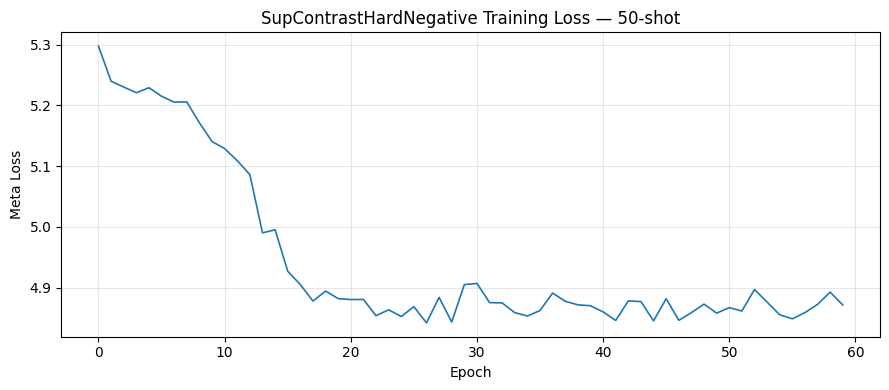

Saved: D:\SEM_7\SpeechProc\PRoject\plots\training_loss_50shot.png


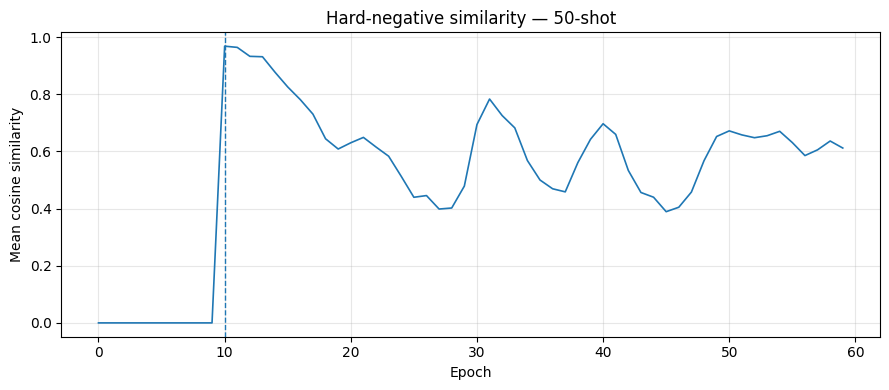

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_HardSupCon_hard_negative_similarity_50shot.png


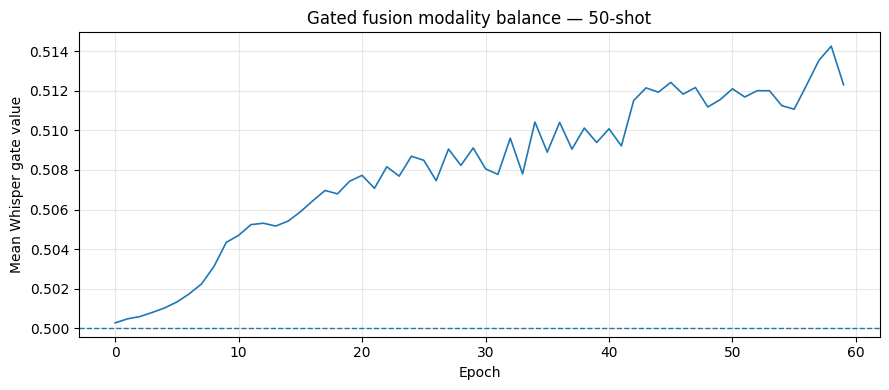

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_GatedFusion_gate_50shot.png


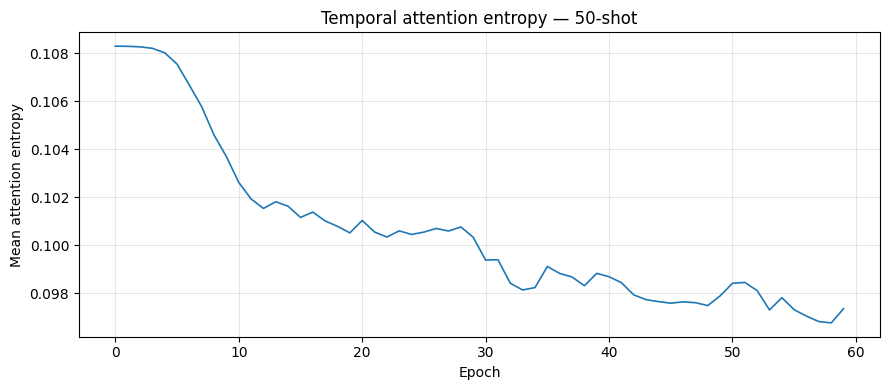

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_HardSupCon_attention_entropy_50shot.png

ATTENTION-POOLED TRAINING — 100-SHOT

Support language distribution:
Bengali      : 100
Bhojpuri     : 100
Gujarati     : 100
Haryanvi     : 100
Hindi        : 100
Kannada      : 100
Malayalam    : 100
Odia         : 100
Punjabi      : 100
Tamil        : 100
Number of languages: 10
Support samples : 1000
Query samples   : 7093
Combined input dimension: 1076
Class 0 support : 500
Class 1 support : 500

Prediction head : SupContrastHardNegative
Input dimension  : 1076
Attention-SupCon training samples: 1000
Class 0: 500
Class 1: 500
AttnHardSupCon Epoch   1/60 | WARMUP   | Loss=5.22647 | HardSim=0.0000 | Hard/anchor=0.00 | AttnEntropy=0.1083 | GateMean=0.5014 | Batches=10
AttnHardSupCon Epoch  10/60 | WARMUP   | Loss=5.02874 | HardSim=0.0000 | Hard/anchor=0.00 | AttnEntropy=0.0982 | GateMean=0.5080 | Batches=10
AttnHardSupCon Epoch  20/60 | HARD-NEG | Loss=4.81898 | HardSim=0.7257 | Hard/ancho

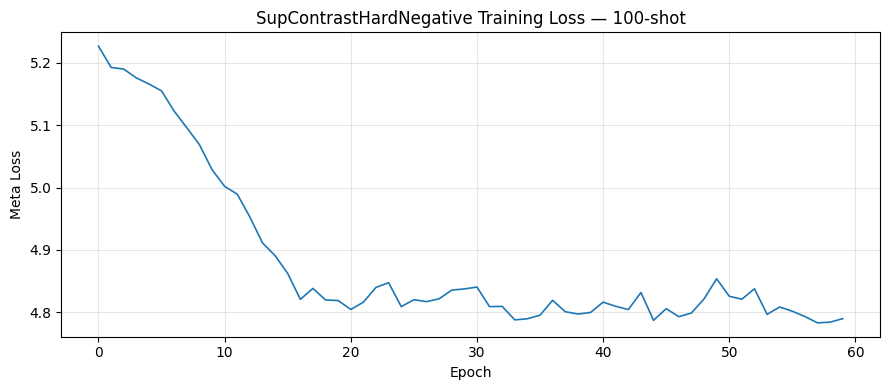

Saved: D:\SEM_7\SpeechProc\PRoject\plots\training_loss_100shot.png


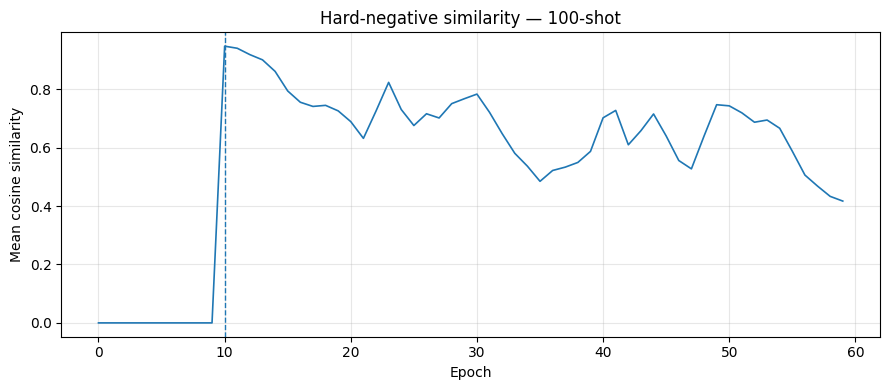

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_HardSupCon_hard_negative_similarity_100shot.png


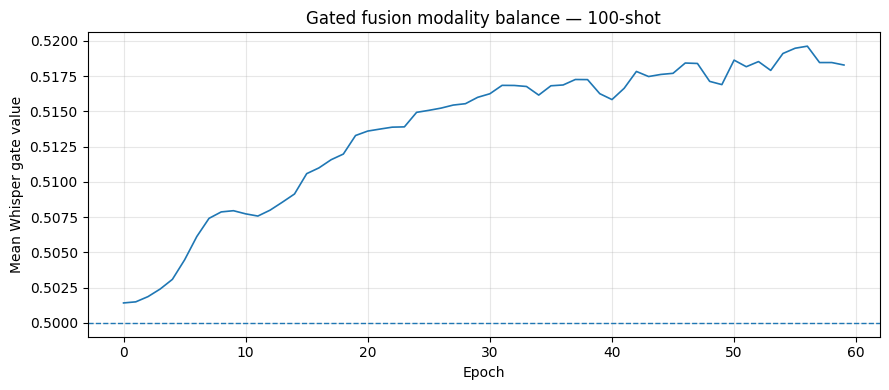

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_GatedFusion_gate_100shot.png


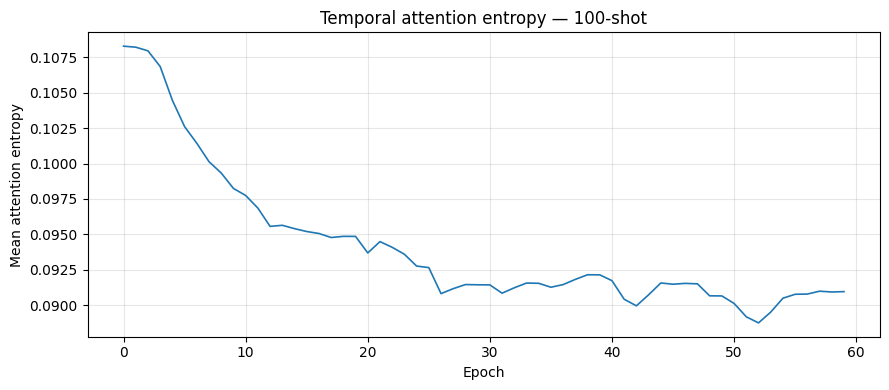

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_HardSupCon_attention_entropy_100shot.png

ATTENTION-POOLED TRAINING — 150-SHOT

Support language distribution:
Bengali      : 150
Bhojpuri     : 150
Gujarati     : 150
Haryanvi     : 150
Hindi        : 150
Kannada      : 150
Malayalam    : 150
Odia         : 150
Punjabi      : 150
Tamil        : 150
Number of languages: 10
Support samples : 1500
Query samples   : 6593
Combined input dimension: 1076
Class 0 support : 750
Class 1 support : 750

Prediction head : SupContrastHardNegative
Input dimension  : 1076
Attention-SupCon training samples: 1500
Class 0: 750
Class 1: 750
AttnHardSupCon Epoch   1/60 | WARMUP   | Loss=5.21981 | HardSim=0.0000 | Hard/anchor=0.00 | AttnEntropy=0.1083 | GateMean=0.5002 | Batches=14
AttnHardSupCon Epoch  10/60 | WARMUP   | Loss=4.97882 | HardSim=0.0000 | Hard/anchor=0.00 | AttnEntropy=0.0972 | GateMean=0.5063 | Batches=14
AttnHardSupCon Epoch  20/60 | HARD-NEG | Loss=4.81650 | HardSim=0.7176 | Hard/anch

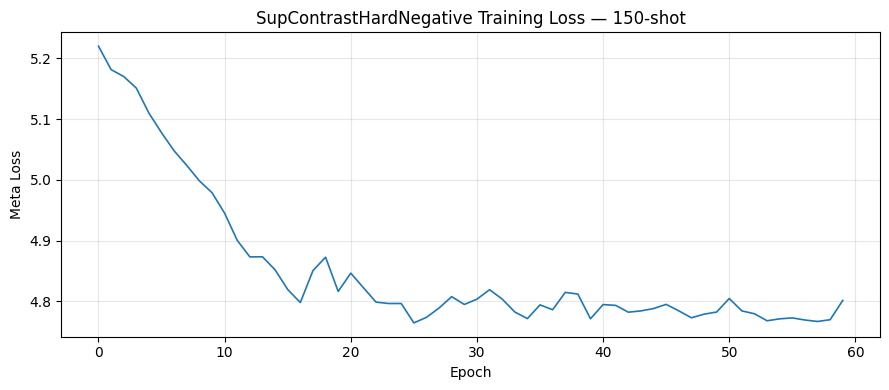

Saved: D:\SEM_7\SpeechProc\PRoject\plots\training_loss_150shot.png


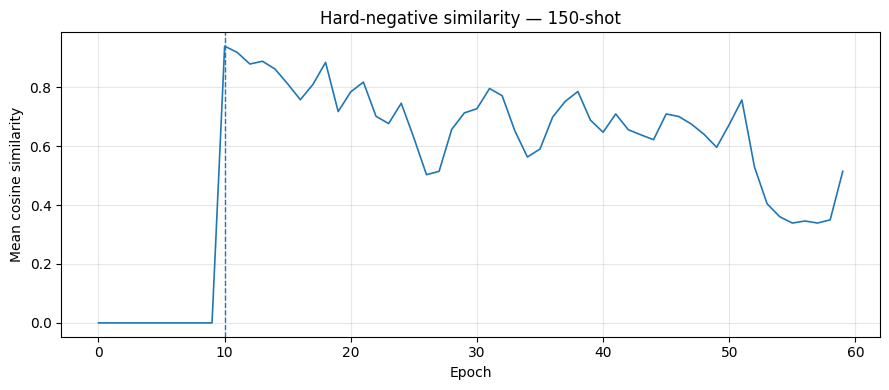

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_HardSupCon_hard_negative_similarity_150shot.png


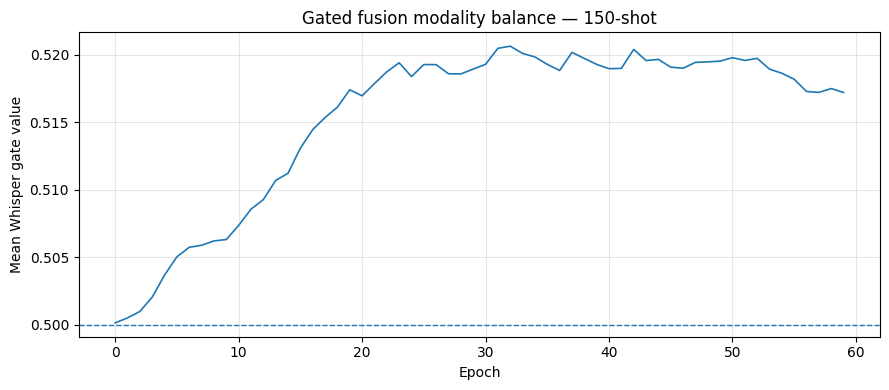

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_GatedFusion_gate_150shot.png


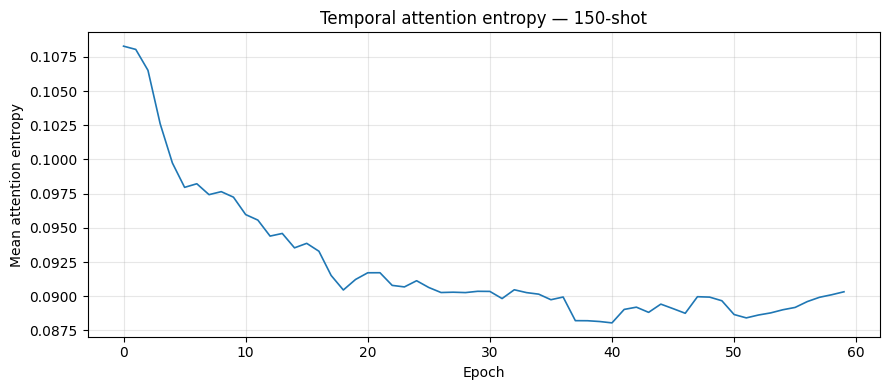

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_HardSupCon_attention_entropy_150shot.png

ATTENTION-POOLED TRAINING — 200-SHOT

Support language distribution:
Bengali      : 200
Bhojpuri     : 200
Gujarati     : 200
Haryanvi     : 200
Hindi        : 200
Kannada      : 200
Malayalam    : 200
Odia         : 200
Punjabi      : 200
Tamil        : 200
Number of languages: 10
Support samples : 2000
Query samples   : 6093
Combined input dimension: 1076
Class 0 support : 1000
Class 1 support : 1000

Prediction head : SupContrastHardNegative
Input dimension  : 1076
Attention-SupCon training samples: 2000
Class 0: 1000
Class 1: 1000
AttnHardSupCon Epoch   1/60 | WARMUP   | Loss=5.19313 | HardSim=0.0000 | Hard/anchor=0.00 | AttnEntropy=0.1083 | GateMean=0.5002 | Batches=18
AttnHardSupCon Epoch  10/60 | WARMUP   | Loss=5.00256 | HardSim=0.0000 | Hard/anchor=0.00 | AttnEntropy=0.0924 | GateMean=0.5100 | Batches=18
AttnHardSupCon Epoch  20/60 | HARD-NEG | Loss=4.85139 | HardSim=0.8540 | Hard/

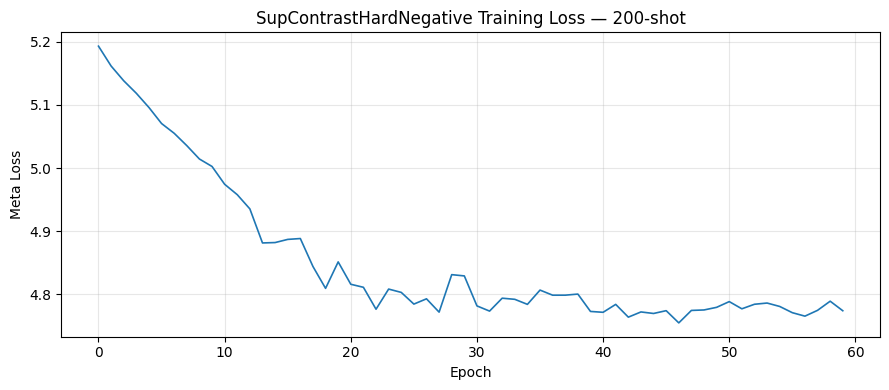

Saved: D:\SEM_7\SpeechProc\PRoject\plots\training_loss_200shot.png


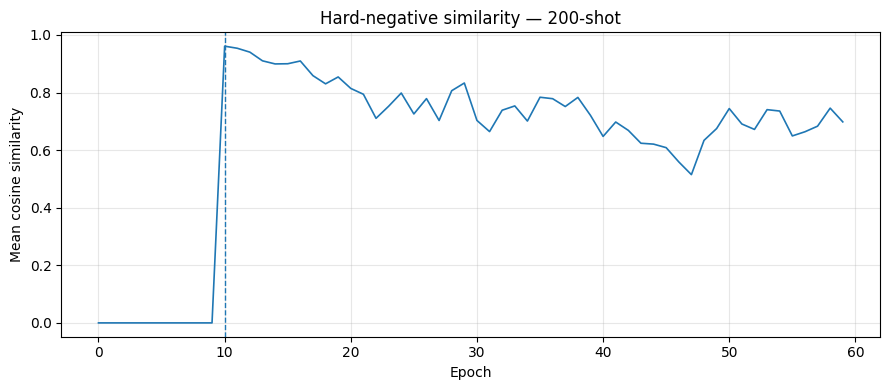

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_HardSupCon_hard_negative_similarity_200shot.png


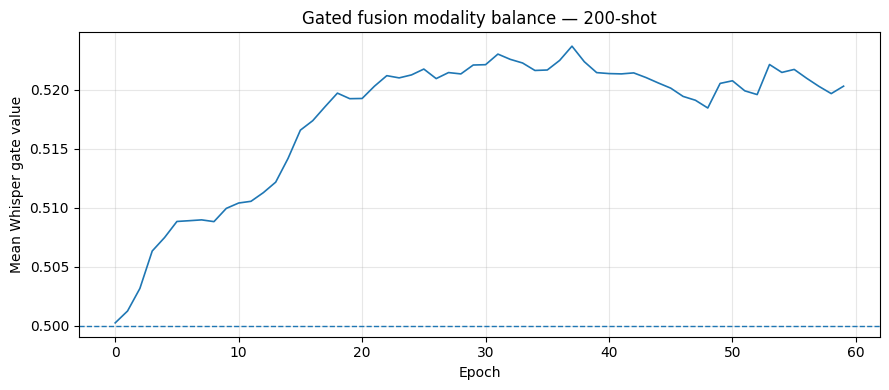

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_GatedFusion_gate_200shot.png


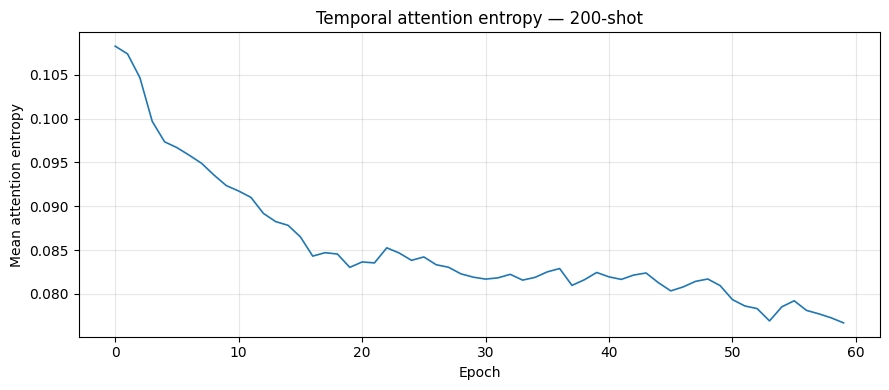

Saved: D:\SEM_7\SpeechProc\PRoject\plots\AttentionPool_HardSupCon_attention_entropy_200shot.png


TRAINING COMPLETE
50-shot : 2.21 min
100-shot : 3.75 min
150-shot : 7.10 min
200-shot : 8.94 min


EVALUATION — 50-SHOT
Bengali      | Accuracy =  80.12% | Macro-F1 =  78.82% | N = 322
Bhojpuri     | Accuracy =  79.43% | Macro-F1 =  76.19% | N = 282
Gujarati     | Accuracy =  75.52% | Macro-F1 =  74.47% | N = 286
Haryanvi     | Accuracy =  81.53% | Macro-F1 =  81.42% | N = 287
Hindi        | Accuracy =  85.25% | Macro-F1 =  85.14% | N = 305
Kannada      | Accuracy =  77.70% | Macro-F1 =  77.05% | N = 296
Malayalam    | Accuracy =  85.09% | Macro-F1 =  83.79% | N = 275
Odia         | Accuracy =  76.74% | Macro-F1 =  76.74% | N = 288
Punjabi      | Accuracy =  79.48% | Macro-F1 =  78.55% | N = 307
Tamil        | Accuracy =  77.05% | Macro-F1 =  75.12% | N = 305


EVALUATION — 100-SHOT
Bengali      | Accuracy =  78.26% | Macro-F1 =  77.53% | N = 322
Bhojpuri     | Accuracy =  78.01% | Macro-F

,Language,Shot,N_test,Accuracy,Macro_F1,NonAbusive_F1,Abusive_F1
0,Bengali,50,322,80.12,78.82,73.55,84.08
1,Bhojpuri,50,282,79.43,76.19,67.42,84.97
2,Gujarati,50,286,75.52,74.47,79.65,69.30
3,Haryanvi,50,287,81.53,81.42,80.00,82.85
4,Hindi,50,305,85.25,85.14,83.87,86.40
5,Kannada,50,296,77.70,77.05,80.92,73.17
6,Malayalam,50,275,85.09,83.79,88.39,79.19
7,Odia,50,288,76.74,76.74,76.82,76.66
8,Punjabi,50,307,79.48,78.55,74.07,83.02
9,Tamil,50,305,77.05,75.12,82.05,68.18



Accuracy (%) by language and shot:


Shot,50,100,150,200
Language,,,,
Bengali,80.12,78.26,81.68,83.54
Bhojpuri,79.43,78.01,78.37,79.08
Gujarati,75.52,76.92,80.77,73.43
Haryanvi,81.53,83.28,85.71,87.11
Hindi,85.25,85.90,87.87,89.18
Kannada,77.70,76.01,80.74,80.07
Malayalam,85.09,80.73,82.55,84.36
Odia,76.74,80.21,79.86,79.17
Punjabi,79.48,83.06,86.64,88.27



Macro-F1 (%) by language and shot:


Shot,50,100,150,200
Language,,,,
Bengali,78.82,77.53,81.04,82.37
Bhojpuri,76.19,75.40,76.09,75.08
Gujarati,74.47,76.36,79.35,72.84
Haryanvi,81.42,83.19,85.70,87.05
Hindi,85.14,85.81,87.86,89.11
Kannada,77.05,76.01,80.47,79.97
Malayalam,83.79,79.62,80.07,83.14
Odia,76.74,80.21,79.74,79.10
Punjabi,78.55,82.81,86.50,87.91


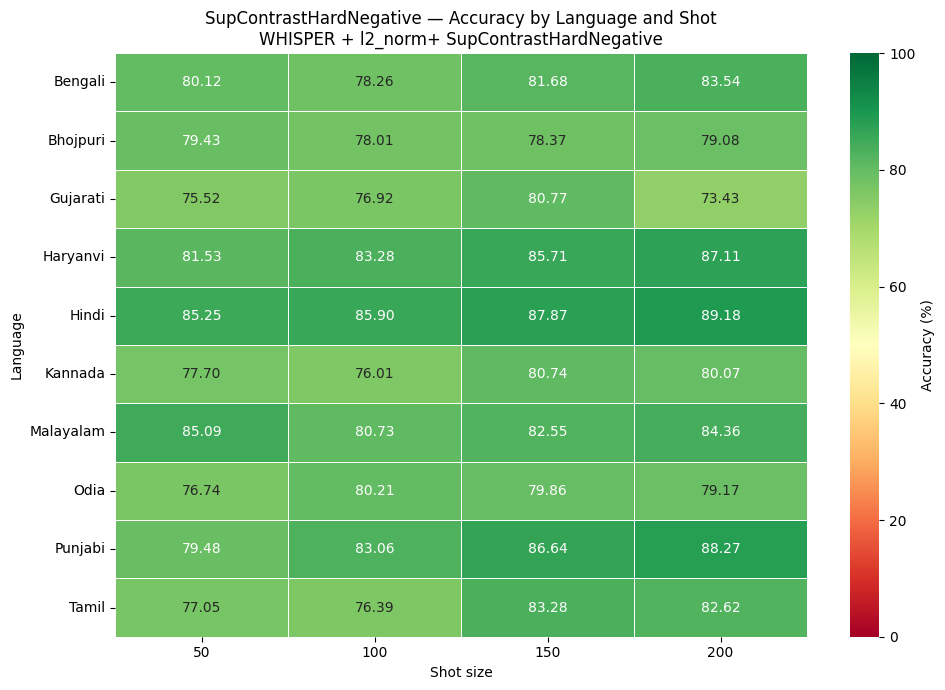

Saved: D:\SEM_7\SpeechProc\PRoject\plots\whisper_AttentionPool_HardSupCon_accuracy_by_language_shot.png


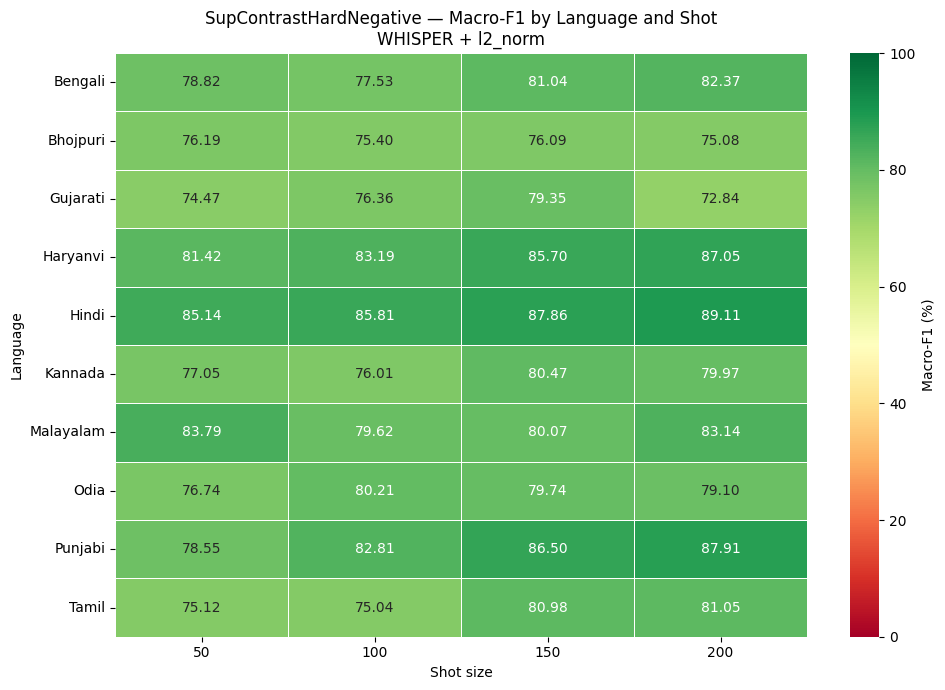

Saved: D:\SEM_7\SpeechProc\PRoject\plots\whisper_l2_norm_SupContrastHardNegative_macro_f1_by_language_shot.png


OVERALL SHOT PERFORMANCE


,Shot,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1,Std_Macro_F1
0,50,79.791,3.344563,78.729,3.626784
1,100,79.877,3.346375,79.198,3.750807
2,150,82.747,3.110391,81.780,3.695066
3,200,82.683,4.880155,81.762,5.344552



Best Accuracy:
  Language : Hindi
  Shot     : 200
  Accuracy : 89.18%

Best Macro-F1:
  Language : Hindi
  Shot     : 200
  Macro-F1 : 89.11%


COMPLETE PIPELINE FINISHED
Mode              : MODE_2
Head              : SupContrastHardNegative
Encoder           : openai/whisper-medium
Normalization     : l2_norm
Train samples     : 8093
Test samples      : 2953
Languages         : 10
Shot sizes        : [50, 100, 150, 200]
Average Accuracy  : 81.27%
Average Macro-F1  : 80.37%


In [ ]:
# ---------------------------------------------------------------------------
# RUN CURRENT SHOT
# ---------------------------------------------------------------------------

if RUN_ALL_SHOTS:

    print(
        "\nRunning all paper shot sizes:"
    )

    print(
        SHOT_SIZES
    )

else:

    print(
        f"\nRunning only {SHOT_K}-shot"
    )


# Store trained models
trained_runs = {}

shots_to_run = (
    SHOT_SIZES
    if RUN_ALL_SHOTS
    else [SHOT_K]
)


for shot in shots_to_run:

    trained_runs[
        shot
    ] = train_one_shot(
        shot
    )


print("\n")
print("=" * 80)
print("TRAINING COMPLETE")
print("=" * 80)

for shot, run in trained_runs.items():

    print(
        f"{shot}-shot : "
        f"{run['training_time_sec']/60:.2f} min"
    )
    

# ═══════════════════════════════════════════════════════════════════════════
# ═══════════════════════════════════════════════════════════════════════════


LANG_ID_MAP = {
    language: idx
    for idx, language in enumerate(
        LANGUAGES
    )
}


# ═══════════════════════════════════════════════════════════════════════════
# EVALUATE ONE LANGUAGE
# ═══════════════════════════════════════════════════════════════════════════

def evaluate_language(
    head,
    language,
    shot_k,
):

    lang_idx = (
        LANG_ID_MAP[
            language
        ]
    )

    mask = (
        test_lang_ids
        == lang_idx
    )

    if mask.sum() == 0:

        print(
            f"[WARNING] "
            f"No test samples: "
            f"{language}"
        )

        return None


    language_embeddings = torch.tensor(
        fewshot_test_embs[mask],
        dtype=torch.float32,
    )

    language_labels = torch.tensor(
        test_labels[mask],
        dtype=torch.long,
    )


    language_indices = np.where(mask)[0]
    language_frame_paths = [
        test_frame_paths[int(i)]
        for i in language_indices
    ]

    metrics = head.evaluate(
        language_embeddings,
        language_labels,
        query_frames=language_frame_paths,
    )


    predictions = head.predict(
        language_embeddings,
        query_frames=language_frame_paths,
    )

    truth = (
        language_labels
        .numpy()
    )


    # ---------------------------------------------------------------
    # Classification report
    # ---------------------------------------------------------------

    report = classification_report(
        truth,
        predictions,
        labels=[0, 1],
        target_names=[
            "Non-Abusive",
            "Abusive"
        ],
        output_dict=True,
        zero_division=0,
    )


    return {

        "Language":
            language,

        "Shot":
            shot_k,

        "N_test":
            int(mask.sum()),

        "Accuracy":
            metrics["accuracy"],

        "Macro_F1":
            metrics["macro_f1"],

        "NonAbusive_F1":
            report[
                "Non-Abusive"
            ]["f1-score"],

        "Abusive_F1":
            report[
                "Abusive"
            ]["f1-score"],

        "Predictions":
            predictions,

        "Truth":
            truth,
    }


# ═══════════════════════════════════════════════════════════════════════════
# EVALUATE ALL LANGUAGES
# ═══════════════════════════════════════════════════════════════════════════

def evaluate_one_shot(
    run,
    shot_k,
):

    head = run["head"]

    print("\n")
    print("=" * 80)

    print(
        f"EVALUATION — "
        f"{shot_k}-SHOT"
    )

    print("=" * 80)

    rows = []

    for language in LANGUAGES:

        result = evaluate_language(
            head,
            language,
            shot_k,
        )

        if result is None:
            continue

        print(
            f"{language:12s} | "
            f"Accuracy = "
            f"{result['Accuracy']:6.2f}% | "
            f"Macro-F1 = "
            f"{result['Macro_F1']:6.2f}% | "
            f"N = {result['N_test']}"
        )

        rows.append({

            "Language":
                result["Language"],

            "Shot":
                result["Shot"],

            "N_test":
                result["N_test"],

            "Accuracy":
                round(
                    result["Accuracy"],
                    2
                ),

            "Macro_F1":
                round(
                    result["Macro_F1"],
                    2
                ),

            "NonAbusive_F1":
                round(
                    result["NonAbusive_F1"] * 100,
                    2
                ),

            "Abusive_F1":
                round(
                    result["Abusive_F1"] * 100,
                    2
                ),
        })


    results = pd.DataFrame(
        rows
    )

    return results


# ═══════════════════════════════════════════════════════════════════════════
# RUN EVERY SHOT
# ═══════════════════════════════════════════════════════════════════════════

all_results = []


for shot, run in trained_runs.items():

    shot_results = (
        evaluate_one_shot(
            run,
            shot
        )
    )

    all_results.append(
        shot_results
    )


all_results_df = pd.concat(
    all_results,
    ignore_index=True
)


# ═══════════════════════════════════════════════════════════════════════════
# SAVE COMPLETE RESULTS
# ═══════════════════════════════════════════════════════════════════════════

complete_results_path = (
    RESULTS_DIR /
    f"complete_results_{ENCODER_TYPE}_AttentionPool_HardSupCon_{NORM_STRATEGY}.csv"
)

all_results_df.to_csv(
    complete_results_path,
    index=False
)

print(
    f"\nComplete results saved: "
    f"{complete_results_path}"
)


# ═══════════════════════════════════════════════════════════════════════════
# DISPLAY RESULT TABLE
# ═══════════════════════════════════════════════════════════════════════════

print("\n")
print("=" * 80)
print("COMPLETE RESULTS")
print("=" * 80)

display(
    all_results_df
)


# ═══════════════════════════════════════════════════════════════════════════
# ACCURACY TABLE
# ═══════════════════════════════════════════════════════════════════════════

accuracy_table = (
    all_results_df
    .pivot(
        index="Language",
        columns="Shot",
        values="Accuracy"
    )
)

print(
    "\nAccuracy (%) by language and shot:"
)

display(
    accuracy_table
)


# ═══════════════════════════════════════════════════════════════════════════
# MACRO F1 TABLE
# ═══════════════════════════════════════════════════════════════════════════

f1_table = (
    all_results_df
    .pivot(
        index="Language",
        columns="Shot",
        values="Macro_F1"
    )
)

print(
    "\nMacro-F1 (%) by language and shot:"
)

display(
    f1_table
)


# ═══════════════════════════════════════════════════════════════════════════
# HEATMAP — ACCURACY
# ═══════════════════════════════════════════════════════════════════════════

plt.figure(
    figsize=(10, 7)
)

sns.heatmap(
    accuracy_table,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={
        "label": "Accuracy (%)"
    },
)

plt.title(
    f"{get_active_head_name()} — "
    f"Accuracy by Language and Shot\n"
    f"{ENCODER_TYPE.upper()} + {NORM_STRATEGY}+ {MODE_2_HEAD}"
)

plt.xlabel(
    "Shot size"
)

plt.ylabel(
    "Language"
)

plt.tight_layout()

accuracy_heatmap_path = (
    PLOTS_DIR /
    f"{ENCODER_TYPE}_AttentionPool_HardSupCon_accuracy_by_language_shot.png"
)

plt.savefig(
    accuracy_heatmap_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {accuracy_heatmap_path}"
)


# ═══════════════════════════════════════════════════════════════════════════
# HEATMAP — MACRO F1
# ═══════════════════════════════════════════════════════════════════════════

plt.figure(
    figsize=(10, 7)
)

sns.heatmap(
    f1_table,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={
        "label": "Macro-F1 (%)"
    },
)

plt.title(
    f"{get_active_head_name()} — "
    f"Macro-F1 by Language and Shot\n"
    f"{ENCODER_TYPE.upper()} + {NORM_STRATEGY}"
)

plt.xlabel(
    "Shot size"
)

plt.ylabel(
    "Language"
)

plt.tight_layout()

f1_heatmap_path = (
    PLOTS_DIR /
    f"{ENCODER_TYPE}_{NORM_STRATEGY}_{MODE_2_HEAD}_macro_f1_by_language_shot.png"
)

plt.savefig(
    f1_heatmap_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {f1_heatmap_path}"
)


# ═══════════════════════════════════════════════════════════════════════════
# OVERALL SHOT PERFORMANCE
# ═══════════════════════════════════════════════════════════════════════════

shot_summary = (
    all_results_df
    .groupby("Shot")
    .agg(
        Mean_Accuracy=(
            "Accuracy",
            "mean"
        ),
        Std_Accuracy=(
            "Accuracy",
            "std"
        ),
        Mean_Macro_F1=(
            "Macro_F1",
            "mean"
        ),
        Std_Macro_F1=(
            "Macro_F1",
            "std"
        ),
    )
    .reset_index()
)

print("\n")
print("=" * 80)
print("OVERALL SHOT PERFORMANCE")
print("=" * 80)

display(
    shot_summary
)


# ═══════════════════════════════════════════════════════════════════════════
# BEST LANGUAGE / SHOT
# ═══════════════════════════════════════════════════════════════════════════

best_accuracy_row = (
    all_results_df.loc[
        all_results_df[
            "Accuracy"
        ].idxmax()
    ]
)

best_f1_row = (
    all_results_df.loc[
        all_results_df[
            "Macro_F1"
        ].idxmax()
    ]
)

print(
    "\nBest Accuracy:"
)

print(
    f"  Language : "
    f"{best_accuracy_row['Language']}"
)

print(
    f"  Shot     : "
    f"{best_accuracy_row['Shot']}"
)

print(
    f"  Accuracy : "
    f"{best_accuracy_row['Accuracy']:.2f}%"
)

print(
    "\nBest Macro-F1:"
)

print(
    f"  Language : "
    f"{best_f1_row['Language']}"
)

print(
    f"  Shot     : "
    f"{best_f1_row['Shot']}"
)

print(
    f"  Macro-F1 : "
    f"{best_f1_row['Macro_F1']:.2f}%"
)


# ═══════════════════════════════════════════════════════════════════════════
# FINAL SUMMARY
# ═══════════════════════════════════════════════════════════════════════════

print("\n")
print("=" * 80)
print("COMPLETE PIPELINE FINISHED")
print("=" * 80)

print(
    f"Mode              : {MODE}"
)

print(
    f"Head              : "
    f"{get_active_head_name()}"
)

print(
    f"Encoder           : "
    f"{ENCODER_MODEL_ID}"
)

print(
    f"Normalization     : "
    f"{NORM_STRATEGY}"
)

print(
    f"Train samples     : "
    f"{len(train_embs)}"
)

print(
    f"Test samples      : "
    f"{len(test_embs)}"
)

print(
    f"Languages         : "
    f"{NUM_LANGUAGES}"
)

print(
    f"Shot sizes        : "
    f"{shots_to_run}"
)

print(
    f"Average Accuracy  : "
    f"{all_results_df['Accuracy'].mean():.2f}%"
)

print(
    f"Average Macro-F1  : "
    f"{all_results_df['Macro_F1'].mean():.2f}%"
)

print("=" * 80)


## Expected outputs

The notebook saves the attention-pooled Gated-Fusion Hard-SupCon results separately from the mean-pooling baseline, including the complete language × shot CSV, accuracy/F1 tables, hard-negative similarity plot, attention-entropy plot, and gated-fusion gate plot.

For the scientific comparison, keep the same shot episodes/seeds as the mean-pooling baseline and compare 50/100/150/200 shots using Accuracy and Macro-F1.
